# Red Neuronal MLP para PM10 y PM2.5 — protocolo temporal para tesis

Se evalúan **60/40, 70/30, 80/20 y 90/10**, además de horizontes reales de **7, 30 y 90 días**. La arquitectura y regularización se seleccionan con validación temporal; el escalado se ajusta dentro de cada fold y se desactiva la validación interna aleatoria de `early_stopping`.

Cada intervalo produce una figura con entrenamiento, prueba real y predicción en el panel superior, y el residual `Real − Predicción` en el panel inferior.


In [1]:
# ============================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# ============================================================

import time
from datetime import datetime

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-08-13 00:50:15


In [2]:
# ============================================================
# IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import os
import re
import gc
import glob
import time
import warnings
from pathlib import Path
from functools import reduce
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
plt.rcParams["figure.figsize"] = (13, 5)

SEED = 42
np.random.seed(SEED)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [3]:
# ============================================================
# CONFIGURACIÓN DE CARGA E INTEGRACIÓN DE LOS NUEVOS DATOS
# ============================================================

CIUDAD_ANALISIS = "NUEVOS_DATOS_IMPUTADOS"
TARGETS_A_EVALUAR = ["PM10", "PM25"]

# Covariables candidatas para inventario/diagnóstico.
# El protocolo de modelado utilizará únicamente las columnas realmente disponibles.
COVARIABLES_CANDIDATAS = [
    "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10",
    "TMPR_AIR_10CM", "P", "RGlobal", "PLiquida", "RUVb"
]

# Se recomienda integrar los archivos finales actuales en lugar de reutilizar
# automáticamente una base maestra antigua.
USAR_BASE_MAESTRA_SI_EXISTE = False
ESTACIONES_SELECCIONADAS = None

# Salidas de la etapa de integración. El protocolo de tesis crea después
# una carpeta independiente para resultados de modelado.
OUT_DIR = f"preparacion_MLP_{CIUDAD_ANALISIS}"
TABLAS_DIR = Path(OUT_DIR) / "tablas"
GRAFICAS_DIR = Path(OUT_DIR) / "graficas"
MODELOS_DIR = Path(OUT_DIR) / "modelos"

for carpeta in [OUT_DIR, TABLAS_DIR, GRAFICAS_DIR, MODELOS_DIR]:
    Path(carpeta).mkdir(parents=True, exist_ok=True)

display(Markdown("## Configuración de carga"))
display(pd.DataFrame([{
    "Etiqueta_analisis": CIUDAD_ANALISIS,
    "Targets": str(TARGETS_A_EVALUAR),
    "Covariables_candidatas": str(COVARIABLES_CANDIDATAS),
    "Usar_base_maestra_previa": USAR_BASE_MAESTRA_SI_EXISTE,
    "Salida_preparacion": OUT_DIR
}]))


## Configuración de carga

,Etiqueta_analisis,Targets,Covariables_candidatas,Usar_base_maestra_previa,Salida_preparacion
0,NUEVOS_DATOS_IMPUTADOS,"['PM10', 'PM25']","['DViento', 'VViento', 'HAire2', 'HAire10', 'T...",False,preparacion_MLP_NUEVOS_DATOS_IMPUTADOS


In [4]:
# ============================================================
# RUTAS DE TRABAJO Y BÚSQUEDA ROBUSTA DE NUEVOS ARCHIVOS
# ============================================================

BASE_DIR = Path(".")

# Archivos específicos que se usarán en este modelado.
# El notebook prioriza estos archivos sobre cualquier otro CSV que exista en la carpeta.
ARCHIVOS_ESPECIFICOS_MODELO = [
    "DViento_dataset_completo_final_con_atipicos.csv",
    "HAire2_dataset_completo_final_con_atipicos.csv",
    "PLiquida_dataset_completo_final_con_atipicos.csv",
    "PM10_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv",
    "PM25_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv",
    "RGlobal_dataset_completo_final_con_atipicos.csv",
    "TAire2_dataset_completo_final_con_atipicos.csv",
    "VViento_dataset_completo_final_con_atipicos.csv",
]

# Archivos que NO deben entrar al modelo.
# Son reportes auxiliares, tiempos de ejecución, métricas, predicciones, etc.
PALABRAS_EXCLUIR_ARCHIVOS = [
    "metricas",
    "predicciones",
    "hiperparametros",
    "configuracion",
    "comparativo",
    "importancia",
    "importancias",
    "validacion",
    "resumen",
    "tabla_",
    "r2_",
    "tiempo",
    "errores",
    "diagnostico",
    "historial",
    "sobreajuste",
    "salidas",
    "output",
]

PATRONES_BASE_MAESTRA = [
    f"base_maestra_calidad_aire_modelado_MLP_{CIUDAD_ANALISIS}.csv",
    f"base_maestra_calidad_aire_modelado_{CIUDAD_ANALISIS}.csv",
    "base_maestra_calidad_aire_modelado.csv",
    "base_maestra_calidad_aire_modelado_MLP.csv",
    "*base*maestra*calidad*aire*modelado*.csv",
    "*base*maestra*.csv",
]

PATRONES_ARCHIVOS_DATOS = [
    "*DATASET_FINAL_IMPUTADO*.csv",
    "*DATASET_FINAL_IMPUTADO*.xlsx",
    "*DATASET_FINAL_IMPUTADO*.xls",
    "*dataset*final*imputado*.csv",
    "*dataset*final*imputado*.xlsx",
    "*resultado_final_imputado*.csv",
    "*resultado_final_imputado*.xlsx",
    "*dataset_completo_final_con_atipicos*.csv",
    "*dataset_completo_final_con_atipicos*.xlsx",
    "*dataset_completo_final*.csv",
    "*dataset_completo_final*.xlsx",
    "PM10*.csv",
    "PM10*.xlsx",
    "PM25*.csv",
    "PM25*.xlsx",
    "PM2.5*.csv",
    "PM2.5*.xlsx",
    "DViento*.csv",
    "DViento*.xlsx",
    "VViento*.csv",
    "VViento*.xlsx",
    "HAire2*.csv",
    "HAire2*.xlsx",
    "HAire10*.csv",
    "HAire10*.xlsx",
    "TAire2*.csv",
    "TAire2*.xlsx",
    "TAire10*.csv",
    "TAire10*.xlsx",
    "TMPR*.csv",
    "TMPR*.xlsx",
    "RGlobal*.csv",
    "RGlobal*.xlsx",
    "PLiquida*.csv",
    "PLiquida*.xlsx",
]

def buscar_un_archivo(patrones):
    encontrados = []
    for patron in patrones:
        encontrados.extend(sorted(BASE_DIR.glob(patron)))

    unicos = []
    vistos = set()
    for ruta in encontrados:
        ruta_txt = str(ruta)
        if ruta_txt not in vistos:
            unicos.append(ruta)
            vistos.add(ruta_txt)

    if unicos:
        return str(unicos[0])
    return None

def archivo_valido_modelo(ruta):
    nombre = ruta.name.lower()
    return not any(palabra in nombre for palabra in PALABRAS_EXCLUIR_ARCHIVOS)

def buscar_archivos_datos(patrones):
    # 1. Prioridad absoluta: los 8 archivos específicos seleccionados por el usuario.
    especificos = []
    for nombre in ARCHIVOS_ESPECIFICOS_MODELO:
        ruta = BASE_DIR / nombre
        if ruta.exists() and ruta.is_file() and archivo_valido_modelo(ruta):
            especificos.append(ruta)

    if especificos:
        return especificos

    # 2. Si no están los específicos, usar búsqueda amplia.
    encontrados = []
    for patron in patrones:
        encontrados.extend(sorted(BASE_DIR.glob(patron)))

    unicos = []
    vistos = set()

    for ruta in encontrados:
        if not ruta.is_file():
            continue

        if not archivo_valido_modelo(ruta):
            continue

        ruta_txt = str(ruta)
        if ruta_txt not in vistos:
            unicos.append(ruta)
            vistos.add(ruta_txt)

    return unicos

PATH_BASE_MAESTRA = buscar_un_archivo(PATRONES_BASE_MAESTRA)
ARCHIVOS_DATOS = buscar_archivos_datos(PATRONES_ARCHIVOS_DATOS)

print("Base maestra detectada:", PATH_BASE_MAESTRA)
print("Usar base maestra existente:", USAR_BASE_MAESTRA_SI_EXISTE)

print("\nArchivos específicos esperados:")
for nombre in ARCHIVOS_ESPECIFICOS_MODELO:
    ruta = BASE_DIR / nombre
    print(nombre, "->", "ENCONTRADO" if ruta.exists() else "NO ENCONTRADO")

print("\nArchivos de datos que entrarán al modelo:")
if ARCHIVOS_DATOS:
    for ruta in ARCHIVOS_DATOS:
        print("-", ruta)
else:
    print("No se detectaron archivos de datos con los patrones configurados.")

# Validación explícita para evitar que entre un archivo de tiempo.
archivos_invalidos = [ruta for ruta in ARCHIVOS_DATOS if not archivo_valido_modelo(ruta)]
if archivos_invalidos:
    raise ValueError(f"Se detectaron archivos no válidos para modelado: {archivos_invalidos}")

Base maestra detectada: None
Usar base maestra existente: False

Archivos específicos esperados:
DViento_dataset_completo_final_con_atipicos.csv -> ENCONTRADO
HAire2_dataset_completo_final_con_atipicos.csv -> ENCONTRADO
PLiquida_dataset_completo_final_con_atipicos.csv -> ENCONTRADO
PM10_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv -> ENCONTRADO
PM25_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv -> ENCONTRADO
RGlobal_dataset_completo_final_con_atipicos.csv -> ENCONTRADO
TAire2_dataset_completo_final_con_atipicos.csv -> ENCONTRADO
VViento_dataset_completo_final_con_atipicos.csv -> ENCONTRADO

Archivos de datos que entrarán al modelo:
- DViento_dataset_completo_final_con_atipicos.csv
- HAire2_dataset_completo_final_con_atipicos.csv
- PLiquida_dataset_completo_final_con_atipicos.csv
- PM10_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv
- PM25_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv
- RGlobal_dataset_completo_final_con_atipicos.csv
- TAire2_dataset_completo_final_con_atipicos.csv
- VViento_dataset_completo_f

In [5]:
# ============================================================
# FUNCIONES AUXILIARES ROBUSTAS PARA CARGA E INTEGRACIÓN
# ============================================================

def limpiar_nombre_columna(col):
    """
    Limpia espacios, BOM y saltos innecesarios en nombres de columnas.
    """
    col = str(col).replace("\ufeff", "").strip()
    col = re.sub(r"\s+", " ", col)
    return col


def normalizar_texto_columna(txt):
    """
    Normaliza texto para comparar nombres de columnas sin depender de puntos,
    guiones, espacios, tildes o mayúsculas.
    """
    txt = limpiar_nombre_columna(txt).lower()
    reemplazos = {
        "á": "a", "é": "e", "í": "i", "ó": "o", "ú": "u", "ñ": "n"
    }

    for a, b in reemplazos.items():
        txt = txt.replace(a, b)

    for ch in [".", "_", "-", " ", "/", "\\", "(", ")", "[", "]"]:
        txt = txt.replace(ch, "")

    return txt


def load_table(path, sheet_preferida=None):
    """
    Lee archivos CSV, XLSX o XLS y retorna un DataFrame con columnas limpias.
    """
    if path is None:
        raise FileNotFoundError("La ruta recibida es None.")

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {path}")

    def limpiar_columnas(df):
        df = df.copy()
        df.columns = [limpiar_nombre_columna(c) for c in df.columns]
        return df

    suffix = path.suffix.lower()

    if suffix == ".csv":
        try:
            return limpiar_columnas(pd.read_csv(path, encoding="utf-8"))
        except UnicodeDecodeError:
            return limpiar_columnas(pd.read_csv(path, encoding="latin1"))

    if suffix in [".xlsx", ".xls"]:
        excel = pd.ExcelFile(path)
        hojas = excel.sheet_names

        posibles_hojas = [
            sheet_preferida,
            "DATASET_FINAL",
            "dataset_final",
            "PM10_final",
            "PM25_final",
            "PM2.5_final",
            "VViento_final",
            "detalle_completo",
        ]

        hoja = None
        for h in posibles_hojas:
            if h in hojas:
                hoja = h
                break

        if hoja is None:
            hoja = hojas[0]

        return limpiar_columnas(pd.read_excel(path, sheet_name=hoja))

    try:
        return limpiar_columnas(pd.read_csv(path, encoding="utf-8"))
    except UnicodeDecodeError:
        return limpiar_columnas(pd.read_csv(path, encoding="latin1"))


def encontrar_columna(df, alias):
    """
    Busca una columna dentro de un DataFrame usando alias normalizados.
    """
    columnas_norm = {
        normalizar_texto_columna(c): c
        for c in df.columns
    }

    for a in alias:
        a_norm = normalizar_texto_columna(a)
        if a_norm in columnas_norm:
            return columnas_norm[a_norm]

    return None


def alias_variable_base(value_col):
    """
    Alias aceptados para cada variable. Esto permite trabajar con archivos
    exportados por distintos notebooks de imputación.
    """
    alias_map = {
        "PM10": [
            "PM10_final", "PM10_RF_final", "PM10_DATASET_FINAL_IMPUTADO",
            "PM10_limpio_sin_atipicos", "PM10_imputado", "PM10",
            "PM 10", "PM_10", "PM10_original", "PM10_original_crudo"
        ],
        "PM25": [
            "PM25_final", "PM2.5_final", "PM25_RF_final", "PM2.5_RF_final",
            "PM25_DATASET_FINAL_IMPUTADO", "PM2.5_DATASET_FINAL_IMPUTADO",
            "PM25_limpio_sin_atipicos", "PM2.5_limpio_sin_atipicos",
            "PM25_imputado", "PM2.5_imputado",
            "PM25", "PM2.5", "PM 2.5", "PM_2_5", "PM2_5",
            "PM25_original", "PM2.5_original", "PM25_original_crudo", "PM2.5_original_crudo"
        ],
        "DViento": [
            "DViento_final", "DViento_RF_final", "DViento",
            "Direccion viento", "Dirección viento", "Direccion del viento", "Dirección del viento"
        ],
        "VViento": [
            "VViento_final", "VViento_RF_final", "VViento",
            "Velocidad viento", "Velocidad del viento"
        ],
        "HAire2": [
            "HAire2_final", "HAire2_RF_final", "HAire2",
            "H Aire 2", "Humedad Aire 2", "Humedad relativa 2m", "Humedad relativa"
        ],
        "HAire10": [
            "HAire10_final", "HAire10_RF_final", "HAire10",
            "H Aire 10", "Humedad Aire 10", "Humedad relativa 10m"
        ],
        "TAire2": [
            "TAire2_final", "TAire2_RF_final", "TAire2",
            "T Aire 2", "Temperatura Aire 2", "Temperatura 2m"
        ],
        "TAire10": [
            "TAire10_final", "TAire10_RF_final", "TAire10",
            "T Aire 10", "Temperatura Aire 10", "Temperatura 10m"
        ],
        "TMPR_AIR_10CM": [
            "TMPR_AIR_10CM_final", "TMPR_AIR_10CM_RF_final",
            "TMPR_AIR_10CM", "TMPR AIR 10CM", "Temperatura aire 10cm", "TMPR"
        ],
        "P": [
            "P_final", "P_RF_final", "P", "Presion", "Presión",
            "Presion atmosferica", "Presión atmosférica"
        ],
        "RGlobal": [
            "RGlobal_final", "RGlobal_RF_final", "RGlobal",
            "Radiacion global", "Radiación global", "Rad Global"
        ],
        "PLiquida": [
            "PLiquida_final", "PLiquida_RF_final", "PLiquida",
            "P Liquida", "Precipitacion liquida", "Precipitación líquida", "Lluvia"
        ],
    }

    return alias_map.get(value_col, [value_col])


VARIABLES_CANONICAS = [
    "PM10", "PM25",
    "DViento", "VViento",
    "HAire2", "HAire10",
    "TAire2", "TAire10",
    "TMPR_AIR_10CM",
    "P", "RGlobal", "PLiquida"
]


def preparar_archivo_multivariable(df, nombre_archivo=""):
    """
    Extrae de un archivo todas las variables reconocidas disponibles.
    Soporta archivos de una sola variable o archivos multivariables.
    """
    df = df.copy()
    df.columns = [limpiar_nombre_columna(c) for c in df.columns]

    col_est = encontrar_columna(
        df,
        ["Estacion", "Estación", "Nombre de estación", "Nombre estacion", "station", "site", "punto"]
    )
    col_fecha = encontrar_columna(
        df,
        ["Fecha inicial", "Fecha", "fecha", "date", "Date", "Fecha Inicial"]
    )

    if col_est is None or col_fecha is None:
        raise ValueError(
            f"El archivo {nombre_archivo} no tiene columnas reconocibles de estación y fecha. "
            f"Columnas disponibles: {df.columns.tolist()}"
        )

    salida = pd.DataFrame()
    salida["Estacion"] = df[col_est].astype(str).str.strip().str.upper()
    salida["Fecha inicial"] = pd.to_datetime(df[col_fecha], errors="coerce")

    variables_encontradas = []

    for variable in VARIABLES_CANONICAS:
        col_var = encontrar_columna(df, alias_variable_base(variable))
        if col_var is not None:
            salida[variable] = pd.to_numeric(df[col_var], errors="coerce")
            variables_encontradas.append(variable)

    if not variables_encontradas:
        raise ValueError(
            f"El archivo {nombre_archivo} no contiene ninguna variable reconocida. "
            f"Columnas disponibles: {df.columns.tolist()}"
        )

    salida = salida.dropna(subset=["Estacion", "Fecha inicial"])

    cols_num = [
        c for c in salida.columns
        if c not in ["Estacion", "Fecha inicial"]
    ]

    salida = (
        salida
        .groupby(["Estacion", "Fecha inicial"], as_index=False)[cols_num]
        .mean()
        .sort_values(["Estacion", "Fecha inicial"])
        .reset_index(drop=True)
    )

    return salida, variables_encontradas


def preparar_base_maestra_directa(df):
    """
    Prepara una base maestra ya integrada.
    """
    df_preparada, _ = preparar_archivo_multivariable(df, "base_maestra")
    return df_preparada

In [6]:
from IPython.display import display, Markdown

# ============================================================
# CARGA E INTEGRACIÓN ROBUSTA DE NUEVOS DATOS
# ============================================================

if USAR_BASE_MAESTRA_SI_EXISTE and PATH_BASE_MAESTRA is not None:
    print("Cargando base maestra existente:")
    print(PATH_BASE_MAESTRA)
    df_master = preparar_base_maestra_directa(load_table(PATH_BASE_MAESTRA))

    variables_integradas_df = pd.DataFrame([{
        "Archivo": PATH_BASE_MAESTRA,
        "Variables_detectadas": ", ".join([c for c in df_master.columns if c not in ["Estacion", "Fecha inicial"]]),
        "Registros": len(df_master),
        "Estaciones": df_master["Estacion"].nunique(),
        "Fecha_minima": df_master["Fecha inicial"].min(),
        "Fecha_maxima": df_master["Fecha inicial"].max(),
    }])

    errores_carga_df = pd.DataFrame()

else:
    print("No se usó base maestra existente. Se integrarán los nuevos archivos detectados.")

    bases = []
    inventario = []
    errores_carga = []

    for ruta in ARCHIVOS_DATOS:
        try:
            df_archivo = load_table(ruta)
            base_tmp, variables_detectadas = preparar_archivo_multivariable(df_archivo, nombre_archivo=str(ruta))

            bases.append(base_tmp)

            inventario.append({
                "Archivo": str(ruta),
                "Variables_detectadas": ", ".join(variables_detectadas),
                "Registros": len(base_tmp),
                "Estaciones": base_tmp["Estacion"].nunique(),
                "Fecha_minima": base_tmp["Fecha inicial"].min(),
                "Fecha_maxima": base_tmp["Fecha inicial"].max(),
            })

            print(f"OK - {ruta} -> {variables_detectadas}")

        except Exception as e:
            errores_carga.append({
                "Archivo": str(ruta),
                "Error": str(e)
            })
            print(f"No se pudo cargar {ruta}: {e}")

    variables_integradas_df = pd.DataFrame(inventario)
    errores_carga_df = pd.DataFrame(errores_carga)

    if not bases:
        raise FileNotFoundError(
            "No se pudo integrar ningún archivo de datos. "
            "Verifica que los archivos finales imputados estén en la misma carpeta del notebook."
        )

    # Se concatenan y luego se agrupa por estación-fecha.
    # Esto permite que un archivo tenga PM10, otro tenga PM2.5 y otros tengan covariables.
    base_concat = pd.concat(bases, ignore_index=True, sort=False)

    cols_num = [c for c in base_concat.columns if c not in ["Estacion", "Fecha inicial"]]

    df_master = (
        base_concat
        .groupby(["Estacion", "Fecha inicial"], as_index=False)[cols_num]
        .mean()
        .sort_values(["Estacion", "Fecha inicial"])
        .reset_index(drop=True)
    )

display(Markdown("## Inventario de archivos integrados"))
display(variables_integradas_df)

if not errores_carga_df.empty:
    display(Markdown("## Archivos no integrados o con errores"))
    display(errores_carga_df)

# Validación mínima de targets.
targets_en_base = [t for t in TARGETS_A_EVALUAR if t in df_master.columns]
if not targets_en_base:
    raise ValueError(
        "La base integrada no contiene PM10 ni PM25/PM2.5. "
        f"Columnas disponibles: {df_master.columns.tolist()}"
    )

print("Dimensión de la base integrada:", df_master.shape)
display(df_master.head())
display(df_master.tail())

ruta_salida_master = Path(OUT_DIR) / f"base_maestra_calidad_aire_modelado_MLP_{CIUDAD_ANALISIS}.csv"
df_master.to_csv(ruta_salida_master, index=False, encoding="utf-8-sig")
df_master.to_csv(f"base_maestra_calidad_aire_modelado_MLP_{CIUDAD_ANALISIS}.csv", index=False, encoding="utf-8-sig")

variables_integradas_df.to_csv(TABLAS_DIR / "inventario_archivos_integrados_MLP.csv", index=False, encoding="utf-8-sig")
errores_carga_df.to_csv(TABLAS_DIR / "errores_carga_archivos_MLP.csv", index=False, encoding="utf-8-sig")

resumen_base = pd.DataFrame([{
    "Ciudad_analisis": CIUDAD_ANALISIS,
    "Registros": len(df_master),
    "Estaciones": df_master["Estacion"].nunique(),
    "Fecha_minima": df_master["Fecha inicial"].min(),
    "Fecha_maxima": df_master["Fecha inicial"].max(),
    "Columnas": ", ".join(df_master.columns.astype(str))
}])

display(Markdown("## Resumen de la base maestra integrada"))
display(resumen_base)

display(Markdown("## Estaciones detectadas"))
display(pd.DataFrame({"Estacion": sorted(df_master["Estacion"].dropna().unique())}))

display(Markdown("## Variables disponibles en la base"))
display(pd.DataFrame({"Variable": [c for c in df_master.columns if c not in ["Estacion", "Fecha inicial"]]}))

No se usó base maestra existente. Se integrarán los nuevos archivos detectados.
OK - DViento_dataset_completo_final_con_atipicos.csv -> ['DViento']
OK - HAire2_dataset_completo_final_con_atipicos.csv -> ['HAire2']
OK - PLiquida_dataset_completo_final_con_atipicos.csv -> ['PLiquida']
OK - PM10_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv -> ['PM10', 'DViento', 'VViento', 'HAire2', 'TAire2', 'RGlobal', 'PLiquida']
OK - PM25_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv -> ['PM25', 'DViento', 'VViento', 'HAire2', 'TAire2', 'RGlobal', 'PLiquida']
OK - RGlobal_dataset_completo_final_con_atipicos.csv -> ['RGlobal']
OK - TAire2_dataset_completo_final_con_atipicos.csv -> ['TAire2']
OK - VViento_dataset_completo_final_con_atipicos.csv -> ['VViento']


## Inventario de archivos integrados

,Archivo,Variables_detectadas,Registros,Estaciones,Fecha_minima,Fecha_maxima
0,DViento_dataset_completo_final_con_atipicos.csv,DViento,732,2,2020-01-01,2020-12-31
1,HAire2_dataset_completo_final_con_atipicos.csv,HAire2,732,2,2020-01-01,2020-12-31
2,PLiquida_dataset_completo_final_con_atipicos.csv,PLiquida,732,2,2020-01-01,2020-12-31
3,PM10_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv,"PM10, DViento, VViento, HAire2, TAire2, RGloba...",732,2,2020-01-01,2020-12-31
4,PM25_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv,"PM25, DViento, VViento, HAire2, TAire2, RGloba...",732,2,2020-01-01,2020-12-31
5,RGlobal_dataset_completo_final_con_atipicos.csv,RGlobal,732,2,2020-01-01,2020-12-31
6,TAire2_dataset_completo_final_con_atipicos.csv,TAire2,732,2,2020-01-01,2020-12-31
7,VViento_dataset_completo_final_con_atipicos.csv,VViento,732,2,2020-01-01,2020-12-31


Dimensión de la base integrada: (732, 10)


,Estacion,Fecha inicial,DViento,HAire2,PLiquida,PM10,VViento,TAire2,RGlobal,PM25
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,251.333333,70.125000,0.070833,16.031579,1.679167,16.129167,240.875000,15.391304
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,273.625000,67.041667,0.012602,13.608696,1.758333,16.650000,234.666667,10.208333
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,255.875000,66.833333,0.010876,21.104348,1.429167,15.733333,237.166667,16.845833
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,298.958333,66.041667,0.013670,33.739130,1.666667,15.037500,239.875000,14.595262
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,260.500000,68.083333,0.016216,18.272727,1.758333,14.533333,232.125000,14.000000


...

,Ciudad_analisis,Registros,Estaciones,Fecha_minima,Fecha_maxima,Columnas
0,NUEVOS_DATOS_IMPUTADOS,732,2,2020-01-01,2020-12-31,"Estacion, Fecha inicial, DViento, HAire2, PLiq..."


## Estaciones detectadas

,Estacion
0,CENTRO DE ALTO RENDIMIENTO
1,SAN CRISTOBAL


## Variables disponibles en la base

,Variable
0,DViento
1,HAire2
2,PLiquida
3,PM10
4,VViento
5,TAire2
6,RGlobal
7,PM25


In [7]:
from IPython.display import display, Markdown

# ============================================================
# VALIDACIÓN DE BASES USADAS EN EL MODELO
# ============================================================

variables_minimas = ["PM10", "PM25"]
variables_presentes = [v for v in variables_minimas if v in df_master.columns]
variables_faltantes = [v for v in variables_minimas if v not in df_master.columns]

display(Markdown("## Validación de variables objetivo"))
display(pd.DataFrame({
    "Variable": variables_minimas,
    "Disponible": [v in df_master.columns for v in variables_minimas]
}))

if variables_faltantes:
    raise ValueError(
        f"Faltan variables objetivo para el modelado: {variables_faltantes}. "
        f"Columnas disponibles: {df_master.columns.tolist()}"
    )

covariables_esperadas = ["DViento", "HAire2", "PLiquida", "RGlobal", "TAire2", "VViento"]
covariables_usables = [c for c in covariables_esperadas if c in df_master.columns]
covariables_faltantes = [c for c in covariables_esperadas if c not in df_master.columns]

display(Markdown("## Covariables esperadas y disponibilidad"))
display(pd.DataFrame({
    "Covariable": covariables_esperadas,
    "Disponible": [c in df_master.columns for c in covariables_esperadas]
}))

display(Markdown("## Covariables que sí serán usadas"))
display(pd.DataFrame({"Covariable": covariables_usables}))

if len(covariables_usables) == 0:
    print("Advertencia: no se detectaron covariables. El modelo usará solo rezagos y variables calendario.")
else:
    print("Covariables disponibles:", covariables_usables)

if covariables_faltantes:
    print("Advertencia: estas covariables esperadas no fueron detectadas:", covariables_faltantes)

# Confirmar que no entró ningún archivo de tiempo.
archivos_usados_texto = " ".join([str(r).lower() for r in ARCHIVOS_DATOS])
if "tiempo" in archivos_usados_texto:
    raise ValueError("Se detectó un archivo de tiempo de ejecución dentro de ARCHIVOS_DATOS. Revise la selección de archivos.")
else:
    print("Validación correcta: no entraron archivos de tiempo de ejecución al modelo.")

## Validación de variables objetivo

,Variable,Disponible
0,PM10,True
1,PM25,True


## Covariables esperadas y disponibilidad

,Covariable,Disponible
0,DViento,True
1,HAire2,True
2,PLiquida,True
3,RGlobal,True
4,TAire2,True
5,VViento,True


## Covariables que sí serán usadas

,Covariable
0,DViento
1,HAire2
2,PLiquida
3,RGlobal
4,TAire2
5,VViento


Covariables disponibles: ['DViento', 'HAire2', 'PLiquida', 'RGlobal', 'TAire2', 'VViento']
Validación correcta: no entraron archivos de tiempo de ejecución al modelo.


In [8]:
from IPython.display import display, Markdown

# ============================================================
# DIAGNÓSTICO DE DISPONIBILIDAD Y NULOS
# ============================================================

variables_diagnostico = [
    c for c in ["PM10", "PM25"] + COVARIABLES_CANDIDATAS
    if c in df_master.columns
]

diagnostico_nulos = []
for estacion, sub in df_master.groupby("Estacion"):
    fila = {
        "Estacion": estacion,
        "Fecha_minima": sub["Fecha inicial"].min(),
        "Fecha_maxima": sub["Fecha inicial"].max(),
        "Registros": len(sub),
    }
    for var in variables_diagnostico:
        fila[f"No_nulos_{var}"] = sub[var].notna().sum()
        fila[f"Nulos_{var}"] = sub[var].isna().sum()
        fila[f"Pct_nulos_{var}"] = round(sub[var].isna().mean() * 100, 4)
    diagnostico_nulos.append(fila)

diagnostico_nulos_df = pd.DataFrame(diagnostico_nulos)

display(Markdown("## Diagnóstico de nulos por estación"))
display(diagnostico_nulos_df)

diagnostico_nulos_df.to_csv(TABLAS_DIR / "diagnostico_nulos_base_maestra_MLP.csv", index=False, encoding="utf-8-sig")

covariables_disponibles_df = pd.DataFrame({
    "Covariable": COVARIABLES_CANDIDATAS,
    "Disponible_en_base": [c in df_master.columns for c in COVARIABLES_CANDIDATAS]
})

display(Markdown("## Covariables disponibles para el modelo"))
display(covariables_disponibles_df)

covariables_disponibles_df.to_csv(TABLAS_DIR / "covariables_disponibles_MLP.csv", index=False, encoding="utf-8-sig")

## Diagnóstico de nulos por estación

,Estacion,Fecha_minima,Fecha_maxima,Registros,No_nulos_PM10,Nulos_PM10,Pct_nulos_PM10,No_nulos_PM25,Nulos_PM25,Pct_nulos_PM25,No_nulos_DViento,Nulos_DViento,Pct_nulos_DViento,No_nulos_VViento,Nulos_VViento,Pct_nulos_VViento,No_nulos_HAire2,Nulos_HAire2,Pct_nulos_HAire2,No_nulos_TAire2,Nulos_TAire2,Pct_nulos_TAire2,No_nulos_RGlobal,Nulos_RGlobal,Pct_nulos_RGlobal,No_nulos_PLiquida,Nulos_PLiquida,Pct_nulos_PLiquida
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,2020-12-31,366,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0
1,SAN CRISTOBAL,2020-01-01,2020-12-31,366,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0,366,0,0.0


## Covariables disponibles para el modelo

,Covariable,Disponible_en_base
0,DViento,True
1,VViento,True
2,HAire2,True
3,HAire10,False
4,TAire2,True
5,TAire10,False
6,TMPR_AIR_10CM,False
7,P,False
8,RGlobal,True
9,PLiquida,True


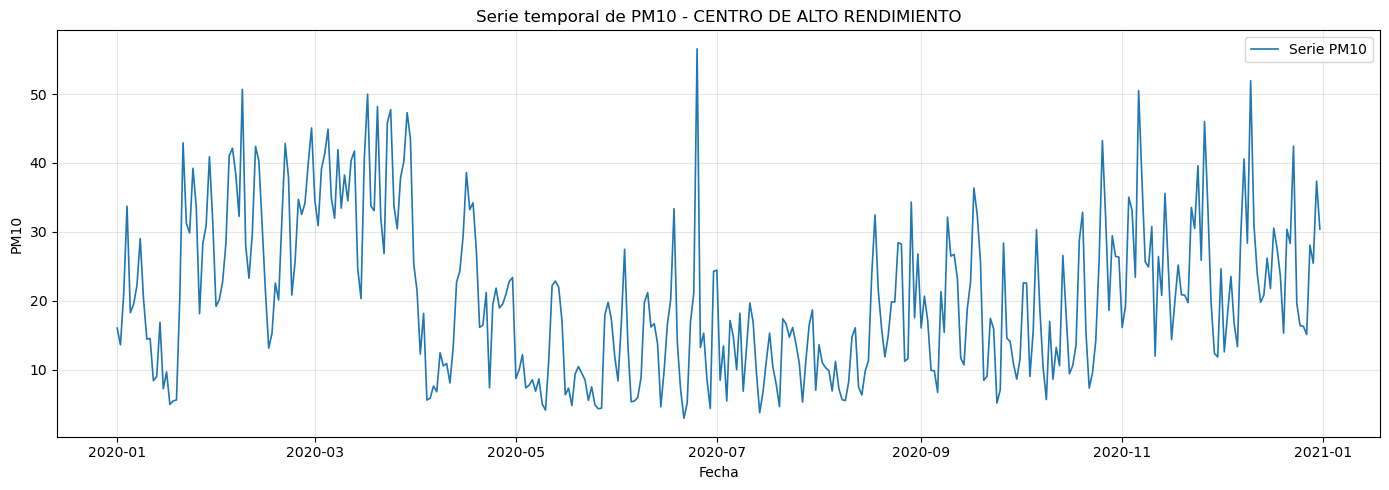

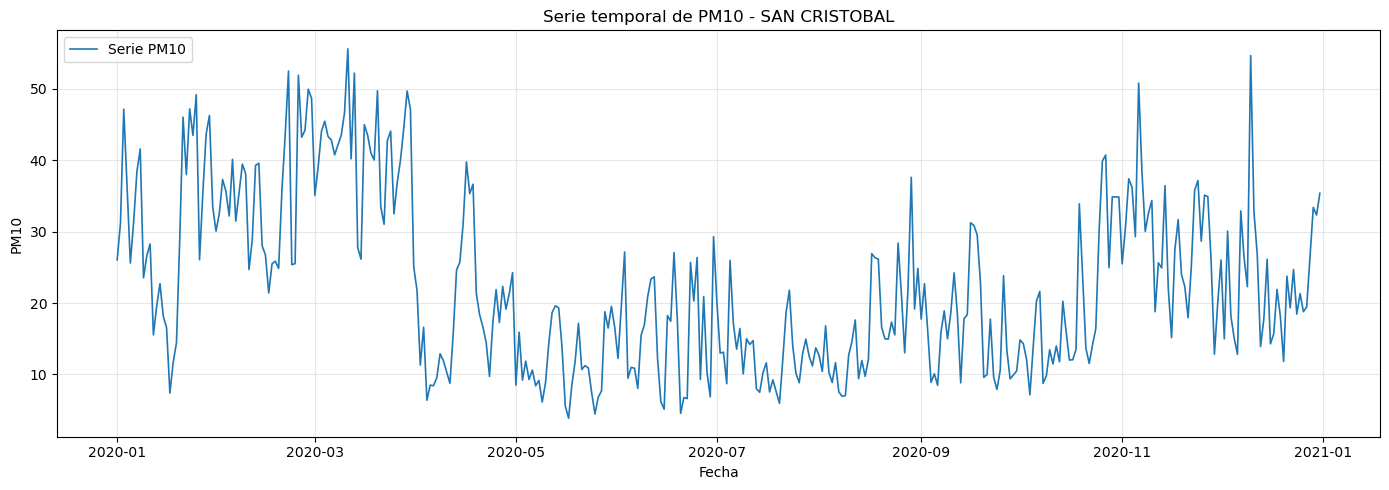

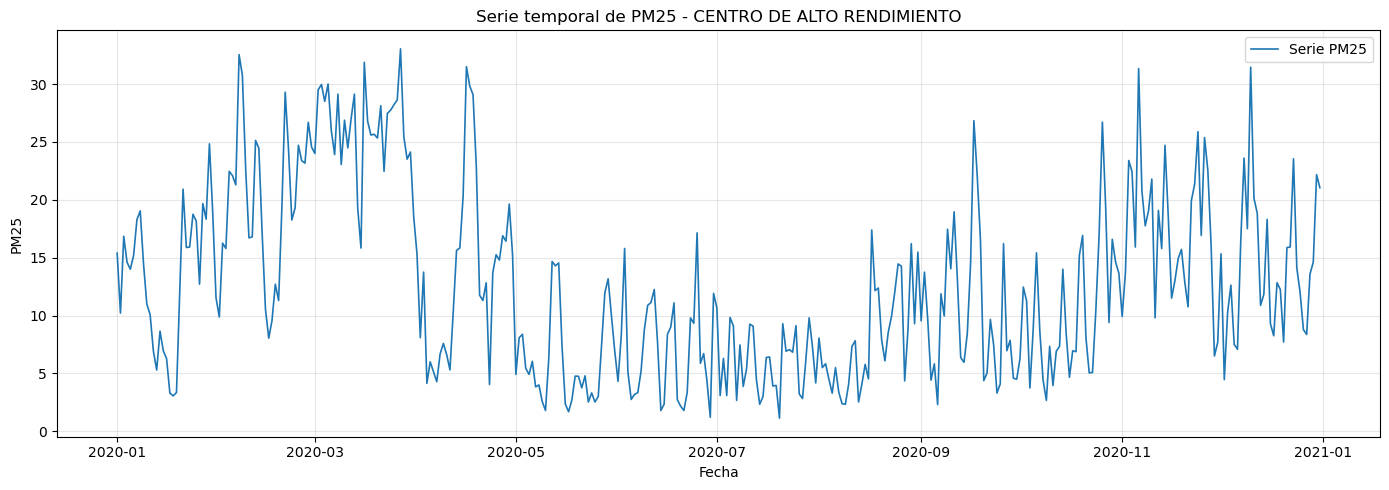

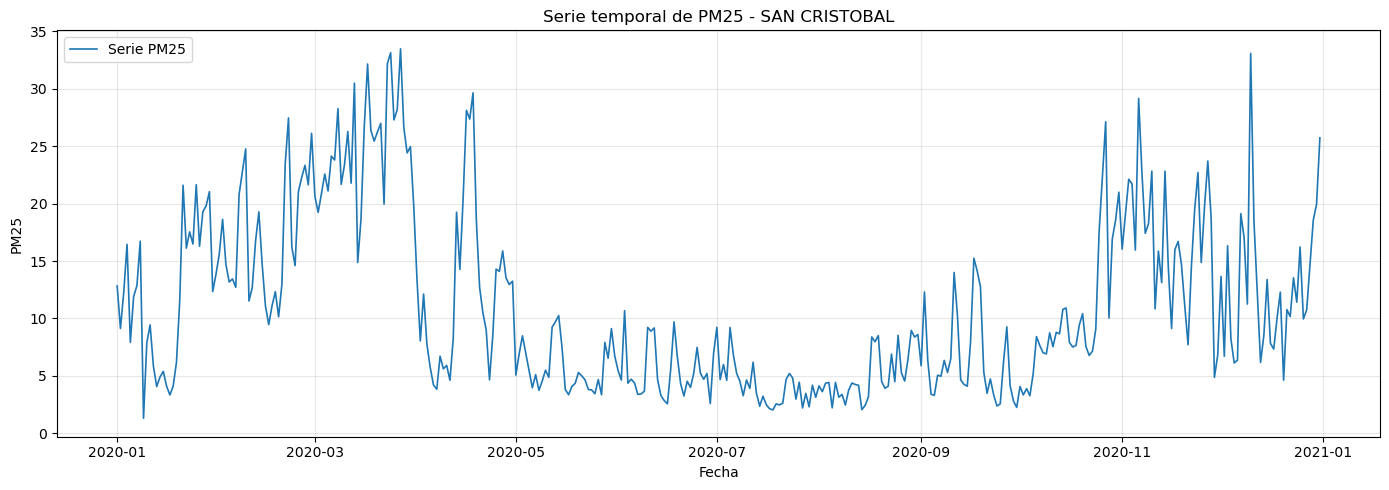

In [9]:
# ============================================================
# GRÁFICAS INICIALES DE SERIES DE TIEMPO
# ============================================================

for target in [t for t in TARGETS_A_EVALUAR if t in df_master.columns]:
    for estacion, sub in df_master.groupby("Estacion"):
        sub = sub.sort_values("Fecha inicial")
        if sub[target].notna().sum() < 30:
            continue

        plt.figure(figsize=(14, 5))
        plt.plot(sub["Fecha inicial"], sub[target], label=f"Serie {target}", linewidth=1.2)
        plt.title(f"Serie temporal de {target} - {estacion}")
        plt.xlabel("Fecha")
        plt.ylabel(target)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        nombre_seguro = re.sub(r"[^A-Za-z0-9_]+", "_", f"serie_original_{target}_{estacion}")
        plt.savefig(GRAFICAS_DIR / f"{nombre_seguro}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()


## Protocolo de evaluación temporal para tesis

Este notebook usa un protocolo homogéneo para comparar los modelos de predicción de PM10 y PM2.5.

### Escenarios evaluados

1. **Sensibilidad a la partición temporal** con predicción a **1 día**:
   - 60 % entrenamiento / 40 % prueba.
   - 70 % entrenamiento / 30 % prueba.
   - 80 % entrenamiento / 20 % prueba.
   - 90 % entrenamiento / 10 % prueba.

2. **Horizontes directos de predicción**:
   - 7 días.
   - 30 días.
   - 90 días.

   Para aislar el efecto del horizonte, estos tres escenarios usan como referencia una partición nominal 80 % / 20 %.

### Controles metodológicos

- Las particiones son **cronológicas**; no se mezclan observaciones futuras con pasadas.
- Para un horizonte \(h\), la variable objetivo es \(y_{t+h}\); por tanto, 7, 30 y 90 días son **horizontes reales de pronóstico**, no solamente tamaños del conjunto de prueba.
- Se aplica una **purga temporal (gap) de \(h\) días** entre entrenamiento y prueba, y también dentro de la validación cruzada temporal.
- No se usa `bfill` ni interpolación bidireccional dentro de la etapa de modelado.
- Se incluye una línea base de **persistencia**: \(\hat{y}_{t+h}=y_t\).
- La selección de hiperparámetros se realiza únicamente con el conjunto de entrenamiento.
- Se registran por escenario los tiempos de validación, entrenamiento final, predicción y tiempo total.
- Se reportan MAE, RMSE, R², MAPE, sMAPE, WAPE, sesgo medio y mejora de RMSE frente a persistencia.

> **Nota:** debido a la purga temporal, el porcentaje efectivo de entrenamiento puede ser ligeramente inferior al porcentaje nominal. Ambos valores se reportan en las tablas finales.


In [10]:

# ============================================================
# 9. CONFIGURACIÓN DEL PROTOCOLO - RED NEURONAL MLP
# ============================================================

import json
import re
import platform
import sklearn
import matplotlib

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE_MLP = 42
N_FOLDS_MLP = 5
TRAIN_FRAC_HORIZONTES = 0.80
MIN_TRAIN_MLP = 120
MIN_TEST_MLP = 20
CLIP_PREDICCIONES_CERO = True

# Control de alineación temporal para evitar modelos visualmente "corridos".
CONTROL_ALINEACION_TEMPORAL = True
# Pesos del score de validación: RMSE 55%, MAE 15%, desfase 20%, R² 10%.
PESOS_SCORE_CV_ALINEADO = {"RMSE": 0.55, "MAE": 0.15, "LAG": 0.20, "R2": 0.10}
CALCULAR_IMPORTANCIA_PERMUTACION_MEJOR = True
N_REPEATS_IMPORTANCIA = 5

ESCENARIOS_MLP = [
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "60_40_H1", "Train_nominal": 0.60, "Horizonte_dias": 1, "Orden": 1},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "70_30_H1", "Train_nominal": 0.70, "Horizonte_dias": 1, "Orden": 2},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "80_20_H1", "Train_nominal": 0.80, "Horizonte_dias": 1, "Orden": 3},
    {"Tipo_evaluacion": "Particion porcentual", "Escenario": "90_10_H1", "Train_nominal": 0.90, "Horizonte_dias": 1, "Orden": 4},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_7_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 7, "Orden": 5},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_30_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 30, "Orden": 6},
    {"Tipo_evaluacion": "Horizonte fijo", "Escenario": "H_90_dias_80_20", "Train_nominal": TRAIN_FRAC_HORIZONTES, "Horizonte_dias": 90, "Orden": 7},
]

# Grilla compacta y defendible para una tesis. El escalamiento se ajusta dentro de cada fold.
PARAM_GRID_MLP = [
    {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.0001,
        "learning_rate_init": 0.001,
        "max_iter": 1000,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 30,
    },
    {
        "hidden_layer_sizes": (128, 64),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "max_iter": 1000,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 30,
    },
    {
        "hidden_layer_sizes": (128, 64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.0005,
        "max_iter": 1200,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 40,
    },
    {
        "hidden_layer_sizes": (128, 64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.01,
        "learning_rate_init": 0.0005,
        "max_iter": 1200,
        "early_stopping": False,
        "shuffle": True,
        "tol": 1e-4,
        "n_iter_no_change": 40,
    },
]

REZAGOS_TARGET_MLP = [1, 2, 3, 7, 14, 21, 30, 45, 60]
VENTANAS_TARGET_MLP = [3, 7, 14, 21, 30, 45, 60]
REZAGOS_COV_MLP = [1, 2, 3, 7, 14, 21, 30]
VENTANAS_COV_MLP = [3, 7, 14]

SALIDAS_MLP = Path("salidas_MLP_TESIS_PROTOCOLO_TEMPORAL_NUEVOS_DATOS")
GRAFICAS_MLP = SALIDAS_MLP / "graficas"
TABLAS_MLP = SALIDAS_MLP / "tablas"
MODELOS_MLP = SALIDAS_MLP / "modelos"
for carpeta in [SALIDAS_MLP, GRAFICAS_MLP, TABLAS_MLP, MODELOS_MLP]:
    carpeta.mkdir(parents=True, exist_ok=True)

versiones_mlp_df = pd.DataFrame([{
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "Semilla": RANDOM_STATE_MLP
}])

escenarios_mlp_df = pd.DataFrame(ESCENARIOS_MLP)
hiperparametros_mlp_df = pd.DataFrame(PARAM_GRID_MLP).reset_index().rename(columns={"index": "id_config"})

display(Markdown("## Escenarios de evaluación"))
display(escenarios_mlp_df)

display(Markdown("## Grilla candidata de hiperparámetros"))
display(hiperparametros_mlp_df)

display(Markdown("## Entorno de ejecución"))
display(versiones_mlp_df)


## Escenarios de evaluación

,Tipo_evaluacion,Escenario,Train_nominal,Horizonte_dias,Orden
0,Particion porcentual,60_40_H1,0.6,1,1
1,Particion porcentual,70_30_H1,0.7,1,2
2,Particion porcentual,80_20_H1,0.8,1,3
3,Particion porcentual,90_10_H1,0.9,1,4
4,Horizonte fijo,H_7_dias_80_20,0.8,7,5
5,Horizonte fijo,H_30_dias_80_20,0.8,30,6
6,Horizonte fijo,H_90_dias_80_20,0.8,90,7


## Grilla candidata de hiperparámetros

,id_config,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,max_iter,early_stopping,shuffle,tol,n_iter_no_change
0,0,"(64, 32)",relu,adam,0.0001,0.0010,1000,False,True,0.0001,30
1,1,"(128, 64)",relu,adam,0.0010,0.0010,1000,False,True,0.0001,30
2,2,"(128, 64, 32)",relu,adam,0.0010,0.0005,1200,False,True,0.0001,40
3,3,"(128, 64, 32)",relu,adam,0.0100,0.0005,1200,False,True,0.0001,40


## Entorno de ejecución

,Python,numpy,pandas,scikit_learn,matplotlib,Semilla
0,3.13.5,2.1.3,2.2.3,1.6.1,3.10.0,42


In [11]:

# ============================================================
# 10. FUNCIONES DE PREPARACIÓN, MÉTRICAS Y VALIDACIÓN TEMPORAL
# ============================================================

def nombre_seguro_mlp(texto):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(texto)).strip("_")


def calcular_metricas_tesis_mlp(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_real) & np.isfinite(y_pred)
    y_real, y_pred = y_real[mask], y_pred[mask]

    if len(y_real) == 0:
        return {k: np.nan for k in ["MAE", "RMSE", "R2", "MAPE_%", "sMAPE_%", "WAPE_%", "Sesgo_ME"]}

    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan

    mask_mape = np.abs(y_real) > 1e-8
    mape = np.mean(np.abs((y_real[mask_mape] - y_pred[mask_mape]) / y_real[mask_mape])) * 100 if mask_mape.any() else np.nan

    denom_smape = np.abs(y_real) + np.abs(y_pred)
    smape = np.mean(np.where(denom_smape > 1e-8, 2 * np.abs(y_pred - y_real) / denom_smape, np.nan)) * 100

    denom_wape = np.sum(np.abs(y_real))
    wape = (np.sum(np.abs(y_real - y_pred)) / denom_wape) * 100 if denom_wape > 1e-8 else np.nan
    sesgo = np.mean(y_pred - y_real)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE_%": mape,
        "sMAPE_%": smape,
        "WAPE_%": wape,
        "Sesgo_ME": sesgo,
    }


def preparar_supervisado_mlp(df_estacion, target, covariables, horizonte):
    df = df_estacion.copy()
    df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
    df = df.dropna(subset=["Fecha inicial"]).sort_values("Fecha inicial")
    df = df.drop_duplicates(subset=["Fecha inicial"], keep="last").set_index("Fecha inicial").asfreq("D")

    columnas_numericas = [c for c in [target] + covariables if c in df.columns]
    df[columnas_numericas] = df[columnas_numericas].apply(pd.to_numeric, errors="coerce")

    df["Fecha_objetivo"] = df.index + pd.to_timedelta(horizonte, unit="D")
    df["y_futuro"] = df[target].shift(-horizonte)
    df[f"{target}_t0"] = df[target]

    for lag in REZAGOS_TARGET_MLP:
        df[f"{target}_lag_{lag}"] = df[target].shift(lag)

    for ventana in VENTANAS_TARGET_MLP:
        r = df[target].rolling(ventana, min_periods=ventana)
        df[f"{target}_media_{ventana}"] = r.mean()
        df[f"{target}_std_{ventana}"] = r.std()
        df[f"{target}_min_{ventana}"] = r.min()
        df[f"{target}_max_{ventana}"] = r.max()

    df[f"{target}_diff_1"] = df[target] - df[target].shift(1)
    df[f"{target}_diff_7"] = df[target] - df[target].shift(7)

    fecha_obj = pd.DatetimeIndex(df["Fecha_objetivo"])
    df["dow_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofweek / 7)
    df["dow_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofweek / 7)
    df["doy_obj_sin"] = np.sin(2 * np.pi * fecha_obj.dayofyear / 365.25)
    df["doy_obj_cos"] = np.cos(2 * np.pi * fecha_obj.dayofyear / 365.25)

    covs_modelo = [c for c in covariables if c in df.columns]

    if "DViento" in covs_modelo:
        df["DViento_sin_t0"] = np.sin(np.deg2rad(df["DViento"]))
        df["DViento_cos_t0"] = np.cos(np.deg2rad(df["DViento"]))

    for cov in covs_modelo:
        df[f"{cov}_t0"] = df[cov]
        for lag in REZAGOS_COV_MLP:
            df[f"{cov}_lag_{lag}"] = df[cov].shift(lag)
        for ventana in VENTANAS_COV_MLP:
            df[f"{cov}_media_{ventana}"] = df[cov].rolling(ventana, min_periods=ventana).mean()

    features = [f"{target}_t0"]
    features += [c for c in df.columns if c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if c.startswith(f"{target}_media_") or c.startswith(f"{target}_std_") or c.startswith(f"{target}_min_") or c.startswith(f"{target}_max_")]
    features += [f"{target}_diff_1", f"{target}_diff_7"]
    features += ["dow_obj_sin", "dow_obj_cos", "doy_obj_sin", "doy_obj_cos"]
    features += [c for c in df.columns if c.endswith("_t0") and c != f"{target}_t0"]
    features += [c for c in df.columns if "_lag_" in c and not c.startswith(f"{target}_lag_")]
    features += [c for c in df.columns if "_media_" in c and not c.startswith(f"{target}_media_")]

    features = list(dict.fromkeys([c for c in features if c in df.columns]))
    data = df[features + ["y_futuro", "Fecha_objetivo"]].replace([np.inf, -np.inf], np.nan).dropna().copy()
    features = [c for c in features if data[c].nunique(dropna=True) > 1]
    data = data[features + ["y_futuro", "Fecha_objetivo"]].copy()

    X = data[features]
    y = data["y_futuro"]
    meta = pd.DataFrame({
        "Fecha_origen": data.index,
        "Fecha_objetivo": pd.to_datetime(data["Fecha_objetivo"].values),
        "Persistencia": data[f"{target}_t0"].values,
    }, index=data.index)

    return X, y, meta, features


def dividir_holdout_purgado_mlp(X, y, meta, train_frac, horizonte):
    n = len(X)
    n_test = max(MIN_TEST_MLP, int(np.ceil(n * (1 - train_frac))))
    test_start = n - n_test
    gap = int(max(1, horizonte))
    train_end = test_start - gap

    min_train_requerido = max(MIN_TRAIN_MLP, int(horizonte) + 80)
    if train_end < min_train_requerido or test_start >= n:
        return None

    return {
        "X_train": X.iloc[:train_end].copy(),
        "y_train": y.iloc[:train_end].copy(),
        "meta_train": meta.iloc[:train_end].copy(),
        "X_test": X.iloc[test_start:].copy(),
        "y_test": y.iloc[test_start:].copy(),
        "meta_test": meta.iloc[test_start:].copy(),
        "N_gap": gap,
        "Train_efectivo_%": train_end / n * 100,
        "Test_efectivo_%": (n - test_start) / n * 100,
    }


def construir_mlp_tesis(params):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            **params,
            random_state=RANDOM_STATE_MLP
        ))
    ])



def crear_tscv_seguro_mlp(n_muestras, horizonte, max_splits=N_FOLDS_MLP, min_train_cv=60, min_val_cv=10):
    gap = int(max(1, horizonte))
    for n_splits in range(min(max_splits, 5), 1, -1):
        max_test_size = (n_muestras - gap - min_train_cv) // n_splits
        if max_test_size >= min_val_cv:
            test_size = int(min(60, max_test_size))
            return TimeSeriesSplit(n_splits=n_splits, gap=gap, test_size=test_size)
    raise ValueError(
        f"No hay suficientes datos para validación temporal con gap={gap}. "
        f"N entrenamiento={n_muestras}."
    )




def max_lag_diagnostico_mlp(horizonte, n=None):
    """Máximo desfase a explorar solo con fines diagnósticos."""
    h = int(max(1, horizonte))
    base_lag = 7 if h <= 7 else (14 if h <= 30 else 30)
    if n is not None:
        base_lag = min(base_lag, max(1, int(n) // 4))
    return int(max(1, base_lag))


def diagnosticar_desfase_temporal_mlp(y_real, y_pred, horizonte=1):
    """
    Evalúa la alineación temporal SIN modificar la predicción original.

    Convención de Lag_optimo_dias:
    - 0: máxima correlación sin desplazar la predicción (deseable).
    - positivo: para maximizar correlación habría que mover la predicción hacia fechas posteriores.
    - negativo: para maximizar correlación habría que mover la predicción hacia fechas anteriores.

    El desplazamiento se reporta únicamente como diagnóstico; nunca se usa para
    recalcular las métricas de prueba ni para presentar una predicción corregida a posteriori.
    """
    real = pd.Series(np.asarray(y_real, dtype=float)).reset_index(drop=True)
    pred = pd.Series(np.asarray(y_pred, dtype=float)).reset_index(drop=True)
    n = min(len(real), len(pred))
    real, pred = real.iloc[:n], pred.iloc[:n]

    if n < 4:
        return {
            "Lag_optimo_dias": np.nan,
            "Lag_abs_dias": np.nan,
            "Correlacion_lag0": np.nan,
            "Correlacion_max_desfase": np.nan,
        }

    max_lag = max_lag_diagnostico_mlp(horizonte, n=n)
    registros = []
    for lag in range(-max_lag, max_lag + 1):
        pred_shift = pred.shift(lag)
        valido = real.notna() & pred_shift.notna()
        if valido.sum() < 4 or real[valido].nunique() < 2 or pred_shift[valido].nunique() < 2:
            corr = np.nan
        else:
            corr = real[valido].corr(pred_shift[valido])
        registros.append((lag, corr))

    corr0 = next((c for l, c in registros if l == 0), np.nan)
    validos = [(l, c) for l, c in registros if np.isfinite(c)]
    if not validos:
        lag_opt, corr_max = np.nan, np.nan
    else:
        # Si hay empate, se prefiere el menor |lag| y finalmente lag=0.
        lag_opt, corr_max = max(validos, key=lambda z: (z[1], -abs(z[0]), z[0] == 0))

    return {
        "Lag_optimo_dias": float(lag_opt) if np.isfinite(lag_opt) else np.nan,
        "Lag_abs_dias": float(abs(lag_opt)) if np.isfinite(lag_opt) else np.nan,
        "Correlacion_lag0": float(corr0) if np.isfinite(corr0) else np.nan,
        "Correlacion_max_desfase": float(corr_max) if np.isfinite(corr_max) else np.nan,
    }


def _minmax_seguro_mlp(serie, menor_es_mejor=True):
    s = pd.to_numeric(pd.Series(serie), errors="coerce")
    if s.notna().sum() == 0:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    minimo, maximo = s.min(), s.max()
    if not np.isfinite(minimo) or not np.isfinite(maximo) or np.isclose(minimo, maximo):
        norm = pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    else:
        norm = (s - minimo) / (maximo - minimo)
    if not menor_es_mejor:
        norm = 1 - norm
    return norm.fillna(1.0)


def agregar_score_alineado_cv_mlp(resumen):
    """
    Score de selección construido EXCLUSIVAMENTE con validación temporal.
    Menor es mejor. Prima el error, pero se penaliza una predicción temporalmente corrida.
    """
    r = resumen.copy()
    r["_rmse_n"] = _minmax_seguro_mlp(r["RMSE_CV"], True)
    r["_mae_n"] = _minmax_seguro_mlp(r["MAE_CV"], True)
    r["_lag_n"] = _minmax_seguro_mlp(r["Lag_abs_CV"], True)
    r["_r2_n"] = _minmax_seguro_mlp(r["R2_CV"], False)
    r["Score_CV_alineado"] = (
        0.55 * r["_rmse_n"] +
        0.15 * r["_mae_n"] +
        0.20 * r["_lag_n"] +
        0.10 * r["_r2_n"]
    )
    return r.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])


def seleccionar_mlp_temporal(X_train, y_train, horizonte):
    cv = crear_tscv_seguro_mlp(len(X_train), horizonte)
    filas = []
    inicio_cv = time.perf_counter()

    for id_config, params in enumerate(PARAM_GRID_MLP):
        for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train), start=1):
            X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
            y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

            modelo = construir_mlp_tesis(params)
            modelo.fit(X_tr, y_tr)
            pred = modelo.predict(X_val)
            if CLIP_PREDICCIONES_CERO:
                pred = np.clip(pred, 0, None)

            met = calcular_metricas_tesis_mlp(y_val, pred)
            diag = diagnosticar_desfase_temporal_mlp(y_val, pred, horizonte)
            filas.append({
                "id_config": id_config,
                "Fold": fold,
                "RMSE": met["RMSE"],
                "MAE": met["MAE"],
                "R2": met["R2"],
                "Iteraciones": getattr(modelo.named_steps["mlp"], "n_iter_", np.nan),
                **diag,
            })

    tiempo_cv = time.perf_counter() - inicio_cv
    cv_folds = pd.DataFrame(filas)

    resumen = (
        cv_folds.groupby("id_config", as_index=False)
        .agg(
            RMSE_CV=("RMSE", "mean"),
            RMSE_CV_std=("RMSE", "std"),
            MAE_CV=("MAE", "mean"),
            R2_CV=("R2", "mean"),
            Iteraciones_promedio=("Iteraciones", "mean"),
            Lag_abs_CV=("Lag_abs_dias", "mean"),
            Lag_optimo_CV_mediana=("Lag_optimo_dias", "median"),
            Correlacion_lag0_CV=("Correlacion_lag0", "mean"),
            Correlacion_max_CV=("Correlacion_max_desfase", "mean"),
            N_folds=("Fold", "nunique"),
        )
        .reset_index(drop=True)
    )
    resumen = agregar_score_alineado_cv_mlp(resumen)
    resumen = resumen.sort_values(
        ["Score_CV_alineado", "RMSE_CV", "Lag_abs_CV", "R2_CV"],
        ascending=[True, True, True, False]
    ).reset_index(drop=True)

    mejor_id = int(resumen.iloc[0]["id_config"])
    return PARAM_GRID_MLP[mejor_id].copy(), resumen, cv_folds, tiempo_cv



In [12]:

# ============================================================
# 11. ENTRENAMIENTO Y EVALUACIÓN DE TODOS LOS ESCENARIOS
# ============================================================

base_mlp = df_master.copy()
base_mlp["Fecha inicial"] = pd.to_datetime(base_mlp["Fecha inicial"], errors="coerce")

targets_mlp = [c for c in ["PM10", "PM25", "PM2.5"] if c in base_mlp.columns]
if "PM25" in targets_mlp and "PM2.5" in targets_mlp:
    targets_mlp.remove("PM2.5")

covariables_mlp = [
    "DViento", "VViento", "HAire2", "HAire10", "TAire2", "TAire10",
    "TMPR_AIR_10CM", "P", "PLiquida", "RGlobal", "RUVb"
]
covariables_mlp = [c for c in covariables_mlp if c in base_mlp.columns]

metricas_mlp = []
predicciones_mlp = []
tiempos_mlp = []
cv_resumen_mlp = []
cv_folds_mlp = []
auditoria_mlp = []
modelos_mlp = {}
objetos_prueba_mlp = {}

for estacion, df_est in base_mlp.groupby("Estacion"):
    for target in targets_mlp:
        for esc in ESCENARIOS_MLP:
            h = int(esc["Horizonte_dias"])
            inicio_total = time.perf_counter()

            X, y, meta, features = preparar_supervisado_mlp(
                df_estacion=df_est,
                target=target,
                covariables=covariables_mlp,
                horizonte=h
            )

            auditoria_mlp.append({
                "Estacion": estacion,
                "Variable": target,
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "N_supervisado": len(X),
                "N_features": len(features),
                "Fecha_origen_min": meta["Fecha_origen"].min() if len(meta) else pd.NaT,
                "Fecha_origen_max": meta["Fecha_origen"].max() if len(meta) else pd.NaT,
                "Fecha_objetivo_min": meta["Fecha_objetivo"].min() if len(meta) else pd.NaT,
                "Fecha_objetivo_max": meta["Fecha_objetivo"].max() if len(meta) else pd.NaT,
            })

            split = dividir_holdout_purgado_mlp(X, y, meta, esc["Train_nominal"], h)
            if split is None:
                print(f"Omitido por datos insuficientes: {estacion} | {target} | {esc['Escenario']}")
                continue

            X_train, y_train = split["X_train"], split["y_train"]
            X_test, y_test = split["X_test"], split["y_test"]
            meta_train, meta_test = split["meta_train"], split["meta_test"]

            mejores_params, resumen_cv, folds_cv, tiempo_cv = seleccionar_mlp_temporal(
                X_train, y_train, h
            )

            inicio_fit = time.perf_counter()
            modelo = construir_mlp_tesis(mejores_params)
            modelo.fit(X_train, y_train)
            tiempo_fit = time.perf_counter() - inicio_fit

            inicio_pred = time.perf_counter()
            pred_train = modelo.predict(X_train)
            pred_test = modelo.predict(X_test)
            if CLIP_PREDICCIONES_CERO:
                pred_train = np.clip(pred_train, 0, None)
                pred_test = np.clip(pred_test, 0, None)
            tiempo_pred = time.perf_counter() - inicio_pred

            met_train = calcular_metricas_tesis_mlp(y_train, pred_train)
            met_test = calcular_metricas_tesis_mlp(y_test, pred_test)
            met_base = calcular_metricas_tesis_mlp(y_test, meta_test["Persistencia"].values)

            # Alineación temporal: diagnóstico sin desplazar la predicción.
            diag_train_mlp = diagnosticar_desfase_temporal_mlp(y_train, pred_train, h)
            diag_test_mlp = diagnosticar_desfase_temporal_mlp(y_test, pred_test, h)

            mejora_rmse = ((met_base["RMSE"] - met_test["RMSE"]) / met_base["RMSE"] * 100
                           if np.isfinite(met_base["RMSE"]) and met_base["RMSE"] > 0 else np.nan)

            mejor_cv = resumen_cv.iloc[0]
            config_json = json.dumps(mejores_params, ensure_ascii=False, sort_keys=True)
            tiempo_total = time.perf_counter() - inicio_total
            n_iter_final = getattr(modelo.named_steps["mlp"], "n_iter_", np.nan)

            base_fila = {
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_features": len(features),
                "Iteraciones_MLP": n_iter_final,
                "Hiperparametros_seleccionados": config_json,
            }

            metricas_mlp.append({
                **base_fila, "Etapa": "Entrenamiento",
                "N_registros": len(y_train),
                "Fecha_inicio": meta_train["Fecha_objetivo"].min(),
                "Fecha_fin": meta_train["Fecha_objetivo"].max(),
                **met_train,
                **diag_train_mlp,
                "RMSE_persistencia": np.nan,
                "Mejora_RMSE_vs_persistencia_%": np.nan,
            })
            metricas_mlp.append({
                **base_fila, "Etapa": "Prueba",
                "N_registros": len(y_test),
                "Fecha_inicio": meta_test["Fecha_objetivo"].min(),
                "Fecha_fin": meta_test["Fecha_objetivo"].max(),
                **met_test,
                **diag_test_mlp,
                "RMSE_persistencia": met_base["RMSE"],
                "Mejora_RMSE_vs_persistencia_%": mejora_rmse,
            })

            predicciones_mlp.append(pd.DataFrame({
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Horizonte_dias": h,
                "Fecha_origen": meta_test["Fecha_origen"].values,
                "Fecha_objetivo": meta_test["Fecha_objetivo"].values,
                "Real": y_test.values,
                "Prediccion": pred_test,
                "Persistencia": meta_test["Persistencia"].values,
                "Error": y_test.values - pred_test,
                "Error_absoluto": np.abs(y_test.values - pred_test),
            }))

            tiempos_mlp.append({
                "Modelo": "Red Neuronal MLP",
                "Estacion": estacion,
                "Variable": target,
                "Tipo_evaluacion": esc["Tipo_evaluacion"],
                "Escenario": esc["Escenario"],
                "Orden_escenario": esc["Orden"],
                "Horizonte_dias": h,
                "Train_nominal_%": esc["Train_nominal"] * 100,
                "Train_efectivo_%": split["Train_efectivo_%"],
                "Test_efectivo_%": split["Test_efectivo_%"],
                "Gap_purga_dias": split["N_gap"],
                "N_train": len(y_train),
                "N_test": len(y_test),
                "N_features": len(features),
                "Iteraciones_MLP": n_iter_final,
                "Hiperparametros_seleccionados": config_json,
                "RMSE_CV_mejor": mejor_cv["RMSE_CV"],
                "R2_CV_mejor": mejor_cv["R2_CV"],
                "Lag_abs_CV_mejor": mejor_cv.get("Lag_abs_CV", np.nan),
                "Lag_optimo_CV_mediana": mejor_cv.get("Lag_optimo_CV_mediana", np.nan),
                "Correlacion_lag0_CV_mejor": mejor_cv.get("Correlacion_lag0_CV", np.nan),
                "Score_CV_alineado": mejor_cv.get("Score_CV_alineado", np.nan),
                "N_folds_CV": int(mejor_cv["N_folds"]),
                "Tiempo_validacion_CV_s": tiempo_cv,
                "Tiempo_entrenamiento_final_s": tiempo_fit,
                "Tiempo_prediccion_s": tiempo_pred,
                "Tiempo_total_escenario_s": tiempo_total,
                "Tiempo_total_escenario_min": tiempo_total / 60,
            })

            cv_resumen_mlp.append(
                resumen_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )
            cv_folds_mlp.append(
                folds_cv.assign(
                    Estacion=estacion, Variable=target, Escenario=esc["Escenario"],
                    Horizonte_dias=h
                )
            )

            clave = (estacion, target, esc["Escenario"])
            modelos_mlp[clave] = modelo
            objetos_prueba_mlp[clave] = (X_test.copy(), y_test.copy())

            print(
                f"OK | {estacion} | {target} | {esc['Escenario']} | H={h} | "
                f"RMSE={met_test['RMSE']:.3f} | R2={met_test['R2']:.3f} | "
                f"Skill={mejora_rmse:.2f}% | {tiempo_total:.2f}s"
            )

metricas_mlp_df = pd.DataFrame(metricas_mlp)
predicciones_mlp_df = pd.concat(predicciones_mlp, ignore_index=True) if predicciones_mlp else pd.DataFrame()
tiempos_mlp_df = pd.DataFrame(tiempos_mlp)
cv_resumen_mlp_df = pd.concat(cv_resumen_mlp, ignore_index=True) if cv_resumen_mlp else pd.DataFrame()
cv_folds_mlp_df = pd.concat(cv_folds_mlp, ignore_index=True) if cv_folds_mlp else pd.DataFrame()
auditoria_mlp_df = pd.DataFrame(auditoria_mlp)


OK | CENTRO DE ALTO RENDIMIENTO | PM10 | 60_40_H1 | H=1 | RMSE=10.928 | R2=-0.234 | Skill=-6.42% | 54.01s
OK | CENTRO DE ALTO RENDIMIENTO | PM10 | 70_30_H1 | H=1 | RMSE=10.790 | R2=-0.209 | Skill=-1.16% | 60.62s
OK | CENTRO DE ALTO RENDIMIENTO | PM10 | 80_20_H1 | H=1 | RMSE=9.880 | R2=-0.139 | Skill=10.98% | 76.95s
OK | CENTRO DE ALTO RENDIMIENTO | PM10 | 90_10_H1 | H=1 | RMSE=12.314 | R2=-0.925 | Skill=-14.70% | 69.70s
OK | CENTRO DE ALTO RENDIMIENTO | PM10 | H_7_dias_80_20 | H=7 | RMSE=15.903 | R2=-1.959 | Skill=-16.28% | 62.06s
OK | CENTRO DE ALTO RENDIMIENTO | PM10 | H_30_dias_80_20 | H=30 | RMSE=12.230 | R2=-0.694 | Skill=18.44% | 43.38s
Omitido por datos insuficientes: CENTRO DE ALTO RENDIMIENTO | PM10 | H_90_dias_80_20
OK | CENTRO DE ALTO RENDIMIENTO | PM25 | 60_40_H1 | H=1 | RMSE=7.015 | R2=-0.152 | Skill=-13.98% | 47.47s
OK | CENTRO DE ALTO RENDIMIENTO | PM25 | 70_30_H1 | H=1 | RMSE=6.395 | R2=0.013 | Skill=-2.84% | 51.89s
OK | CENTRO DE ALTO RENDIMIENTO | PM25 | 80_20_H1 | H=

## Tabla final de métricas — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_registros,MAE,RMSE,R2,sMAPE_%,WAPE_%,Sesgo_ME,Lag_optimo_dias,Lag_abs_dias,Correlacion_lag0,Correlacion_max_desfase,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,59.6721,40.0000,1,122,8.4921,10.9277,-0.2344,41.8952,38.5491,-2.9232,-7.0,7.0,0.2605,0.3528,10.2684,-6.4216
1,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,69.5082,30.1639,1,92,8.3741,10.7901,-0.2095,41.8690,35.6053,-5.1228,-1.0,1.0,0.4107,0.4398,10.6668,-1.1563
2,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,80.0,79.6721,20.0000,1,61,7.5140,9.8798,-0.1393,30.4852,29.0147,-2.7888,-1.0,1.0,0.2517,0.3625,11.0985,10.9806
3,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,90_10_H1,1,90.0,89.5082,10.1639,1,31,9.4639,12.3144,-0.9254,41.9914,37.1516,-6.8067,-5.0,5.0,0.0625,0.3013,10.7363,-14.6995
4,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5920,20.0669,7,60,12.6801,15.9034,-1.9586,58.5637,48.6570,-3.8402,7.0,7.0,-0.0298,0.1782,13.6773,-16.2757
5,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_30_dias_80_20,30,80.0,68.8406,20.2899,30,56,9.4105,12.2299,-0.6943,38.5856,36.2719,-5.6548,-1.0,1.0,0.0334,0.2509,14.9954,18.4419
6,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,59.6721,40.0000,1,122,11.5927,16.5090,-1.9320,43.5550,52.7375,4.3366,-6.0,6.0,0.2395,0.3784,8.5249,-93.6562
7,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,69.5082,30.1639,1,92,9.3019,12.5694,-0.6879,35.4113,38.9947,2.6755,-2.0,2.0,0.2773,0.3662,9.0506,-38.8794
8,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,80_20_H1,1,80.0,79.6721,20.0000,1,61,9.1330,11.8333,-0.7995,34.2630,34.9591,0.4857,7.0,7.0,0.0992,0.2479,9.7741,-21.0683
9,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,90_10_H1,1,90.0,89.5082,10.1639,1,31,7.8186,11.2470,-0.6619,34.0961,33.3733,-3.0056,7.0,7.0,-0.0548,0.3334,10.4837,-7.2810


## Tabla final de tiempos, configuración e hiperparámetros — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Train_efectivo_%,Test_efectivo_%,Gap_purga_dias,N_train,N_test,N_features,Iteraciones_MLP,Hiperparametros_seleccionados,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Lag_optimo_CV_mediana,Correlacion_lag0_CV_mejor,Score_CV_alineado,N_folds_CV,Tiempo_validacion_CV_s,Tiempo_entrenamiento_final_s,Tiempo_prediccion_s,Tiempo_total_escenario_s,Tiempo_total_escenario_min
0,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,59.6721,40.0000,1,182,122,112,656,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",13.9906,-6.3864,3.6,-1.0,0.0149,0.0571,5,50.9307,2.7663,0.0101,54.0058,0.9001
1,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,69.5082,30.1639,1,212,92,112,708,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",14.2368,-6.4460,4.0,-1.0,-0.0544,0.2000,5,55.8345,4.4834,0.0118,60.6208,1.0103
2,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,80.0,79.6721,20.0000,1,243,61,112,533,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",14.0169,-5.0235,4.4,-5.0,0.0556,0.2000,5,72.6021,4.0183,0.0103,76.9456,1.2824
3,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,90_10_H1,1,90.0,89.5082,10.1639,1,273,31,112,508,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",14.7228,-5.3971,5.4,3.0,0.0863,0.2000,5,65.5994,3.8657,0.0101,69.6972,1.1616
4,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_7_dias_80_20,7,80.0,77.5920,20.0669,7,232,60,112,574,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",15.7531,-6.9242,5.0,-3.0,0.0362,0.0000,5,57.5611,4.2216,0.0104,62.0580,1.0343
5,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_30_dias_80_20,30,80.0,68.8406,20.2899,30,190,56,112,588,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",18.5952,-13.3499,3.4,3.0,0.0439,0.0000,5,40.6030,2.4172,0.0100,43.3814,0.7230
6,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,59.6721,40.0000,1,182,122,112,721,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",9.8073,-4.4823,4.0,-1.0,0.1192,0.1000,5,59.1329,3.0007,0.0104,62.4098,1.0402
7,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,69.5082,30.1639,1,212,92,112,770,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",9.7518,-2.4582,3.6,3.0,0.0425,0.0000,5,62.4444,4.7090,0.0105,67.4342,1.1239
8,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,80_20_H1,1,80.0,79.6721,20.0000,1,243,61,112,595,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",11.0608,-3.2430,5.4,-7.0,0.1751,0.0000,5,80.9750,4.2517,0.0103,85.4973,1.4250
9,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,90_10_H1,1,90.0,89.5082,10.1639,1,273,31,112,569,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",11.9257,-3.1133,5.0,6.0,0.1162,0.0800,5,73.2756,4.2672,0.0270,77.9254,1.2988


## Mejor resultado observado por contaminante, estación y horizonte

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,RMSE,MAE,R2,Lag_optimo_dias,Correlacion_lag0,Score_diagnostico_prueba,RMSE_persistencia,Mejora_RMSE_vs_persistencia_%
0,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,9.8798,7.5140,-0.1393,-1.0,0.2517,0.0000,11.0985,10.9806
1,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_7_dias_80_20,7,15.9034,12.6801,-1.9586,7.0,-0.0298,0.1000,13.6773,-16.2757
2,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_30_dias_80_20,30,12.2299,9.4105,-0.6943,-1.0,0.0334,0.1000,14.9954,18.4419
3,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,12.5694,9.3019,-0.6879,-2.0,0.2773,0.1867,9.0506,-38.8794
4,PM10,SAN CRISTOBAL,Horizonte fijo,H_7_dias_80_20,7,16.7909,12.2046,-2.5641,-1.0,0.2125,0.1000,11.8996,-41.1051
5,PM10,SAN CRISTOBAL,Horizonte fijo,H_30_dias_80_20,30,18.1394,13.6791,-3.1199,14.0,-0.0616,0.1000,14.2506,-27.2886
6,PM25,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,6.3952,5.0156,0.0127,-1.0,0.5512,0.0096,6.2184,-2.8421
7,PM25,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_7_dias_80_20,7,8.4617,6.9067,-0.9582,-2.0,0.1351,0.1000,9.2667,8.6864
8,PM25,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_30_dias_80_20,30,8.7206,7.1531,-1.0364,14.0,0.0644,0.1000,9.9722,12.5507
9,PM25,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,7.7845,5.7373,-0.4861,-1.0,0.3798,0.0000,5.9452,-30.9366


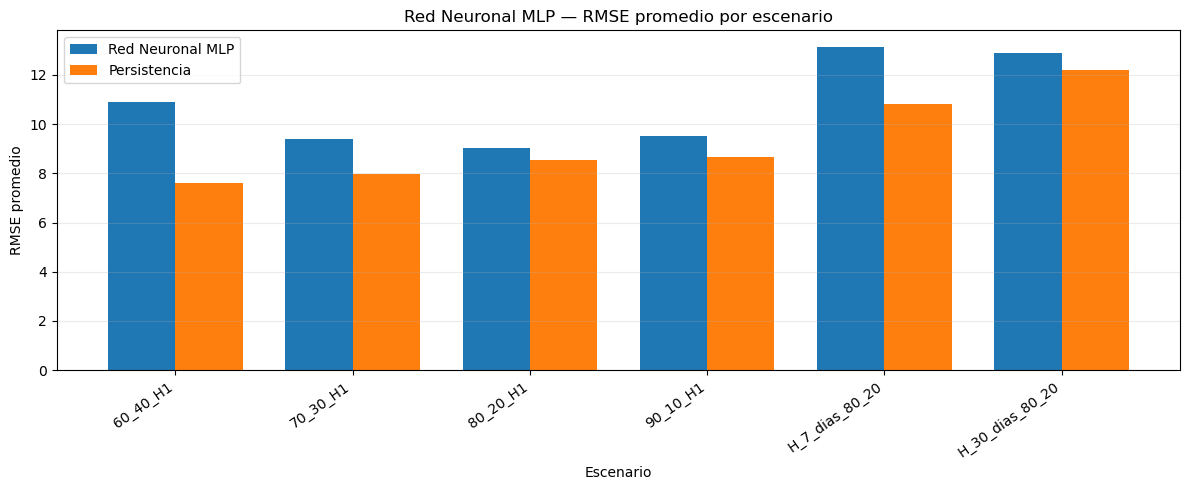

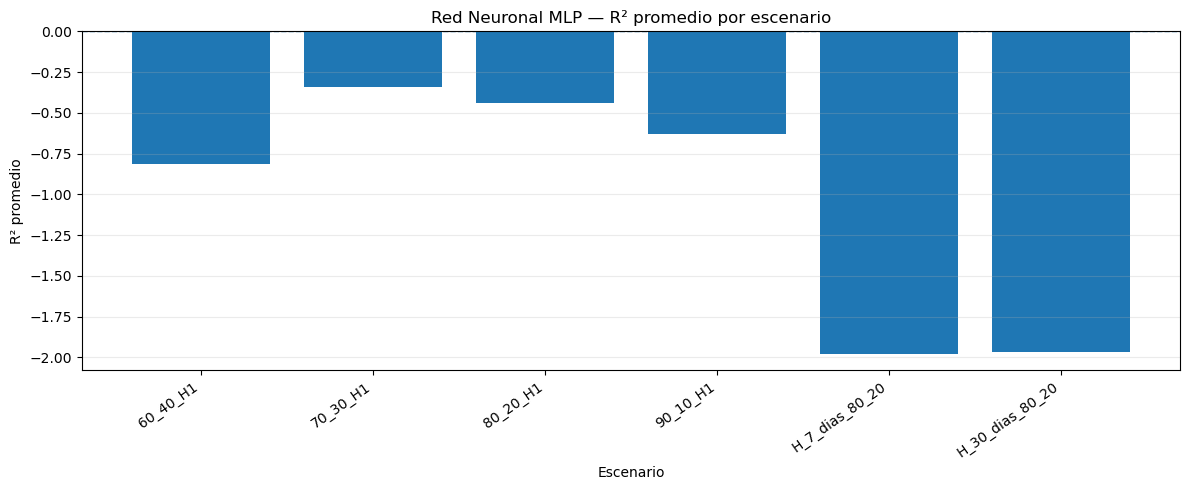

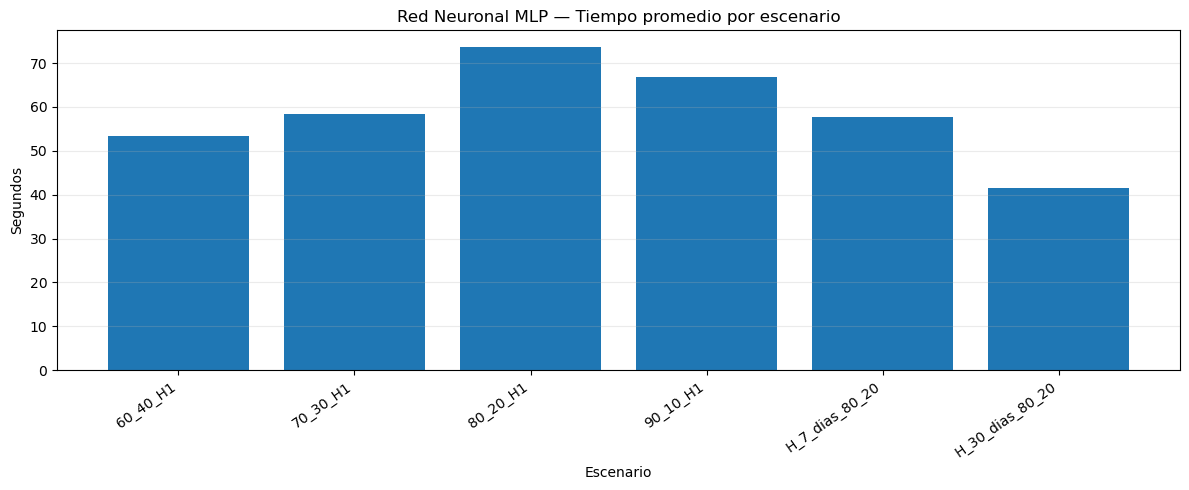

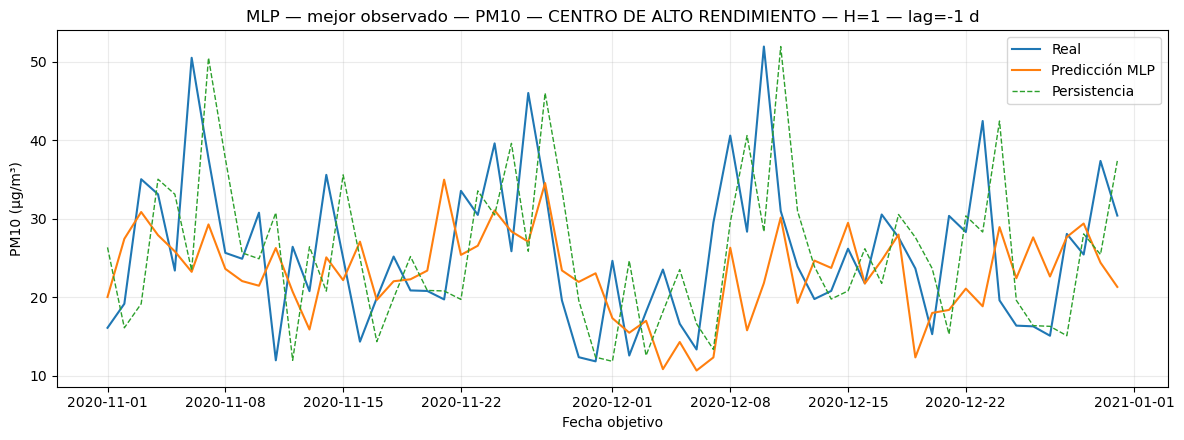

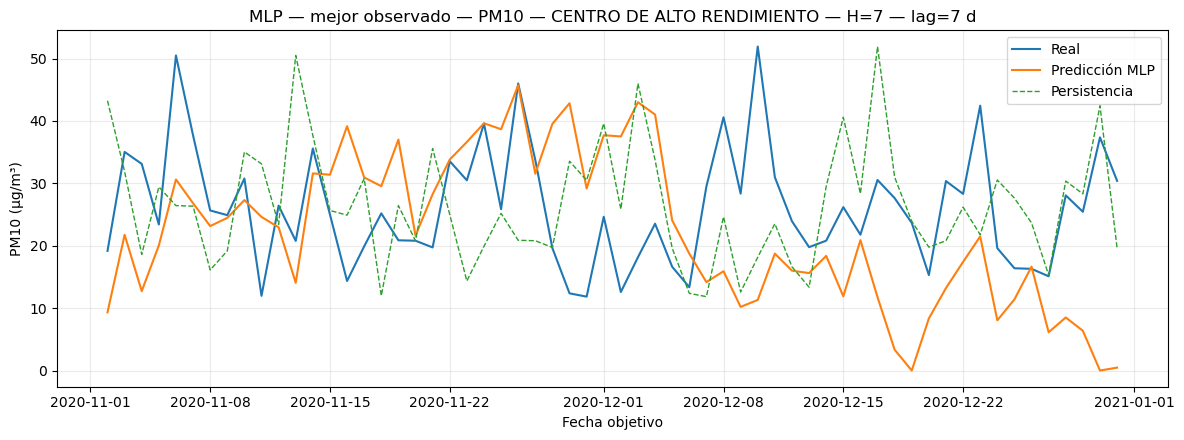

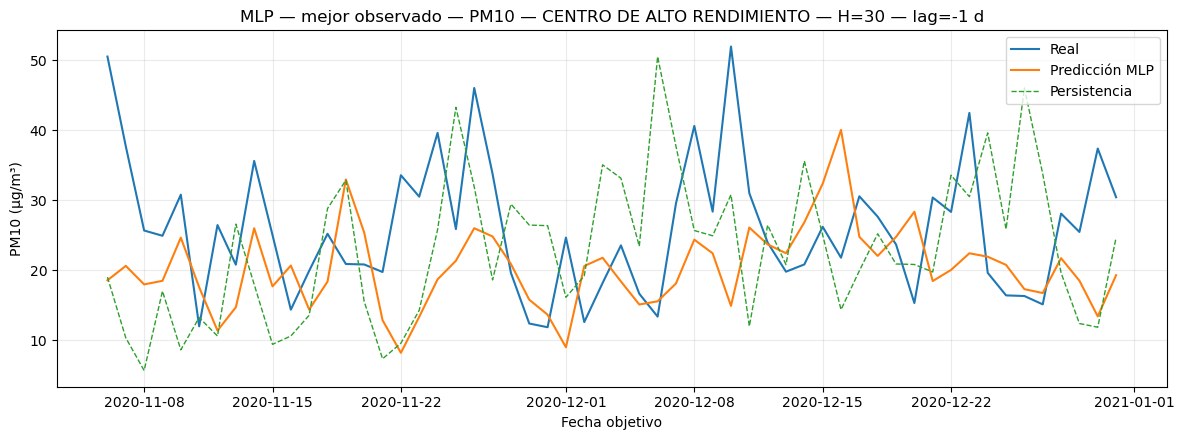

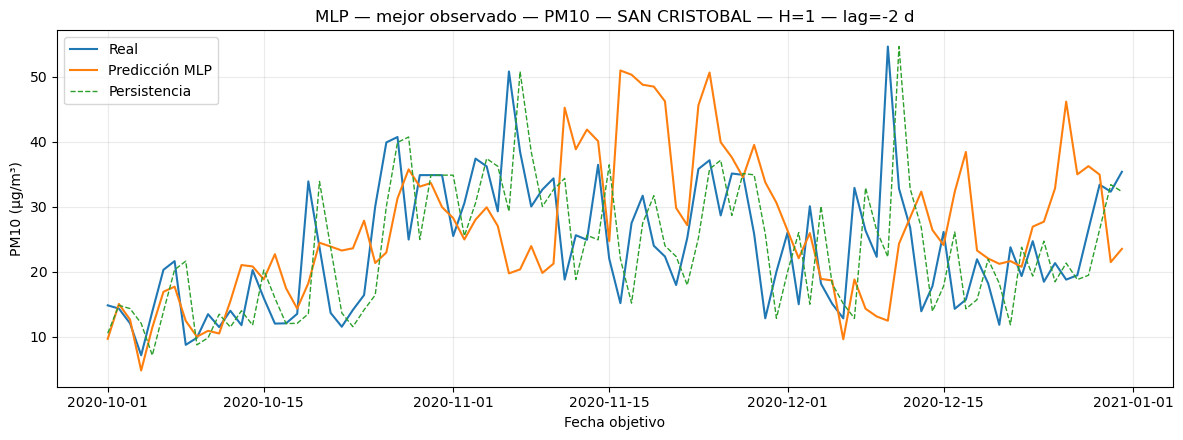

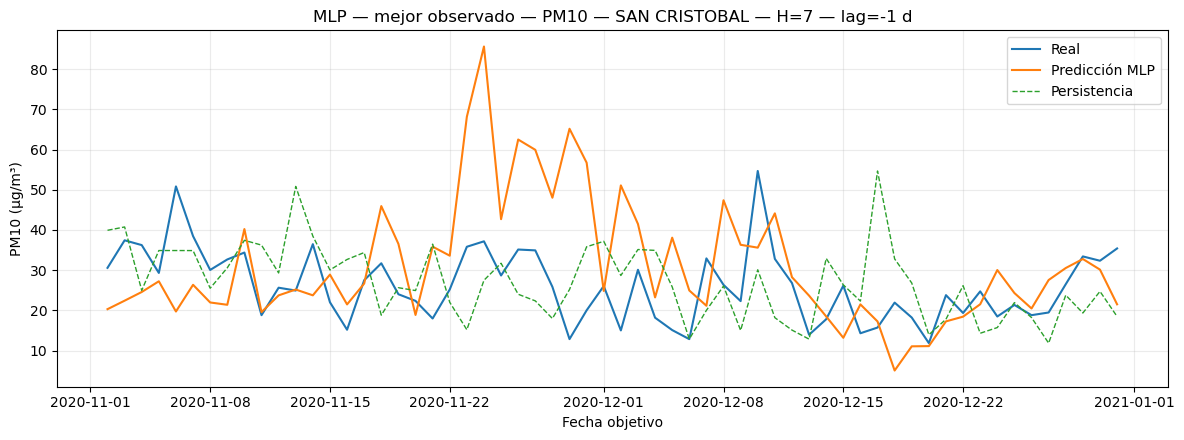

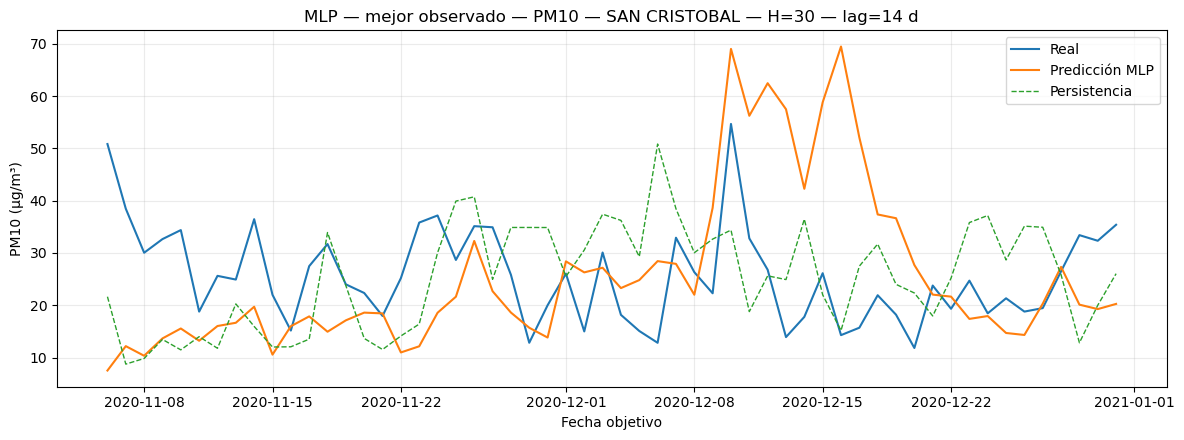

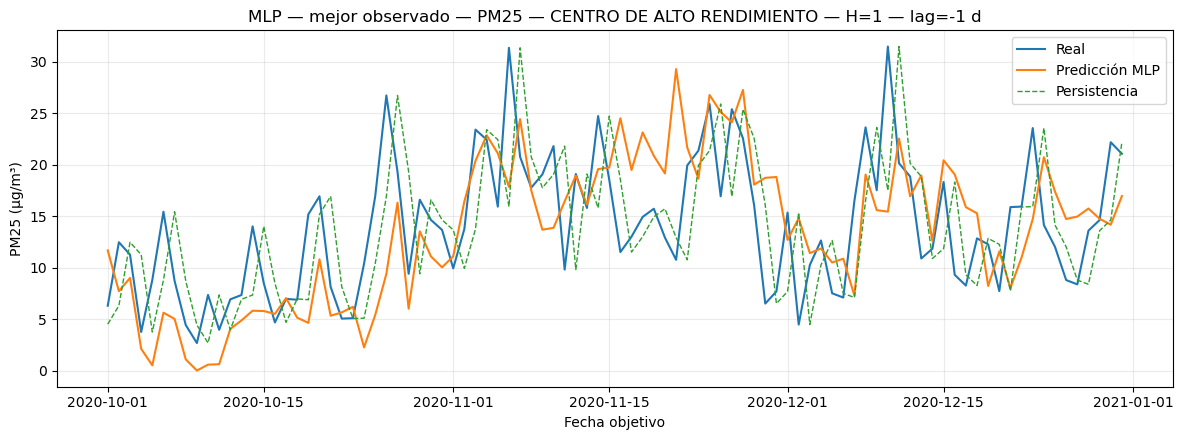

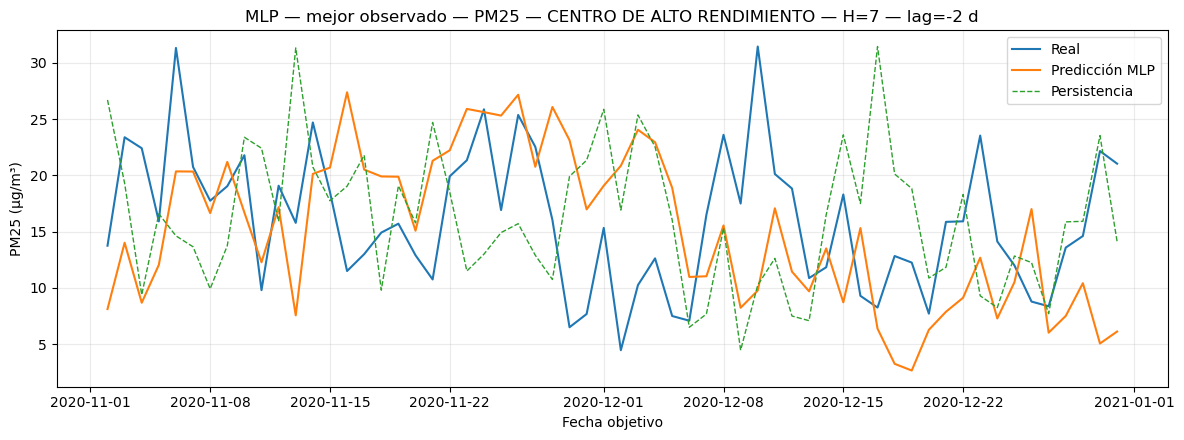

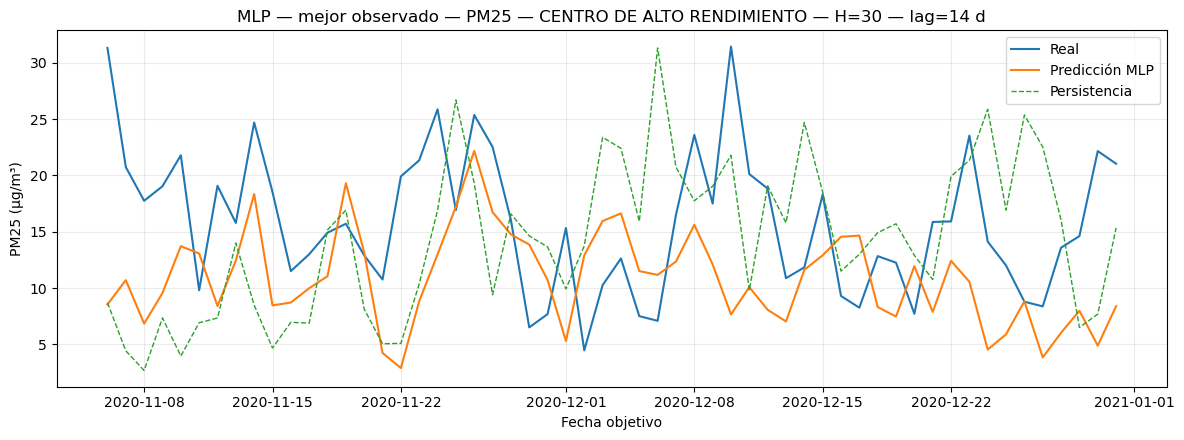

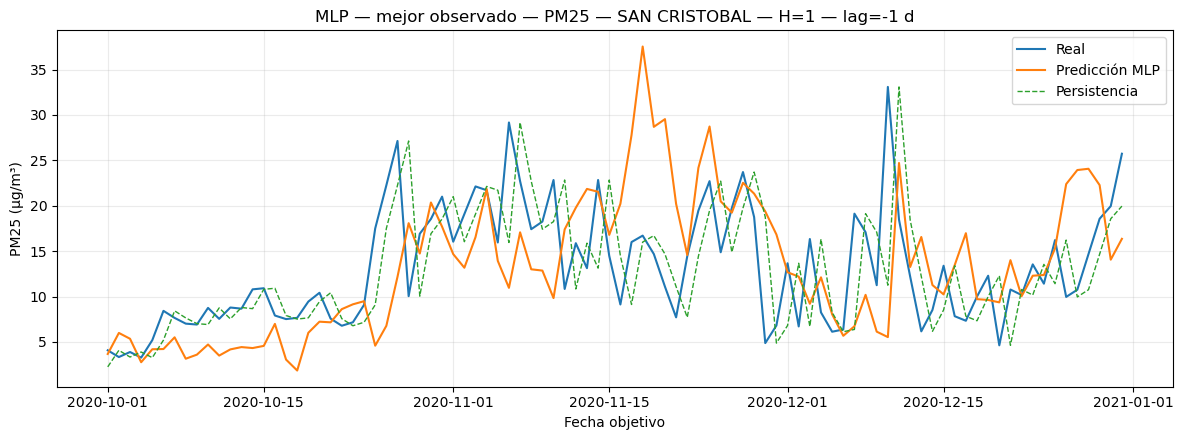

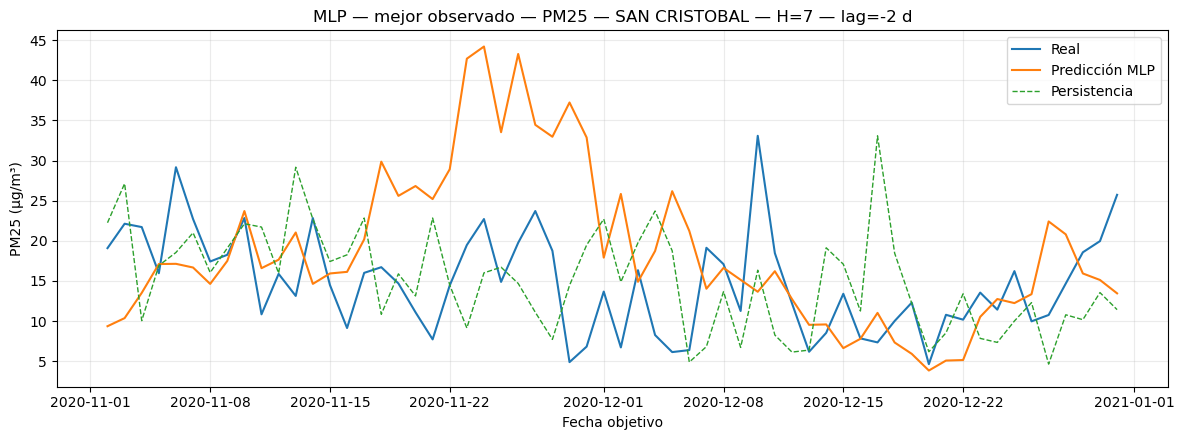

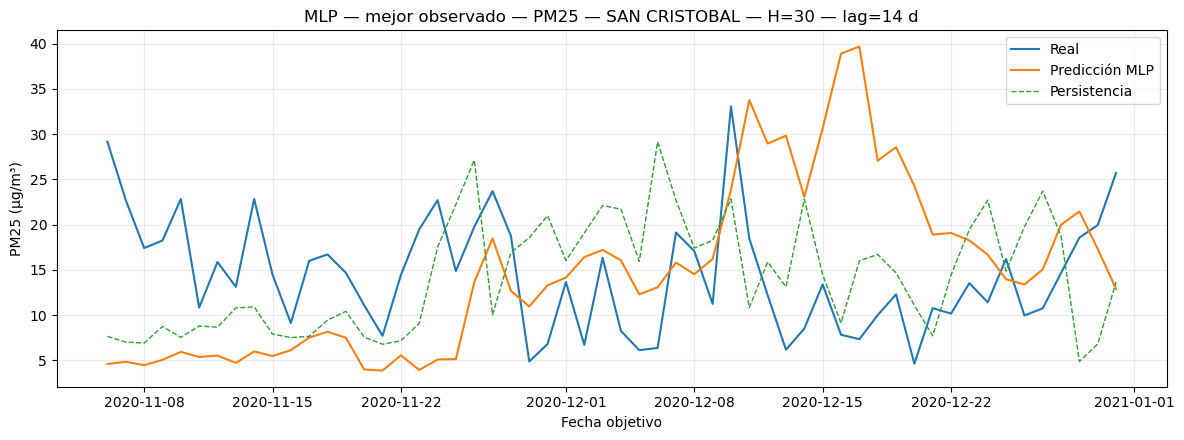

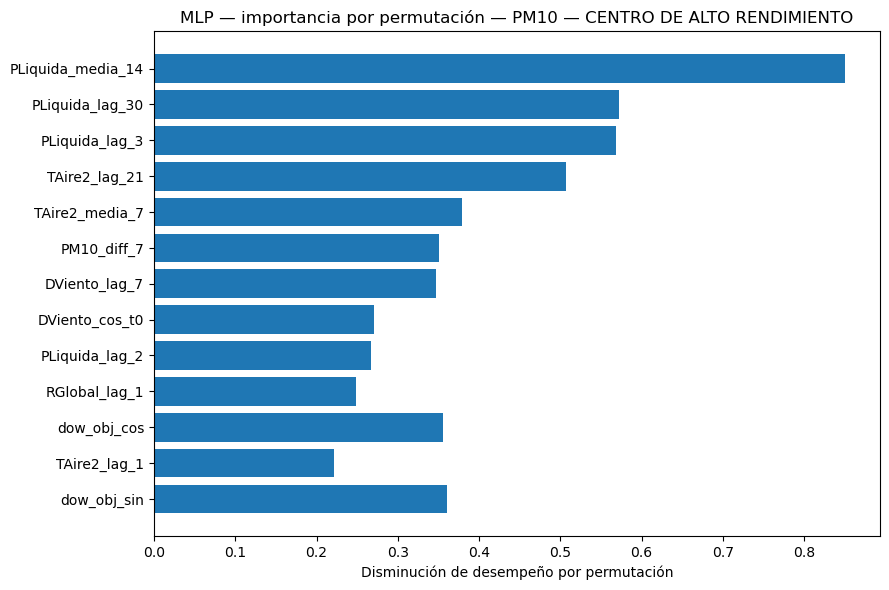

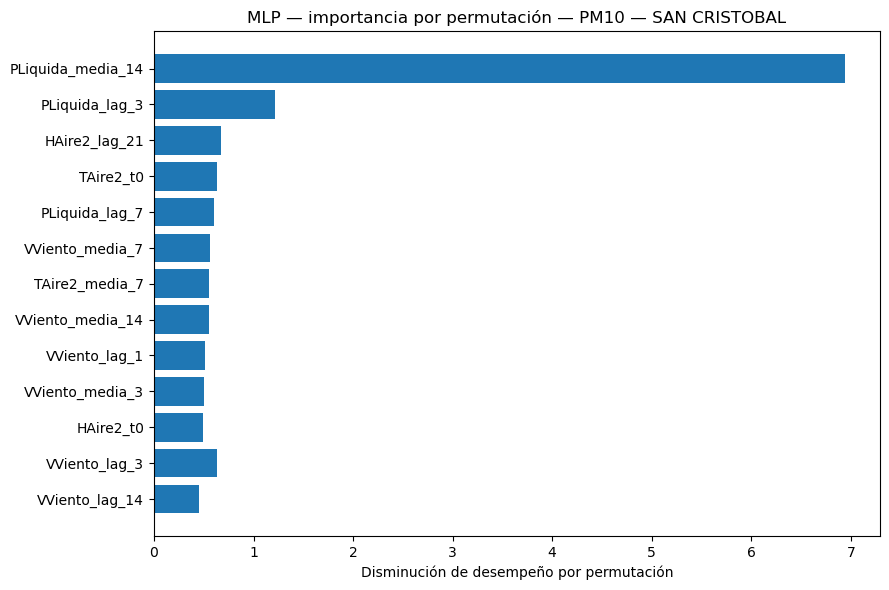

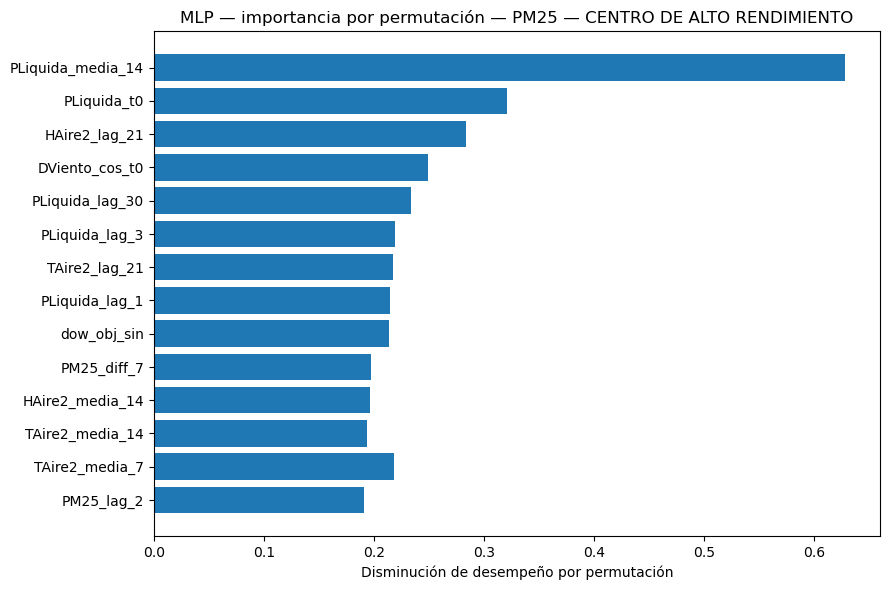

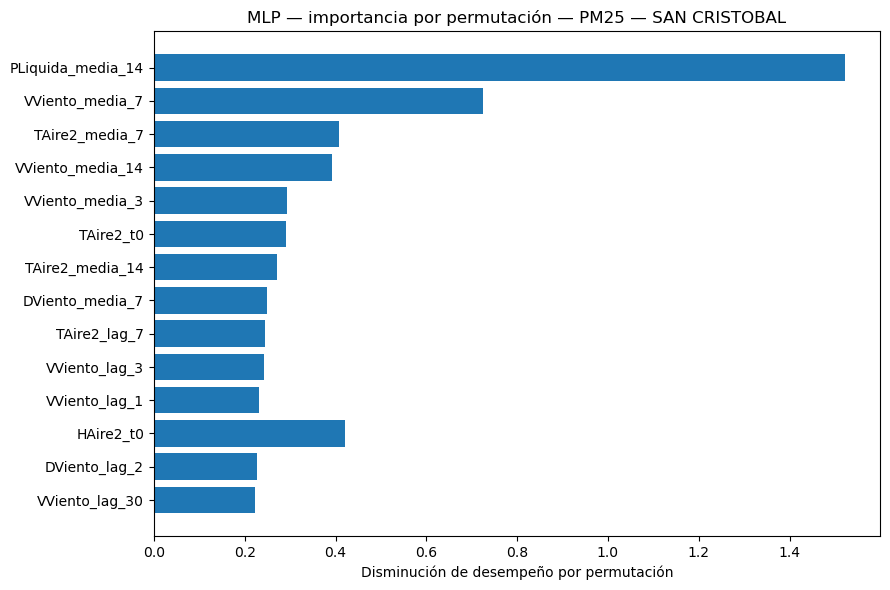

In [13]:

# ============================================================
# 12. TABLAS FINALES ORDENADAS, INTERPRETABILIDAD Y GRÁFICAS
# ============================================================

if metricas_mlp_df.empty:
    raise ValueError("No se generaron resultados de la Red Neuronal MLP. Revisa la disponibilidad de datos.")

metricas_prueba_mlp_df = (
    metricas_mlp_df[metricas_mlp_df["Etapa"] == "Prueba"]
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

tiempos_mlp_df = (
    tiempos_mlp_df
    .sort_values(["Variable", "Estacion", "Orden_escenario"])
    .reset_index(drop=True)
)

columnas_tabla_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_registros",
    "MAE", "RMSE", "R2", "sMAPE_%", "WAPE_%", "Sesgo_ME",
    "Lag_optimo_dias", "Lag_abs_dias", "Correlacion_lag0", "Correlacion_max_desfase",
    "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]
tabla_metricas_tesis_mlp = metricas_prueba_mlp_df[
    [c for c in columnas_tabla_tesis if c in metricas_prueba_mlp_df.columns]
].copy()

columnas_tiempo_tesis = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario",
    "Horizonte_dias", "Train_nominal_%", "Train_efectivo_%",
    "Test_efectivo_%", "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Iteraciones_MLP", "Hiperparametros_seleccionados", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Lag_optimo_CV_mediana",
    "Correlacion_lag0_CV_mejor", "Score_CV_alineado", "N_folds_CV",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s",
    "Tiempo_prediccion_s", "Tiempo_total_escenario_s",
    "Tiempo_total_escenario_min"
]
tabla_tiempos_tesis_mlp = tiempos_mlp_df[
    [c for c in columnas_tiempo_tesis if c in tiempos_mlp_df.columns]
].copy()

display(Markdown("## Tabla final de métricas — Red Neuronal MLP"))
display(tabla_metricas_tesis_mlp.round(4))

display(Markdown("## Tabla final de tiempos, configuración e hiperparámetros — Red Neuronal MLP"))
display(tabla_tiempos_tesis_mlp.round(4))

# ------------------------------------------------------------
# Selección automática para visualización, separada por horizonte
# ------------------------------------------------------------
# IMPORTANTE: los hiperparámetros ya fueron elegidos únicamente mediante CV temporal.
# Este score usa la prueba SOLO para resumir cuál resultado observado se visualiza mejor;
# no reentrena ni altera la predicción.

def _score_diagnostico_prueba_mlp(grupo):
    g = grupo.copy()
    g["_rmse_n"] = _minmax_seguro_mlp(g["RMSE"], True)
    g["_mae_n"] = _minmax_seguro_mlp(g["MAE"], True)
    g["_lag_n"] = _minmax_seguro_mlp(g["Lag_abs_dias"], True)
    g["_r2_n"] = _minmax_seguro_mlp(g["R2"], False)
    g["Score_diagnostico_prueba"] = (
        0.50 * g["_rmse_n"] +
        0.15 * g["_mae_n"] +
        0.25 * g["_lag_n"] +
        0.10 * g["_r2_n"]
    )
    return g.drop(columns=["_rmse_n", "_mae_n", "_lag_n", "_r2_n"])

metricas_prueba_mlp_df = (
    metricas_prueba_mlp_df
    .groupby(["Variable", "Estacion", "Horizonte_dias"], group_keys=False)
    .apply(_score_diagnostico_prueba_mlp)
    .reset_index(drop=True)
)

mejor_mlp = (
    metricas_prueba_mlp_df
    .sort_values(
        ["Variable", "Estacion", "Horizonte_dias", "Score_diagnostico_prueba", "RMSE", "Lag_abs_dias", "R2"],
        ascending=[True, True, True, True, True, True, False]
    )
    .groupby(["Variable", "Estacion", "Horizonte_dias"], as_index=False)
    .first()
)

display(Markdown("## Mejor resultado observado por contaminante, estación y horizonte"))
display(mejor_mlp[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "RMSE", "MAE", "R2", "Lag_optimo_dias", "Correlacion_lag0",
    "Score_diagnostico_prueba", "RMSE_persistencia", "Mejora_RMSE_vs_persistencia_%"
]].round(4))

resumen_escenarios_mlp = (
    metricas_prueba_mlp_df
    .groupby(["Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        RMSE_promedio=("RMSE", "mean"),
        RMSE_persistencia_promedio=("RMSE_persistencia", "mean"),
        R2_promedio=("R2", "mean"),
        Skill_RMSE_promedio=("Mejora_RMSE_vs_persistencia_%", "mean"),
        N_resultados=("RMSE", "count"),
    )
    .sort_values("Orden_escenario")
)

tiempo_escenarios_mlp = (
    tiempos_mlp_df
    .groupby(["Orden_escenario", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        Tiempo_total_promedio_s=("Tiempo_total_escenario_s", "mean"),
        Tiempo_total_acumulado_s=("Tiempo_total_escenario_s", "sum"),
    )
    .sort_values("Orden_escenario")
)

# Importancia por permutación solo en el mejor escenario de cada estación/contaminante.
importancias_mlp = []
if CALCULAR_IMPORTANCIA_PERMUTACION_MEJOR:
    for _, fila in mejor_mlp.iterrows():
        clave = (fila["Estacion"], fila["Variable"], fila["Escenario"])
        if clave not in modelos_mlp or clave not in objetos_prueba_mlp:
            continue

        modelo = modelos_mlp[clave]
        X_test, y_test = objetos_prueba_mlp[clave]

        inicio_imp = time.perf_counter()
        imp = permutation_importance(
            modelo,
            X_test,
            y_test,
            scoring="neg_root_mean_squared_error",
            n_repeats=N_REPEATS_IMPORTANCIA,
            random_state=RANDOM_STATE_MLP,
            n_jobs=-1
        )
        tiempo_imp = time.perf_counter() - inicio_imp

        imp_df = pd.DataFrame({
            "Modelo": "Red Neuronal MLP",
            "Estacion": fila["Estacion"],
            "Variable": fila["Variable"],
            "Escenario": fila["Escenario"],
            "Horizonte_dias": fila["Horizonte_dias"],
            "Feature": X_test.columns,
            "Importancia_permutacion_media": imp.importances_mean,
            "Importancia_permutacion_std": imp.importances_std,
            "Tiempo_importancia_s": tiempo_imp,
        }).sort_values("Importancia_permutacion_media", ascending=False)

        importancias_mlp.append(imp_df)

importancias_mlp_df = pd.concat(importancias_mlp, ignore_index=True) if importancias_mlp else pd.DataFrame()

# Figura 1: RMSE modelo vs persistencia.
x = np.arange(len(resumen_escenarios_mlp))
w = 0.38
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, resumen_escenarios_mlp["RMSE_promedio"], width=w, label="Red Neuronal MLP")
plt.bar(x + w/2, resumen_escenarios_mlp["RMSE_persistencia_promedio"], width=w, label="Persistencia")
plt.xticks(x, resumen_escenarios_mlp["Escenario"], rotation=35, ha="right")
plt.ylabel("RMSE promedio")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — RMSE promedio por escenario")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_RMSE_vs_persistencia.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 2: R² promedio.
plt.figure(figsize=(12, 5))
plt.bar(resumen_escenarios_mlp["Escenario"], resumen_escenarios_mlp["R2_promedio"])
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(rotation=35, ha="right")
plt.ylabel("R² promedio")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — R² promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_R2.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Figura 3: tiempo promedio.
plt.figure(figsize=(12, 5))
plt.bar(tiempo_escenarios_mlp["Escenario"], tiempo_escenarios_mlp["Tiempo_total_promedio_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Segundos")
plt.xlabel("Escenario")
plt.title("Red Neuronal MLP — Tiempo promedio por escenario")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_resumen_tiempos.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close()

# Detalle real vs predicción para el mejor escenario.
for _, fila in mejor_mlp.iterrows():
    sub = predicciones_mlp_df[
        (predicciones_mlp_df["Variable"] == fila["Variable"]) &
        (predicciones_mlp_df["Estacion"] == fila["Estacion"]) &
        (predicciones_mlp_df["Escenario"] == fila["Escenario"])
    ].sort_values("Fecha_objetivo")

    if sub.empty:
        continue

    plt.figure(figsize=(12, 4.5))
    plt.plot(sub["Fecha_objetivo"], sub["Real"], label="Real", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Prediccion"], label="Predicción MLP", linewidth=1.5)
    plt.plot(sub["Fecha_objetivo"], sub["Persistencia"], linestyle="--", label="Persistencia", linewidth=1.0)
    plt.ylabel(f"{fila['Variable']} (µg/m³)")
    plt.xlabel("Fecha objetivo")
    plt.title(f"MLP — mejor observado — {fila['Variable']} — {fila['Estacion']} — H={int(fila['Horizonte_dias'])} — lag={fila['Lag_optimo_dias']:.0f} d")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    nombre = nombre_seguro_mlp(f"{fila['Variable']}_{fila['Estacion']}_{fila['Escenario']}")
    plt.savefig(GRAFICAS_MLP / f"MLP_mejor_{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

# Top 15 de importancia por permutación del mejor escenario.
if not importancias_mlp_df.empty:
    for (variable, estacion), sub in importancias_mlp_df.groupby(["Variable", "Estacion"]):
        top = sub.nlargest(15, "Importancia_permutacion_media").sort_values("Importancia_permutacion_media")
        plt.figure(figsize=(9, 6))
        plt.barh(top["Feature"], top["Importancia_permutacion_media"])
        plt.xlabel("Disminución de desempeño por permutación")
        plt.title(f"MLP — importancia por permutación — {variable} — {estacion}")
        plt.tight_layout()
        nombre = nombre_seguro_mlp(f"{variable}_{estacion}")
        plt.savefig(GRAFICAS_MLP / f"MLP_importancia_permutacion_{nombre}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close()


## Diagnóstico temporal de residuales

Para complementar las métricas agregadas se analiza, fecha a fecha, el **residual de predicción**:

\[
e_t = y_t - \hat{y}_t
\]

- **Residual positivo**: el modelo **subestima** la concentración observada.
- **Residual negativo**: el modelo **sobreestima** la concentración observada.
- **Residual cercano a cero**: la predicción se aproxima al valor observado.

Se guarda la serie residual de **todos los escenarios** y, para mantener el notebook claro y conciso, se muestran en pantalla los residuales correspondientes al **mejor escenario** de cada estación y contaminante. También se calcula una tabla de diagnóstico con media, mediana, desviación estándar, percentil 95 del error absoluto y autocorrelación de rezago 1. Un buen modelo debería presentar residuales centrados alrededor de cero y sin una estructura temporal sistemática evidente.


## Diagnóstico de residuales — Red Neuronal MLP

,Modelo,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,N_residuales,Residual_medio,Residual_mediana,Residual_desv_std,MAE_desde_residual,P95_error_absoluto,Max_error_absoluto,Autocorr_residual_lag1
0,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,122,2.9232,2.9977,10.5729,8.4921,21.0057,35.4462,0.3336
1,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,92,5.1228,4.2711,9.5485,8.3741,18.9032,35.2944,0.2860
2,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,61,2.7888,2.3207,9.5567,7.5140,18.9386,30.1235,0.1310
3,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,90_10_H1,1,31,6.8067,3.9874,10.4319,9.4639,22.3998,35.7770,0.3045
4,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_7_dias_80_20,7,60,3.8402,3.4681,15.5630,12.6801,29.9698,40.6113,0.7183
5,Red Neuronal MLP,PM10,CENTRO DE ALTO RENDIMIENTO,Horizonte fijo,H_30_dias_80_20,30,56,5.6548,5.8715,10.9423,9.4105,24.3193,37.0389,0.2714
6,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,122,-4.3366,-1.9899,15.9949,11.5927,38.5347,52.8452,0.6388
7,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,92,-2.6755,-1.5022,12.3487,9.3019,25.3814,42.2022,0.5407
8,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,80_20_H1,1,61,-0.4857,-0.0488,11.9215,9.1330,21.6614,42.3182,0.3988
9,Red Neuronal MLP,PM10,SAN CRISTOBAL,Particion porcentual,90_10_H1,1,31,3.0056,1.5217,11.0172,7.8186,17.7355,43.7125,0.2117


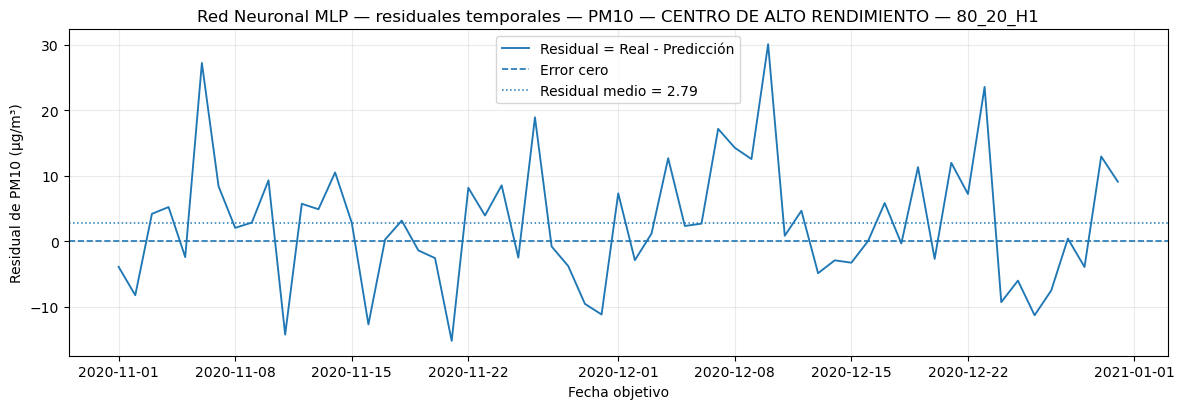

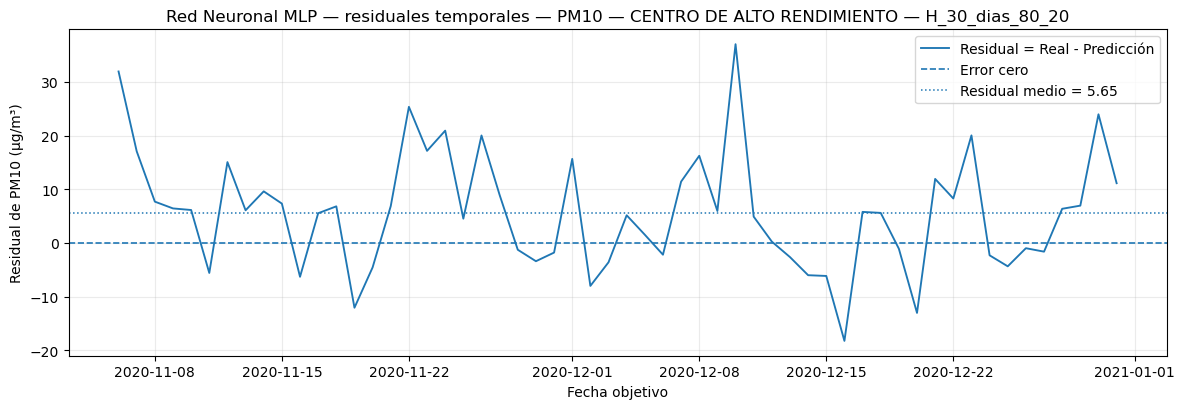

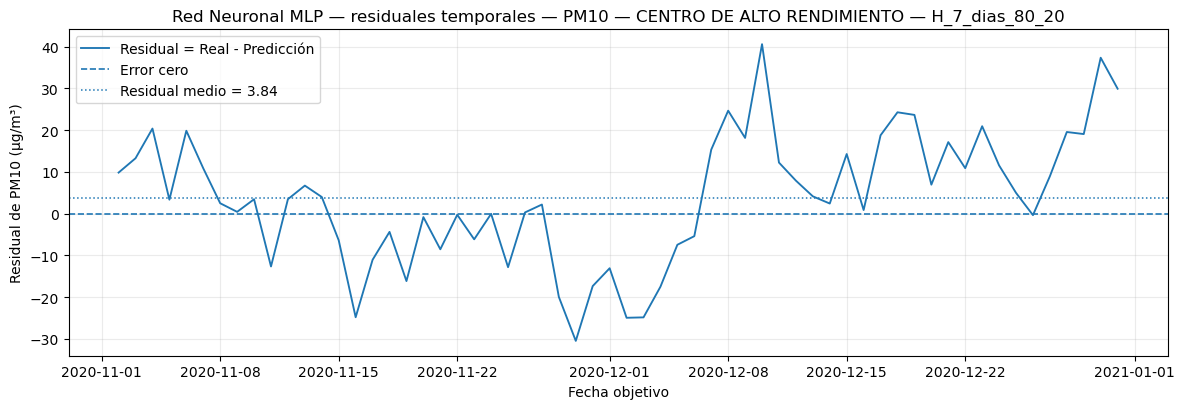

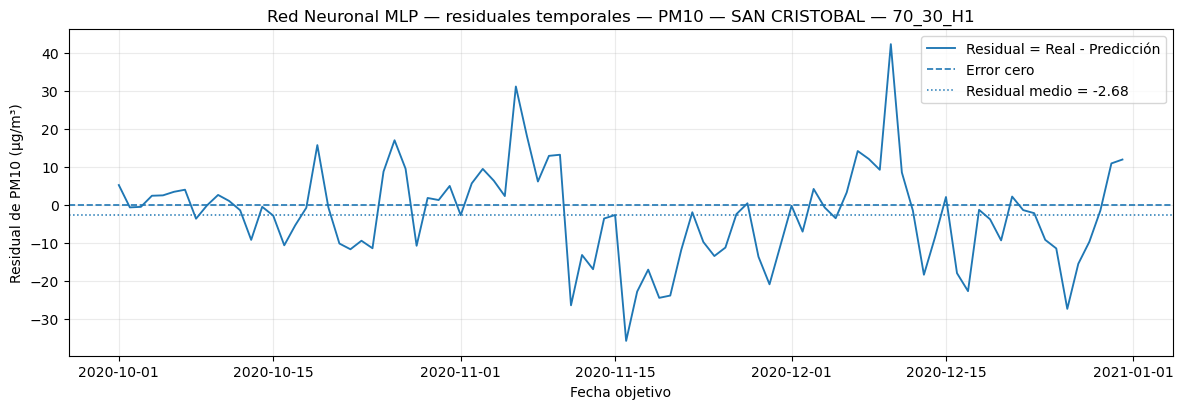

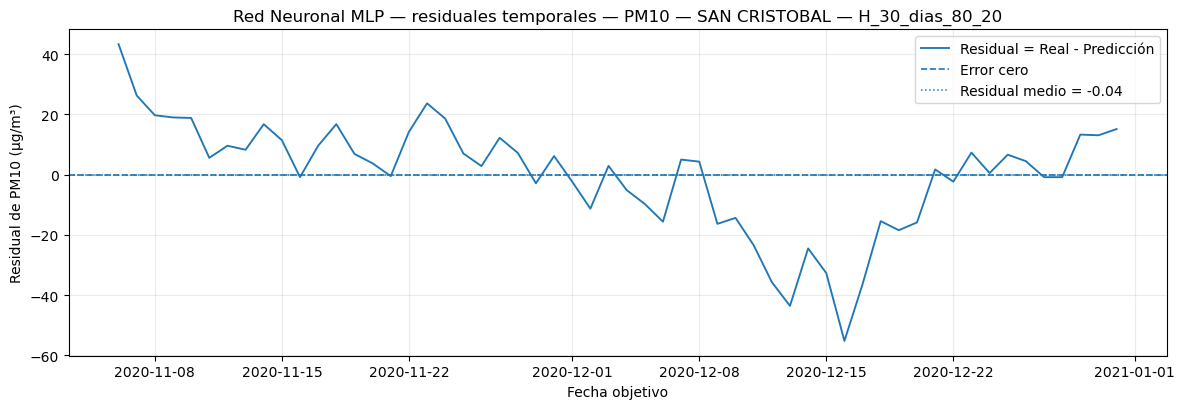

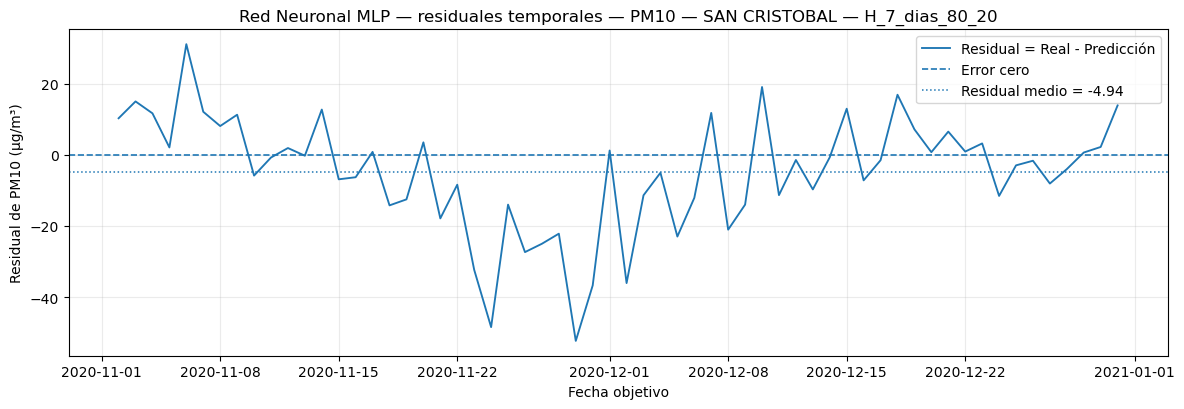

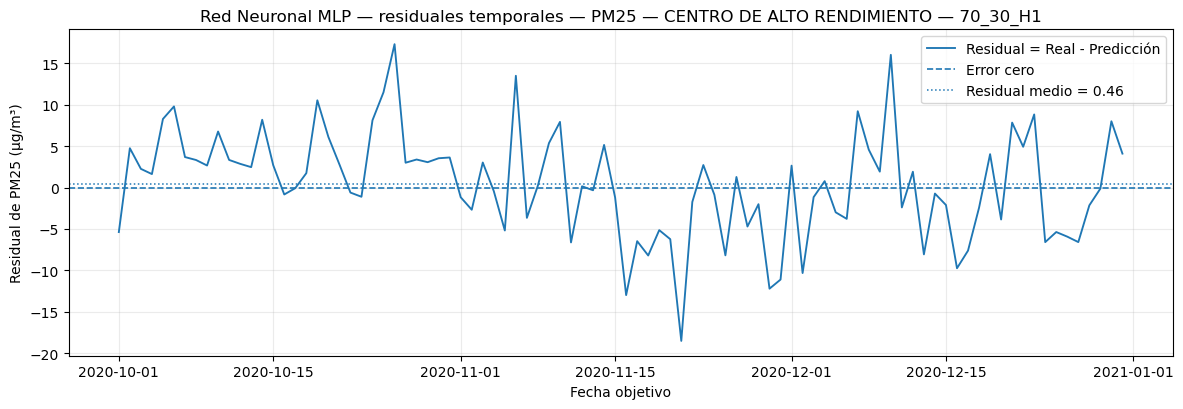

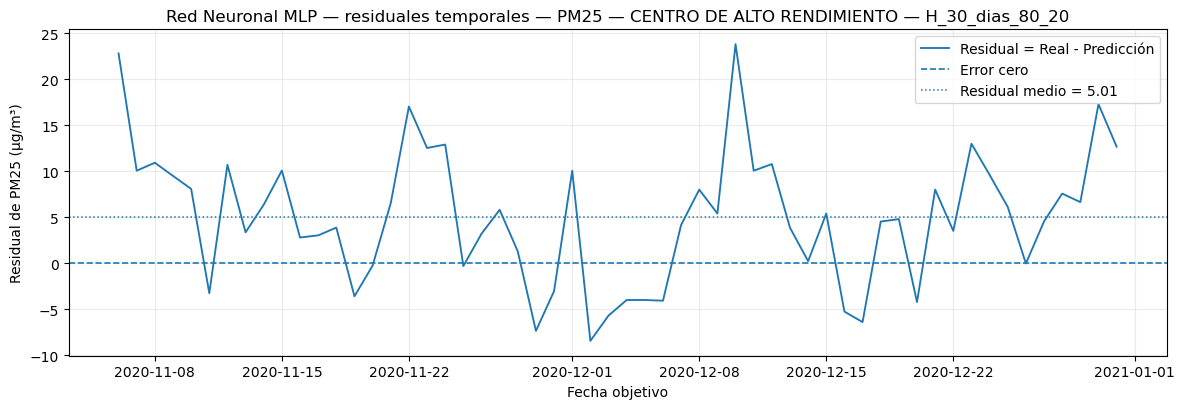

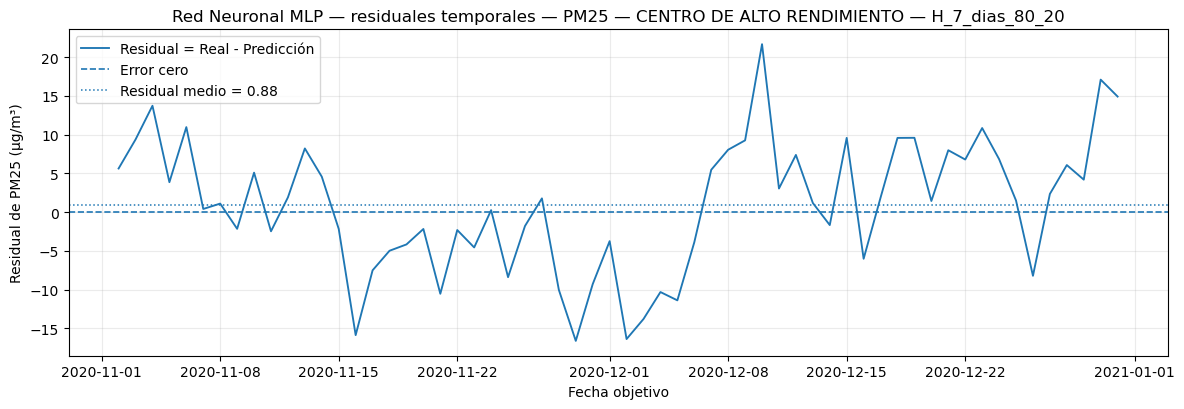

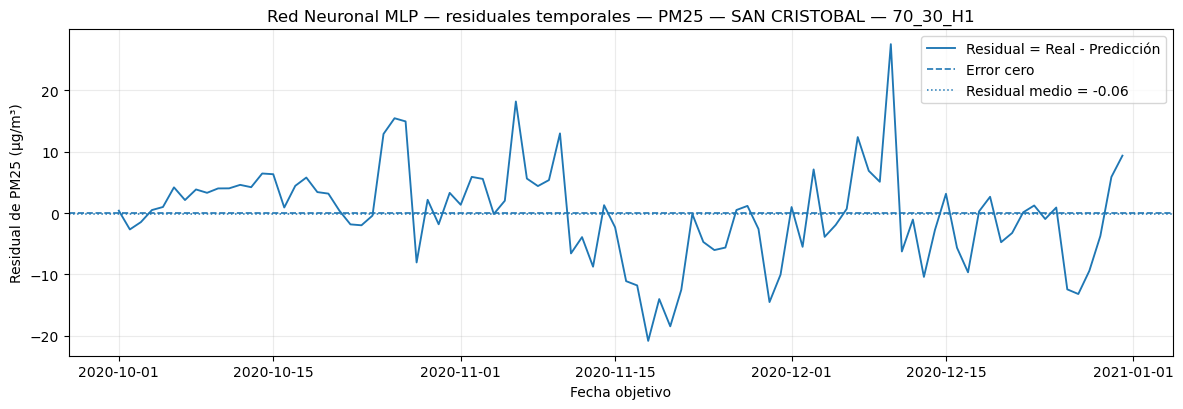

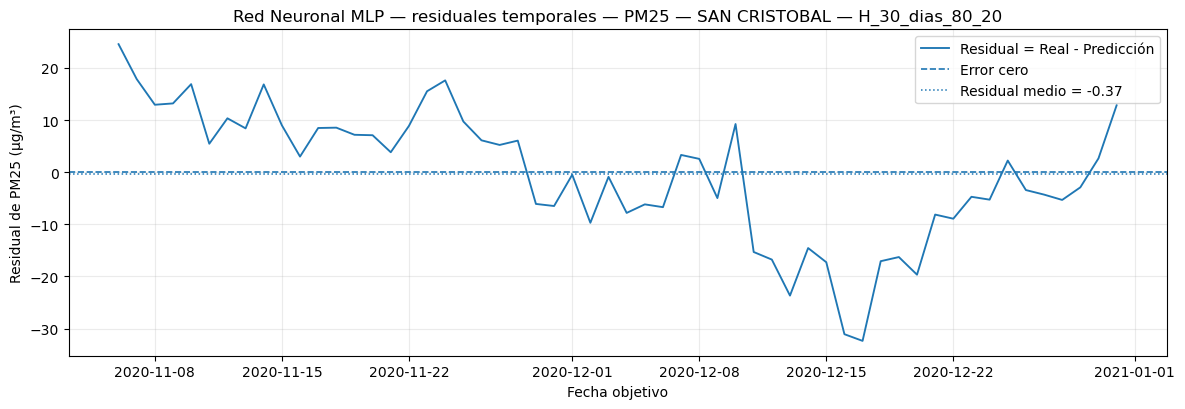

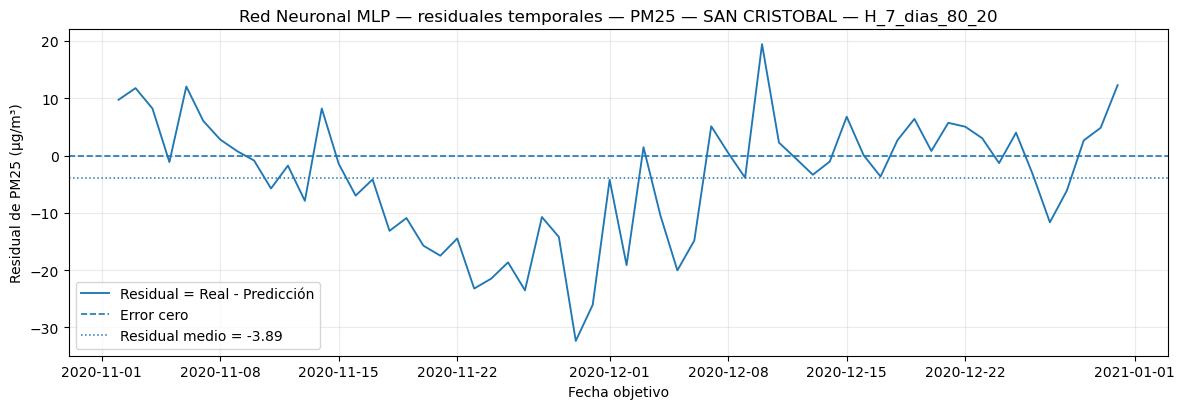

Resumen de residuales guardado en: C:\Users\santi\Prediccion_Bogota_un_anio_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL_NUEVOS_DATOS\tablas\MLP_resumen_residuales.csv
Gráficas residuales de todos los escenarios en: C:\Users\santi\Prediccion_Bogota_un_anio_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL_NUEVOS_DATOS\graficas\residuales_todos_escenarios


In [14]:
# ============================================================
# DIAGNÓSTICO TEMPORAL DE RESIDUALES: REAL - PREDICCIÓN
# ============================================================

if predicciones_mlp_df.empty:
    raise ValueError("No hay predicciones disponibles para calcular residuales.")

# Residual con convención explícita para la tesis: observado menos predicho.
predicciones_mlp_df = predicciones_mlp_df.copy()
predicciones_mlp_df["Residual"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Prediccion"]
predicciones_mlp_df["Error_absoluto"] = predicciones_mlp_df["Residual"].abs()
if "Persistencia" in predicciones_mlp_df.columns:
    predicciones_mlp_df["Residual_persistencia"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Persistencia"]

# Resumen de diagnóstico residual por escenario.
def _autocorr_lag1_residual(serie):
    serie = pd.Series(serie).dropna()
    return serie.autocorr(lag=1) if len(serie) >= 3 else np.nan

resumen_residuales_mlp = (
    predicciones_mlp_df
    .groupby(["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"], as_index=False)
    .agg(
        N_residuales=("Residual", "count"),
        Residual_medio=("Residual", "mean"),
        Residual_mediana=("Residual", "median"),
        Residual_desv_std=("Residual", "std"),
        MAE_desde_residual=("Error_absoluto", "mean"),
        P95_error_absoluto=("Error_absoluto", lambda x: x.quantile(0.95)),
        Max_error_absoluto=("Error_absoluto", "max"),
        Autocorr_residual_lag1=("Residual", _autocorr_lag1_residual),
    )
    .sort_values(["Variable", "Estacion", "Horizonte_dias", "Escenario"])
    .reset_index(drop=True)
)

display(Markdown("## Diagnóstico de residuales — Red Neuronal MLP"))
display(resumen_residuales_mlp.round(4))

# Carpeta específica: se guardan todos los escenarios aunque solo se muestren los mejores.
GRAFICAS_RESIDUALES_MLP = GRAFICAS_MLP / "residuales_todos_escenarios"
GRAFICAS_RESIDUALES_MLP.mkdir(parents=True, exist_ok=True)

# Identificar mejores escenarios para mostrarlos en pantalla sin saturar el notebook.
_mejores_claves_mlp = set(
    zip(mejor_mlp["Variable"], mejor_mlp["Estacion"], mejor_mlp["Escenario"])
)

for (variable, estacion, escenario, horizonte), sub in predicciones_mlp_df.groupby(
    ["Variable", "Estacion", "Escenario", "Horizonte_dias"]
):
    sub = sub.sort_values("Fecha_objetivo").copy()
    if sub.empty:
        continue

    media_residual = sub["Residual"].mean()

    plt.figure(figsize=(12, 4.2))
    plt.plot(sub["Fecha_objetivo"], sub["Residual"], linewidth=1.35, label="Residual = Real - Predicción")
    plt.axhline(0, linestyle="--", linewidth=1.2, label="Error cero")
    plt.axhline(media_residual, linestyle=":", linewidth=1.1, label=f"Residual medio = {media_residual:.2f}")
    plt.xlabel("Fecha objetivo")
    plt.ylabel(f"Residual de {variable} (µg/m³)")
    plt.title(f"Red Neuronal MLP — residuales temporales — {variable} — {estacion} — {escenario}")
    plt.legend(loc="best")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    nombre = nombre_seguro_mlp(f"{variable}_{estacion}_{escenario}_H{horizonte}")
    plt.savefig(
        GRAFICAS_RESIDUALES_MLP / f"MLP_residual_{nombre}.png",
        dpi=180,
        bbox_inches="tight"
    )

    # Solo se muestra el mejor escenario por estación/variable; los demás quedan guardados.
    if (variable, estacion, escenario) in _mejores_claves_mlp:
        plt.show()
    plt.close()

# Tabla específica de residuales para trazabilidad.
ruta_residuales_mlp = TABLAS_MLP / "MLP_resumen_residuales.csv"
resumen_residuales_mlp.to_csv(ruta_residuales_mlp, index=False, encoding="utf-8-sig")
print("Resumen de residuales guardado en:", ruta_residuales_mlp.resolve())
print("Gráficas residuales de todos los escenarios en:", GRAFICAS_RESIDUALES_MLP.resolve())


## Figuras completas por intervalo: entrenamiento, predicción y residual

Para cada escenario se presenta una figura con dos paneles sincronizados en el tiempo:

1. **Panel superior:** serie observada usada como entrenamiento, serie observada de prueba y predicción del modelo. La línea vertical marca el inicio del conjunto de prueba. Cuando existe una purga temporal, se identifica visualmente entre el final del entrenamiento y el inicio de prueba.
2. **Panel inferior:** residual fuera de muestra, definido como \(e_t = y_t - \hat{y}_t\). Un residual positivo indica subestimación y uno negativo indica sobreestimación.

El residual se calcula sobre **prueba**, porque es donde se evalúa la capacidad predictiva fuera de muestra. No se desplaza la predicción para mejorar artificialmente su coincidencia visual.


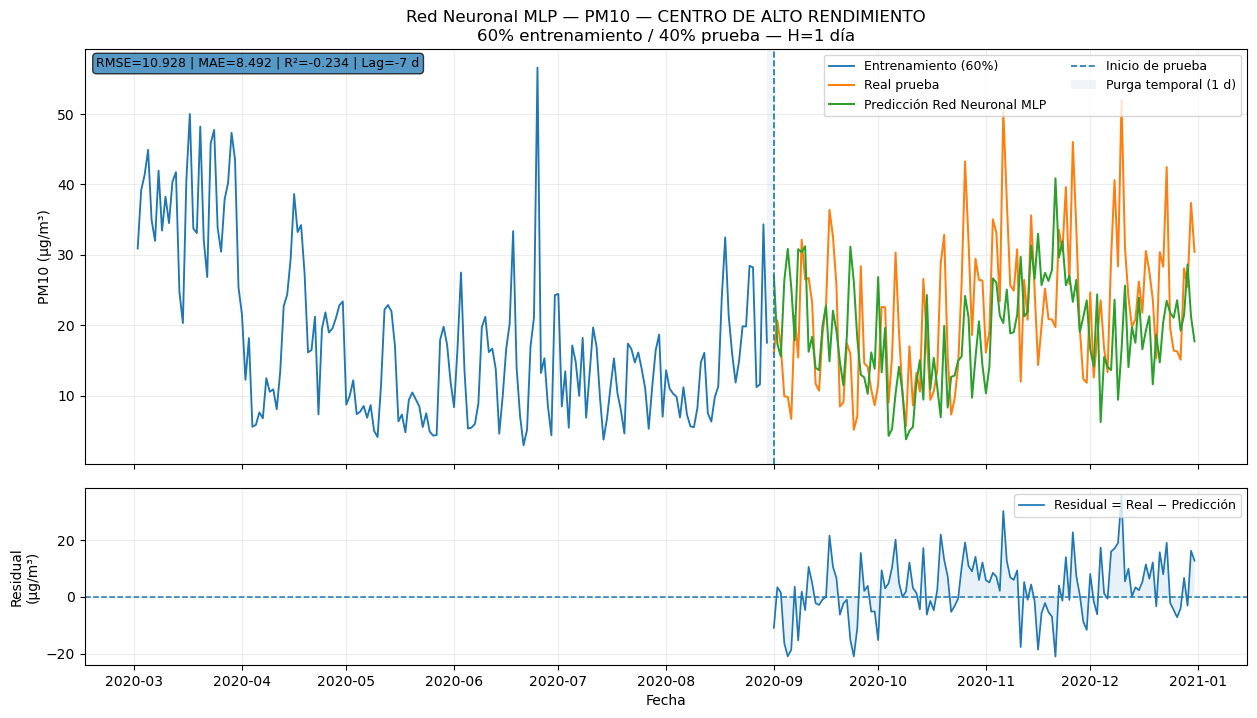

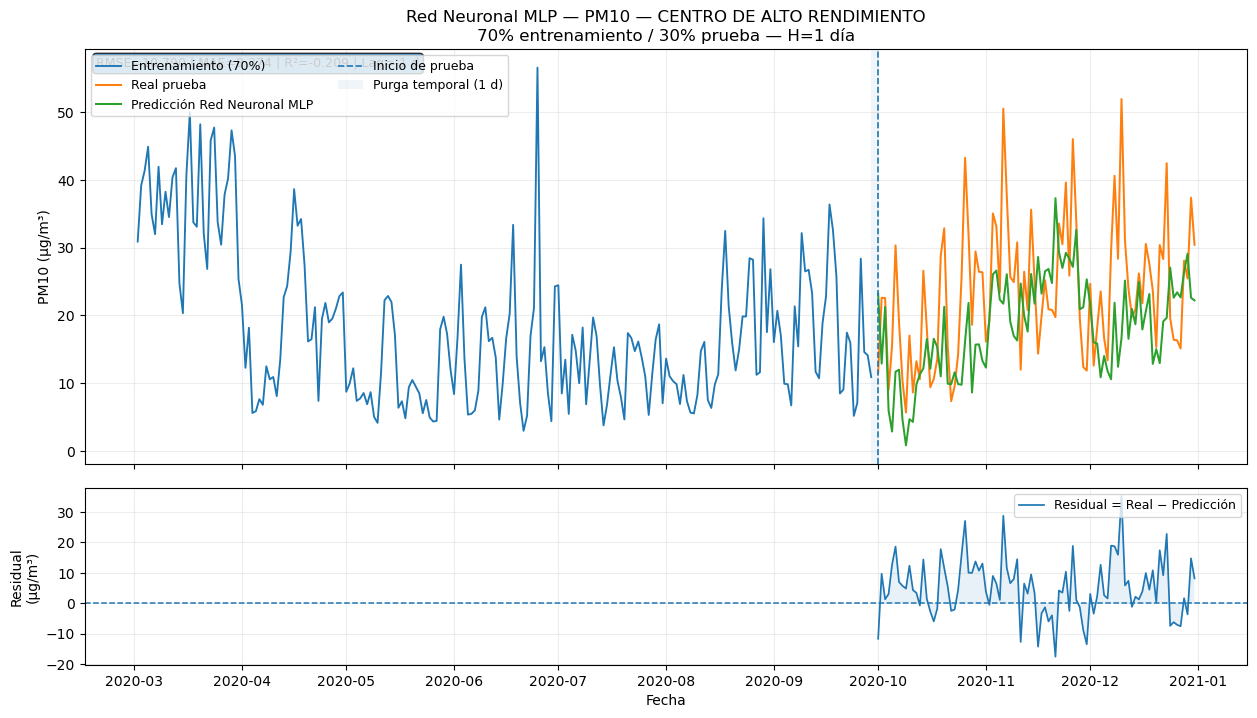

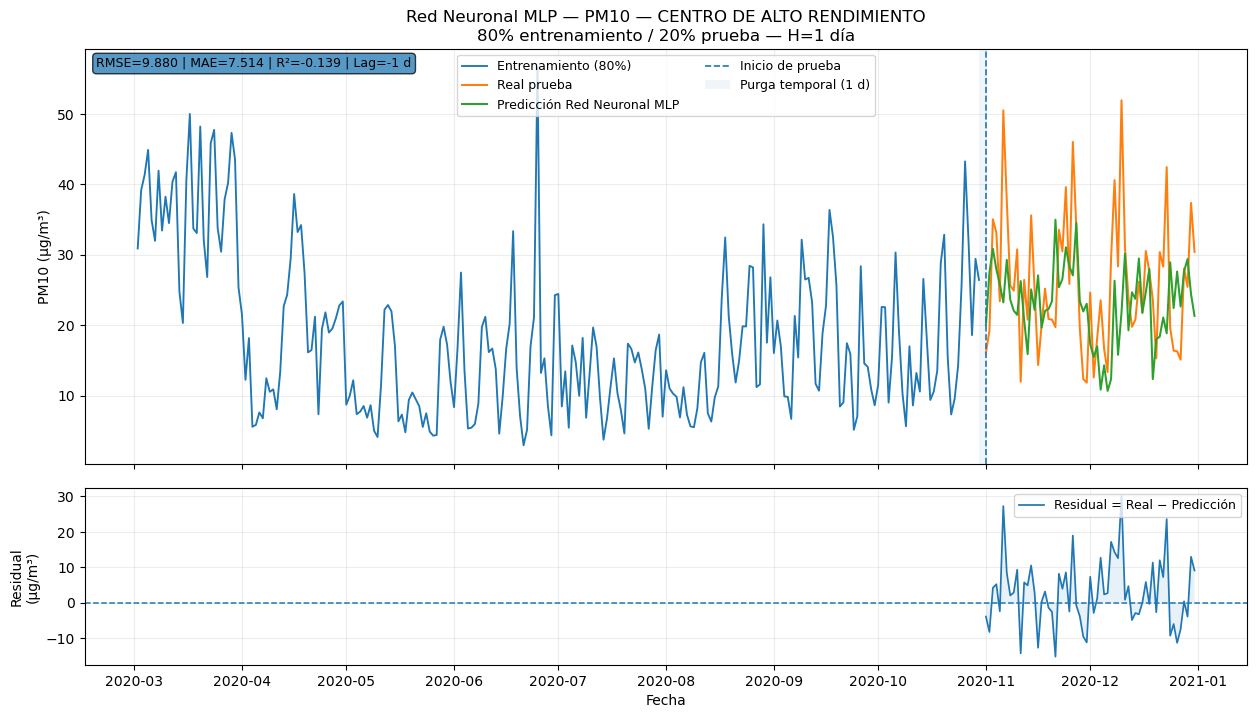

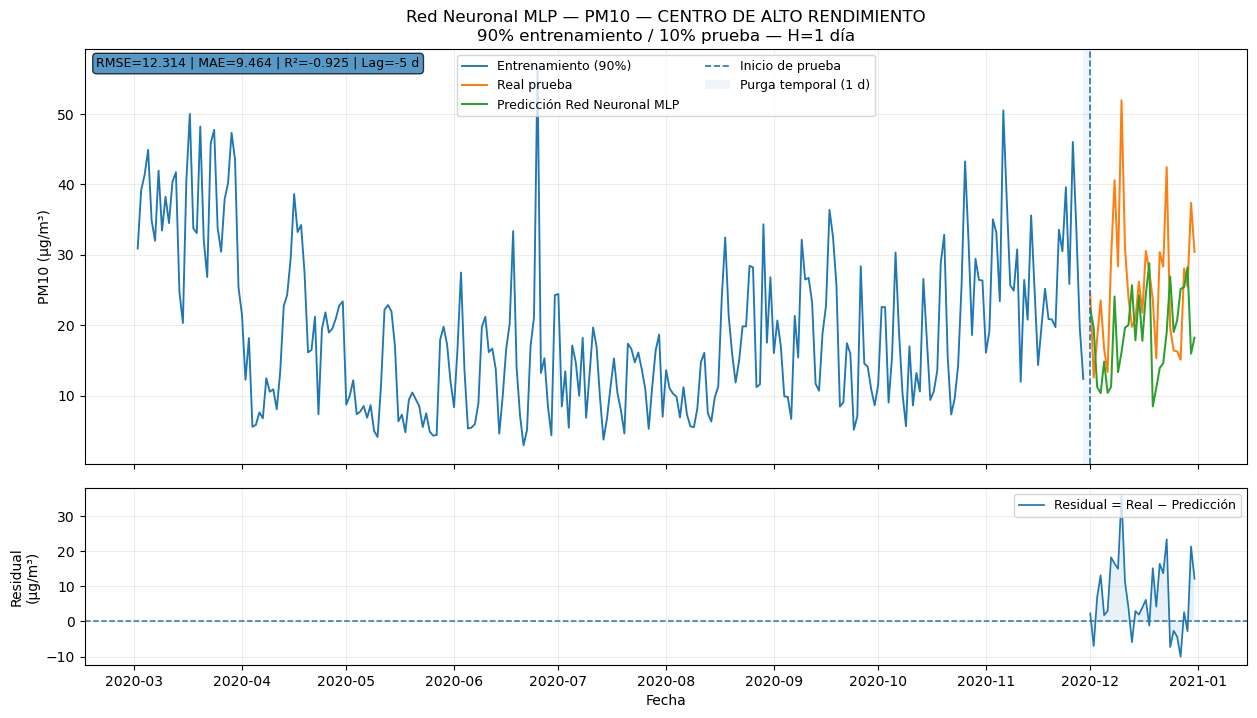

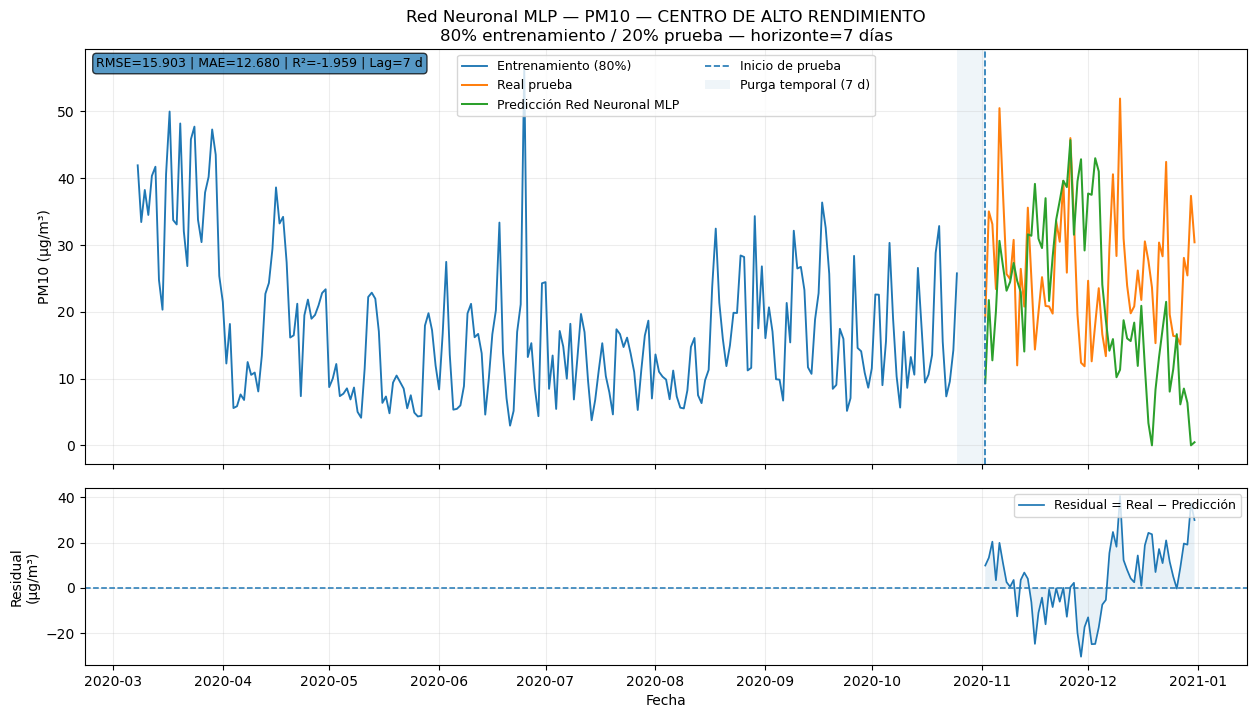

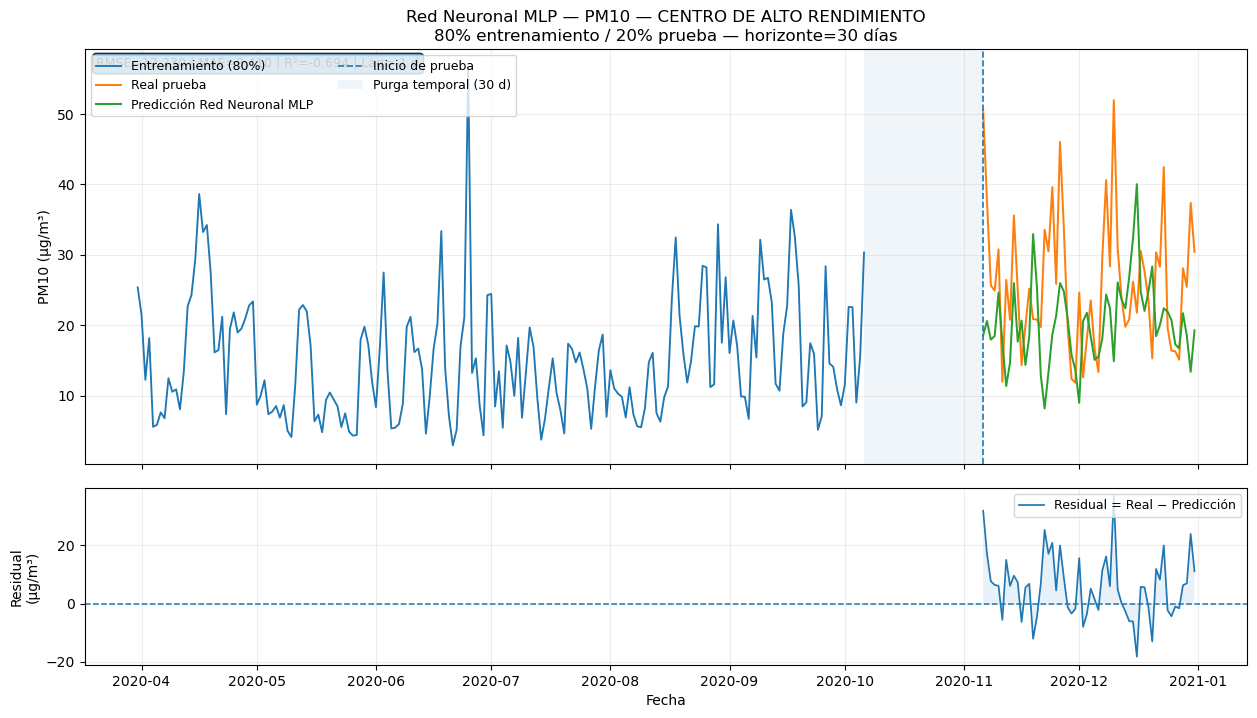

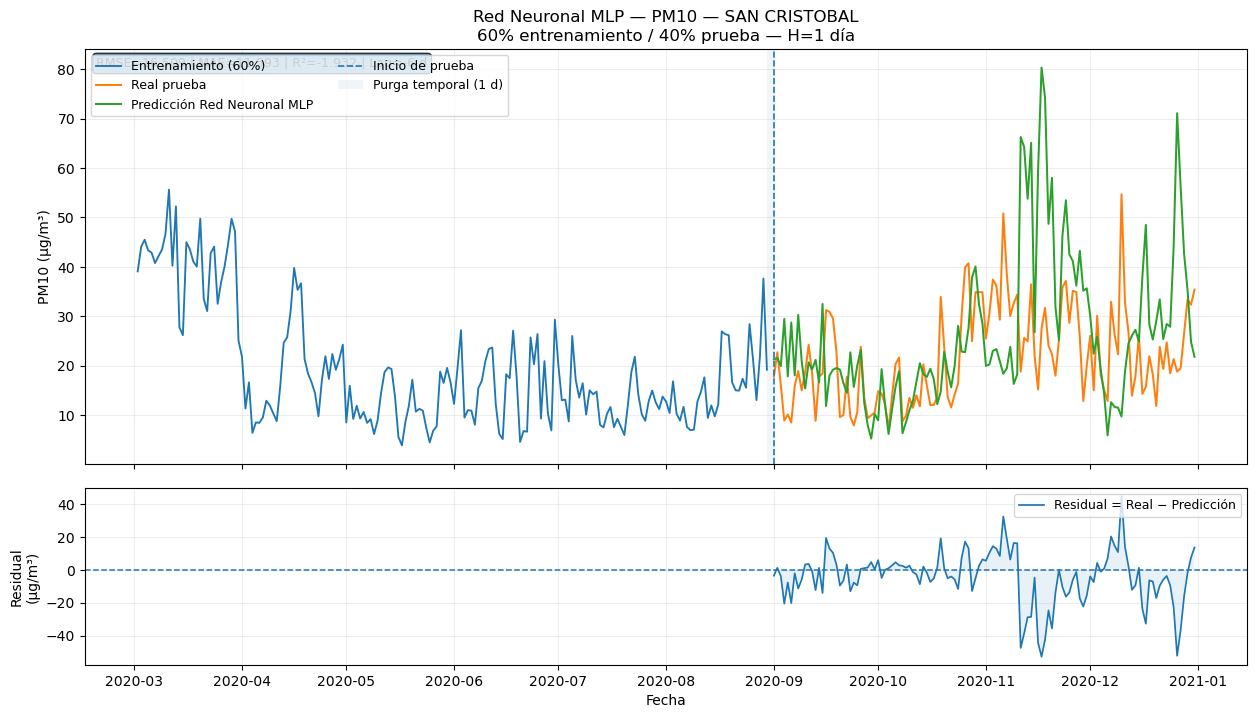

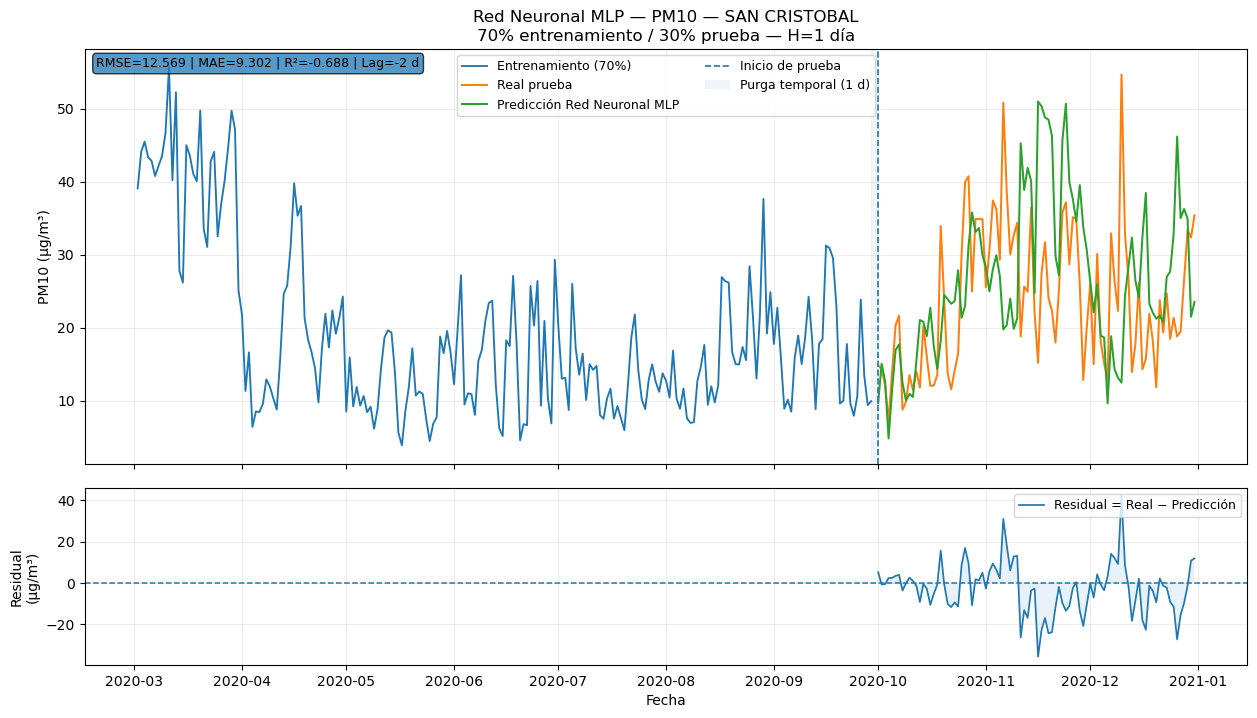

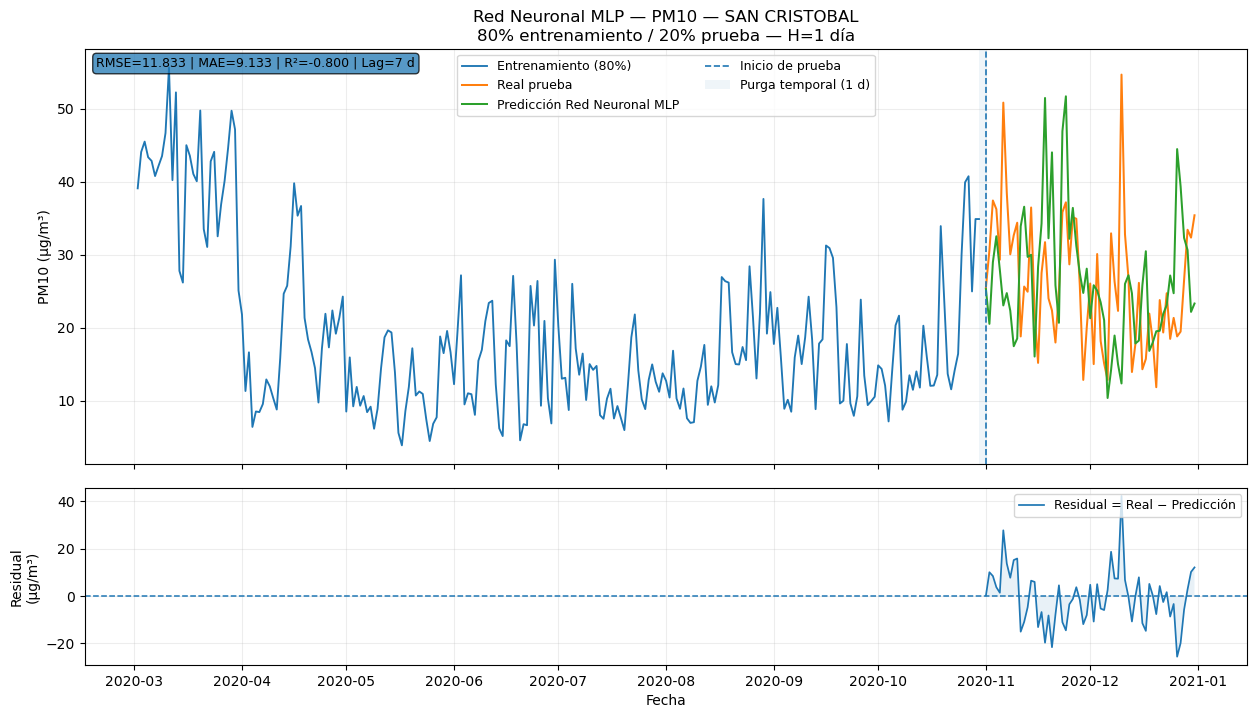

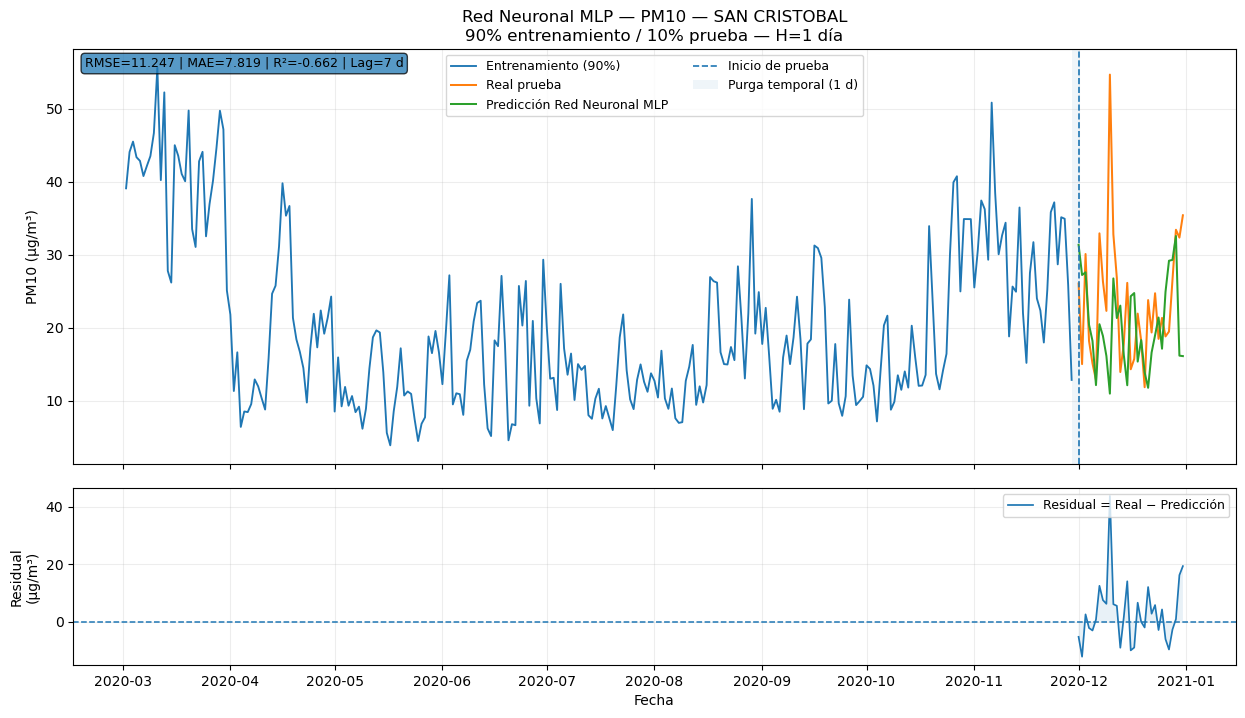

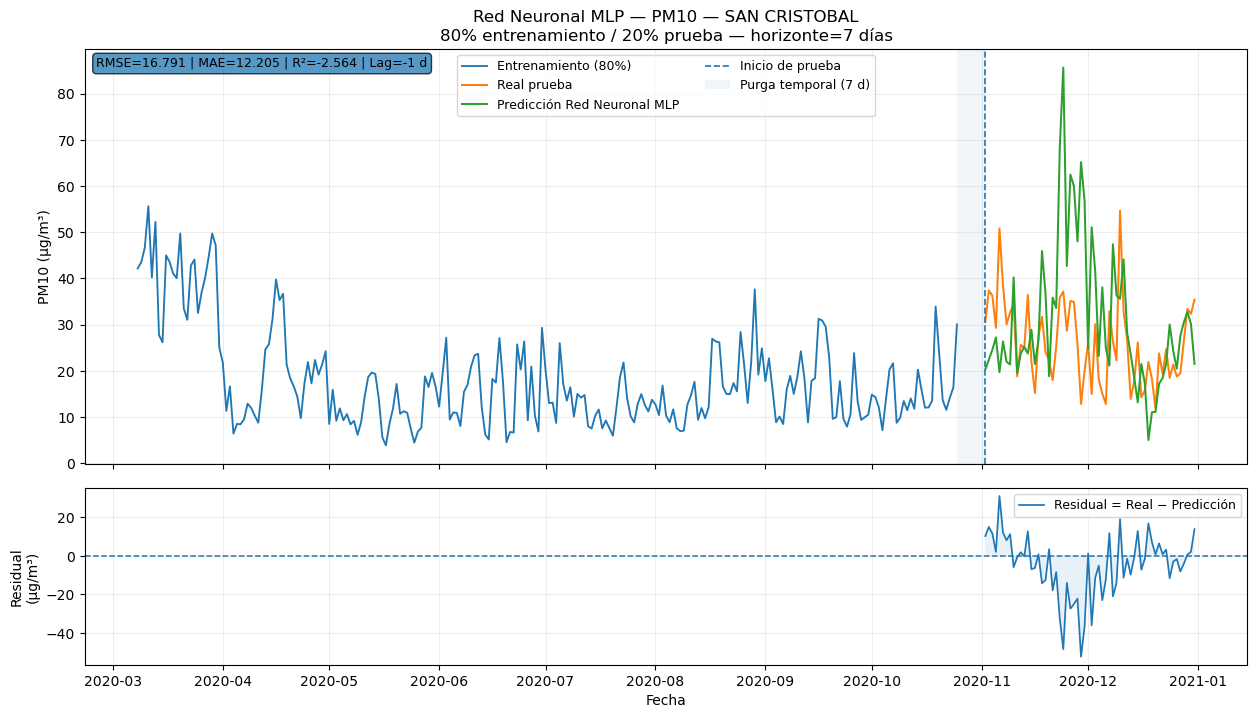

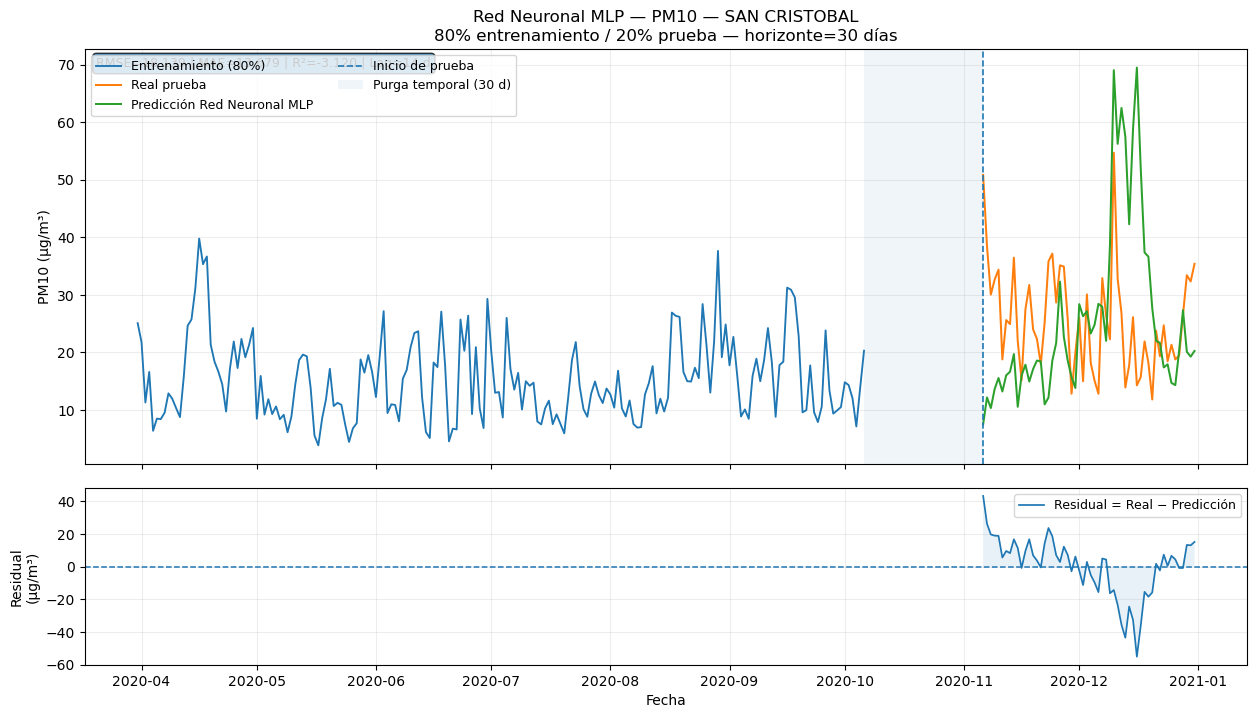

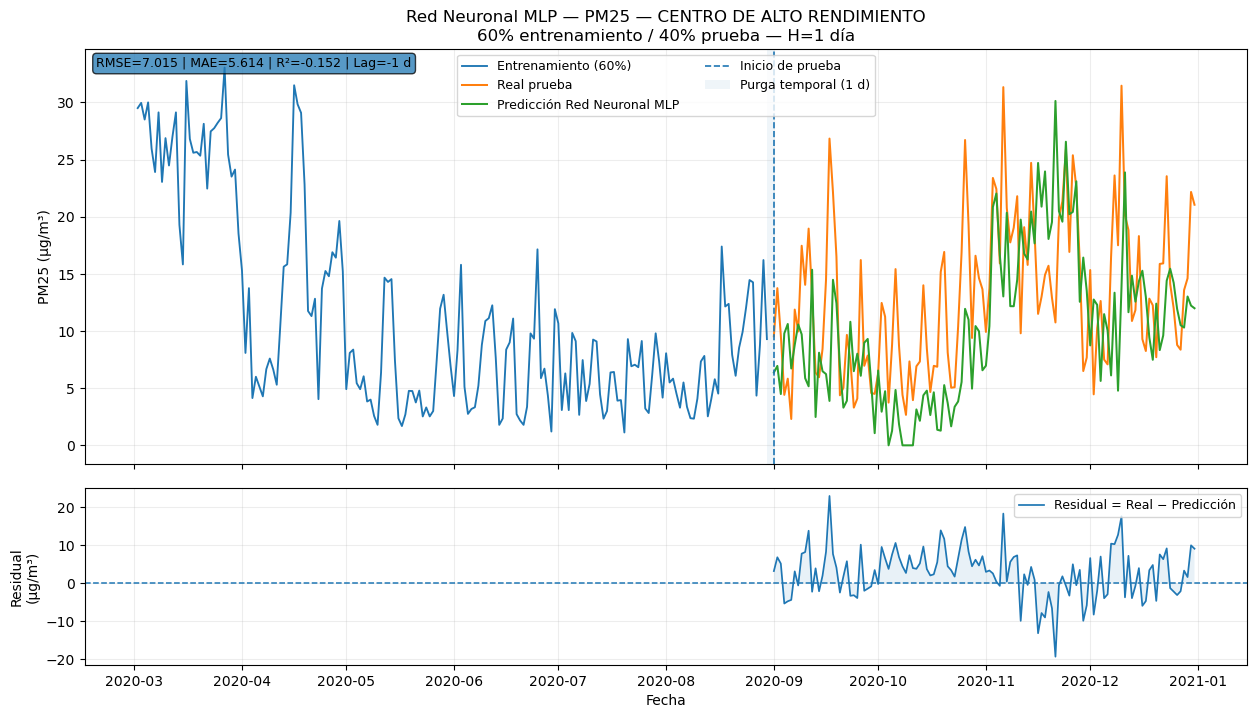

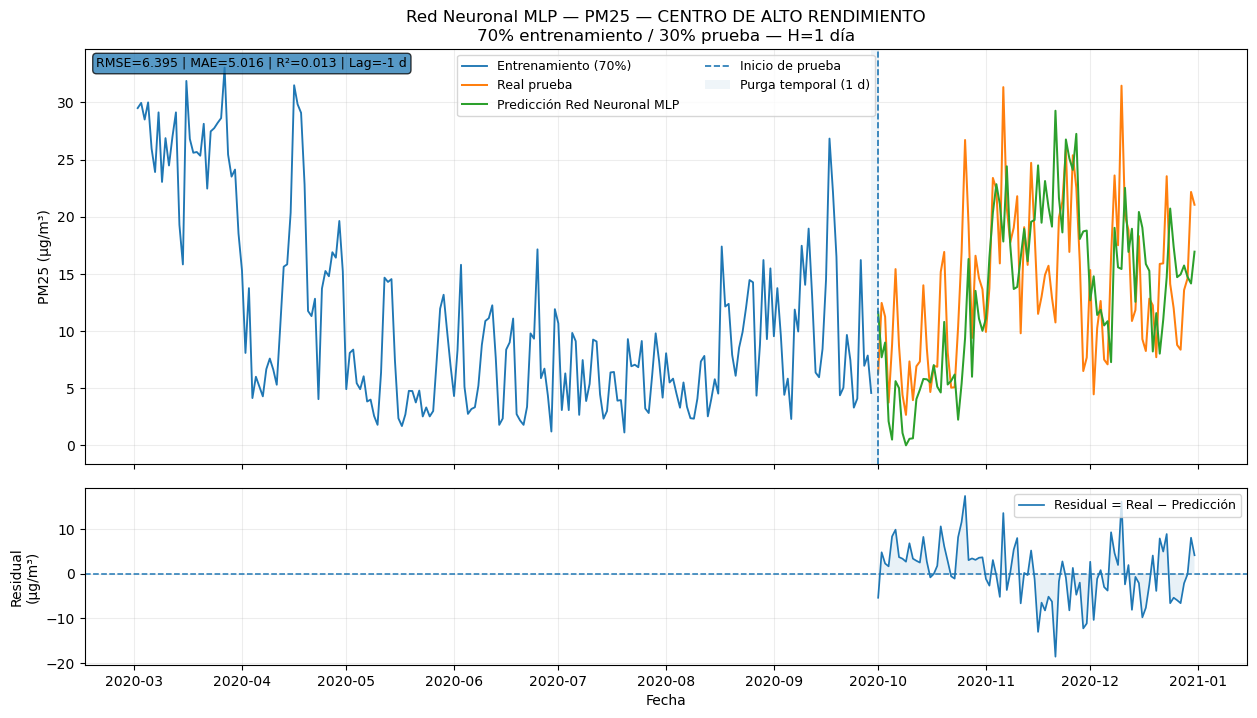

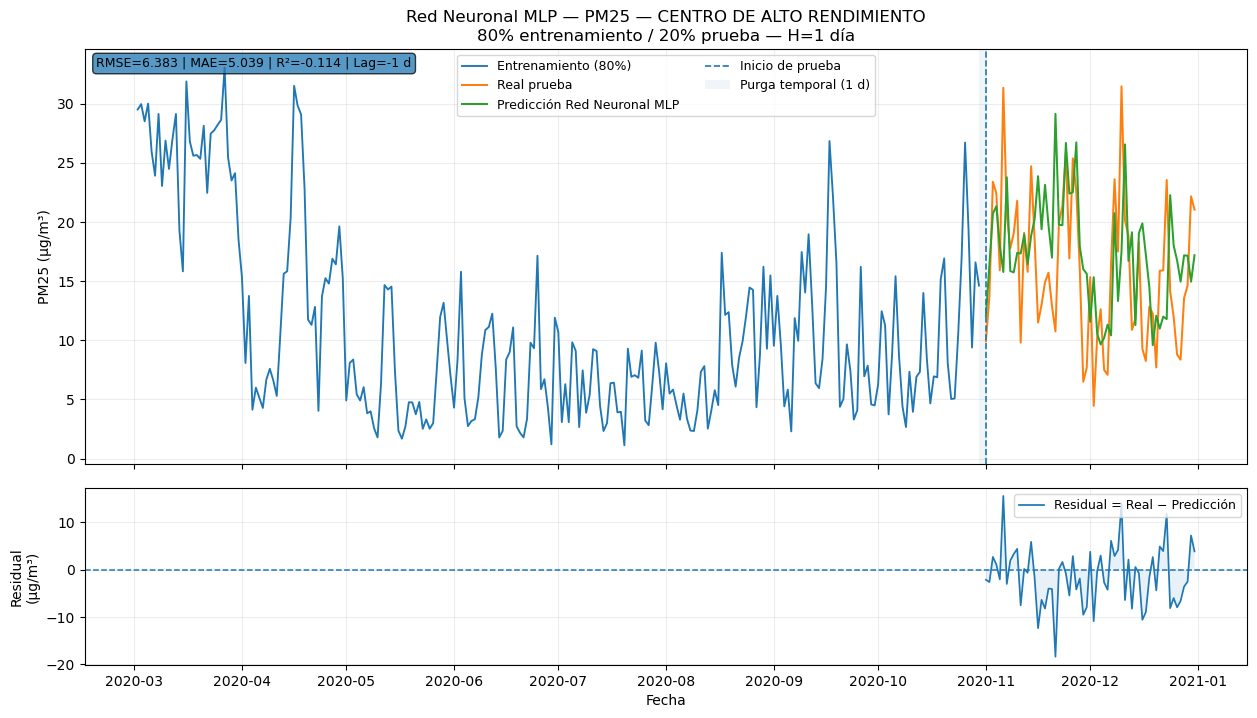

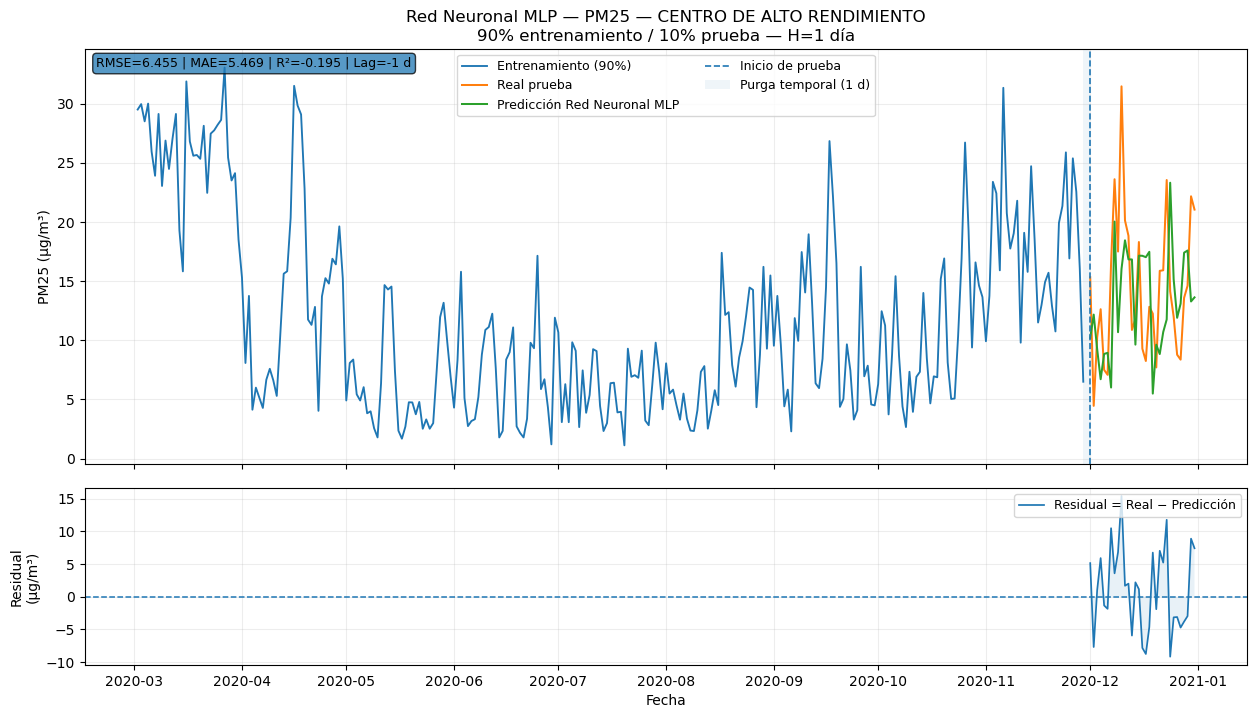

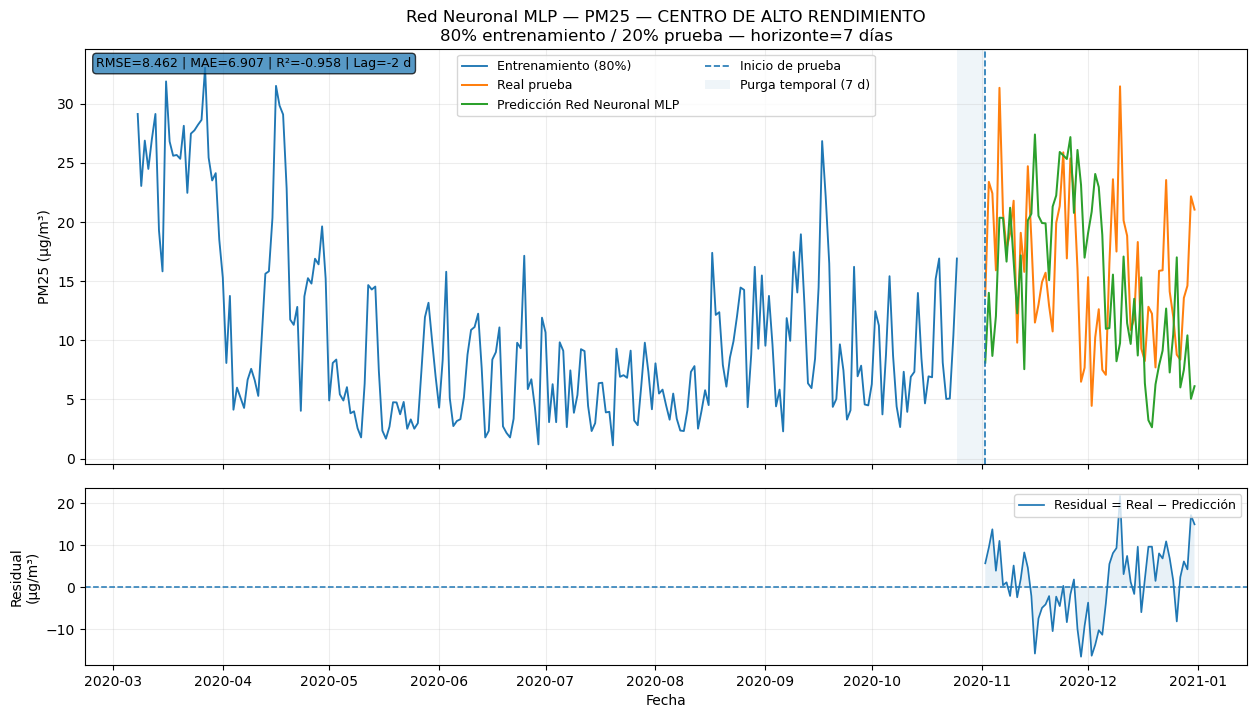

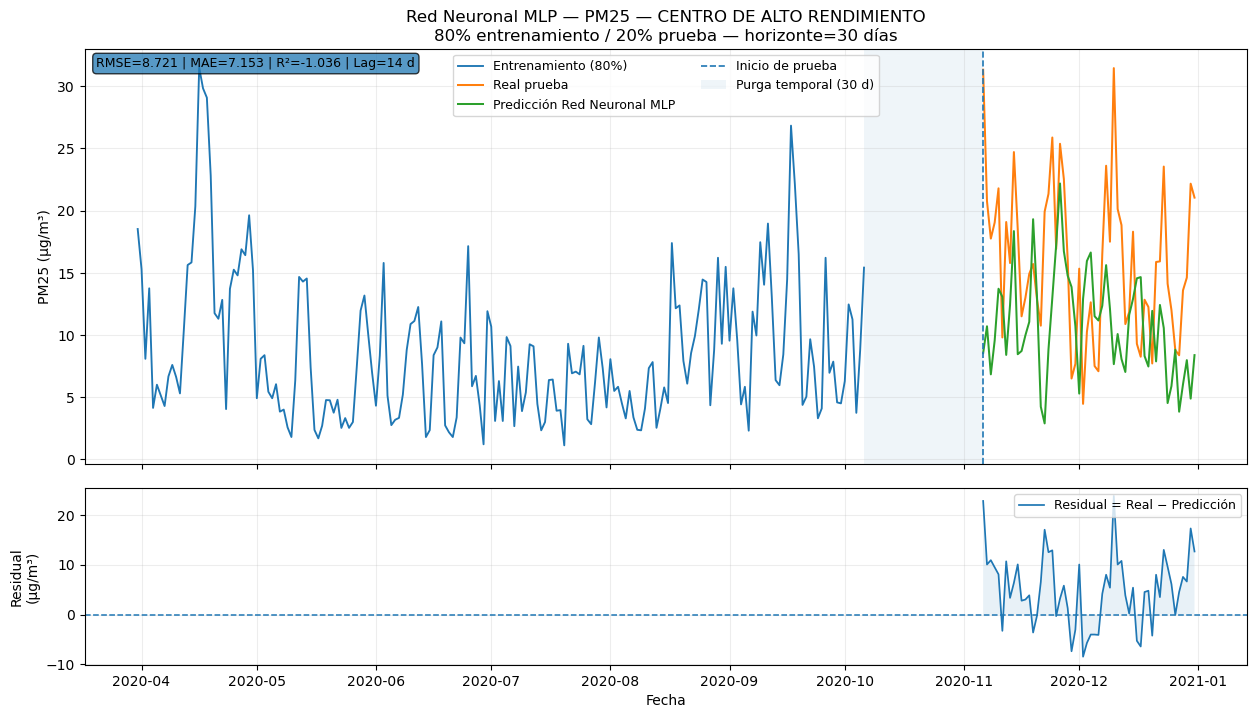

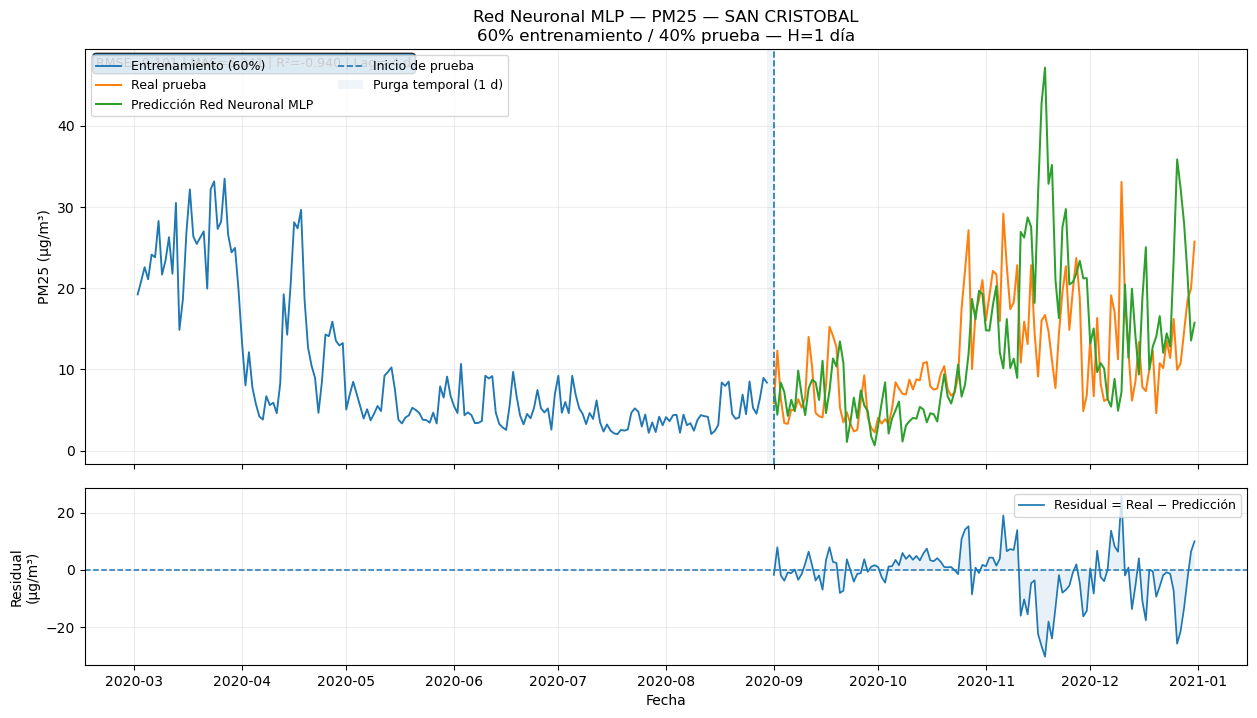

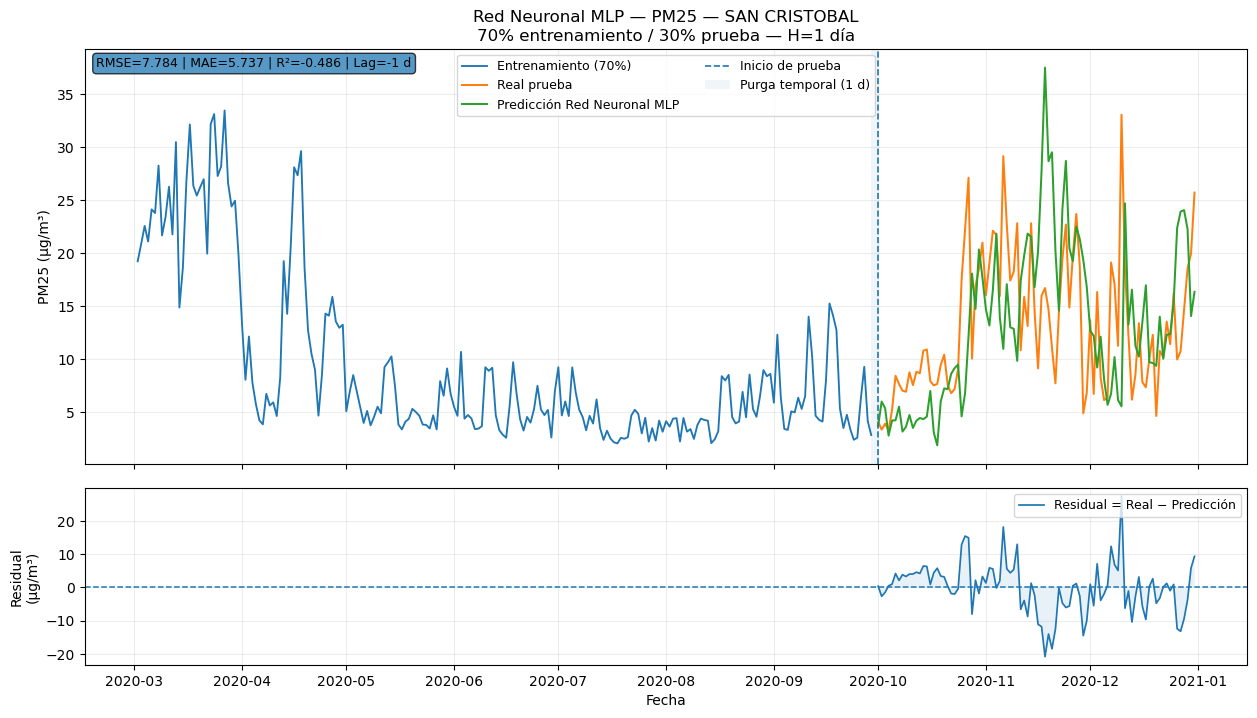

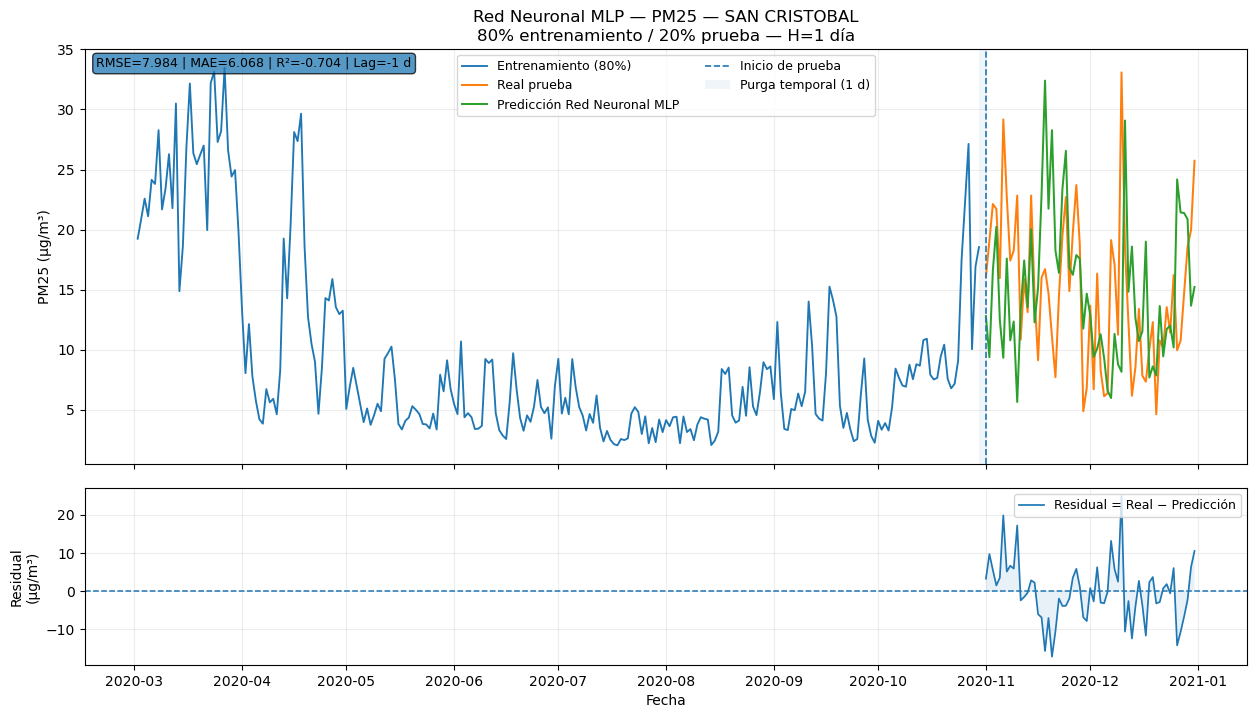

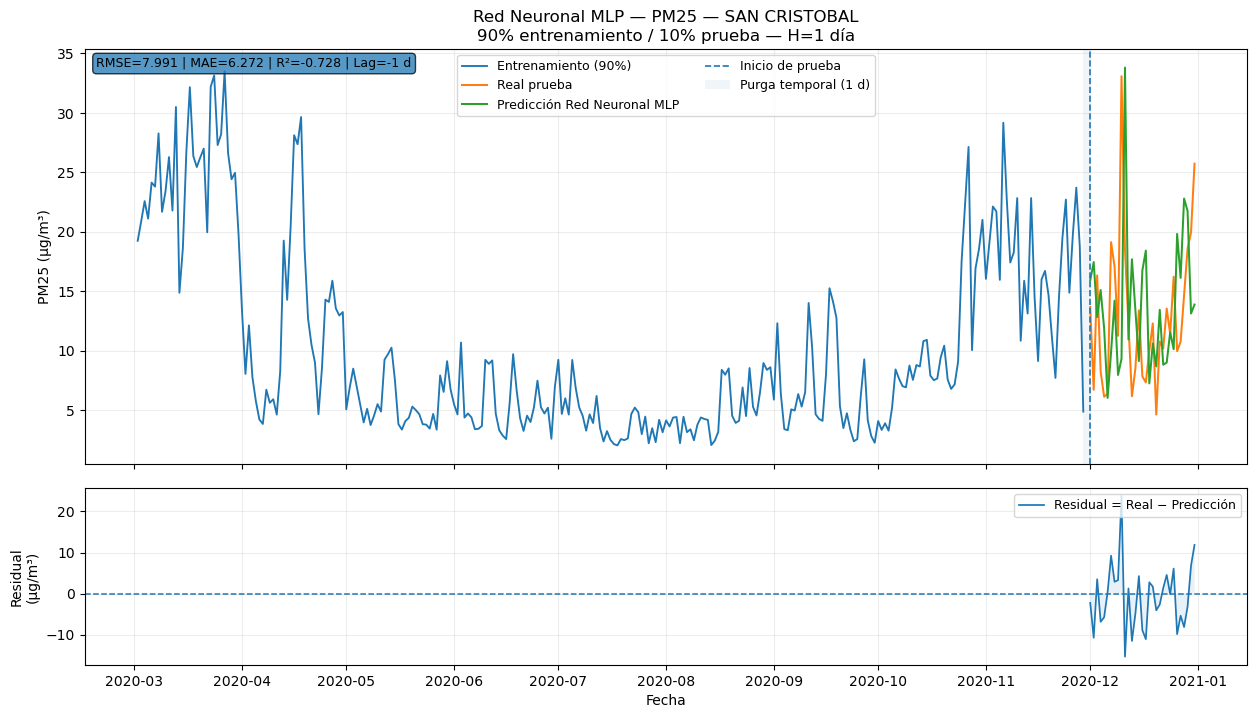

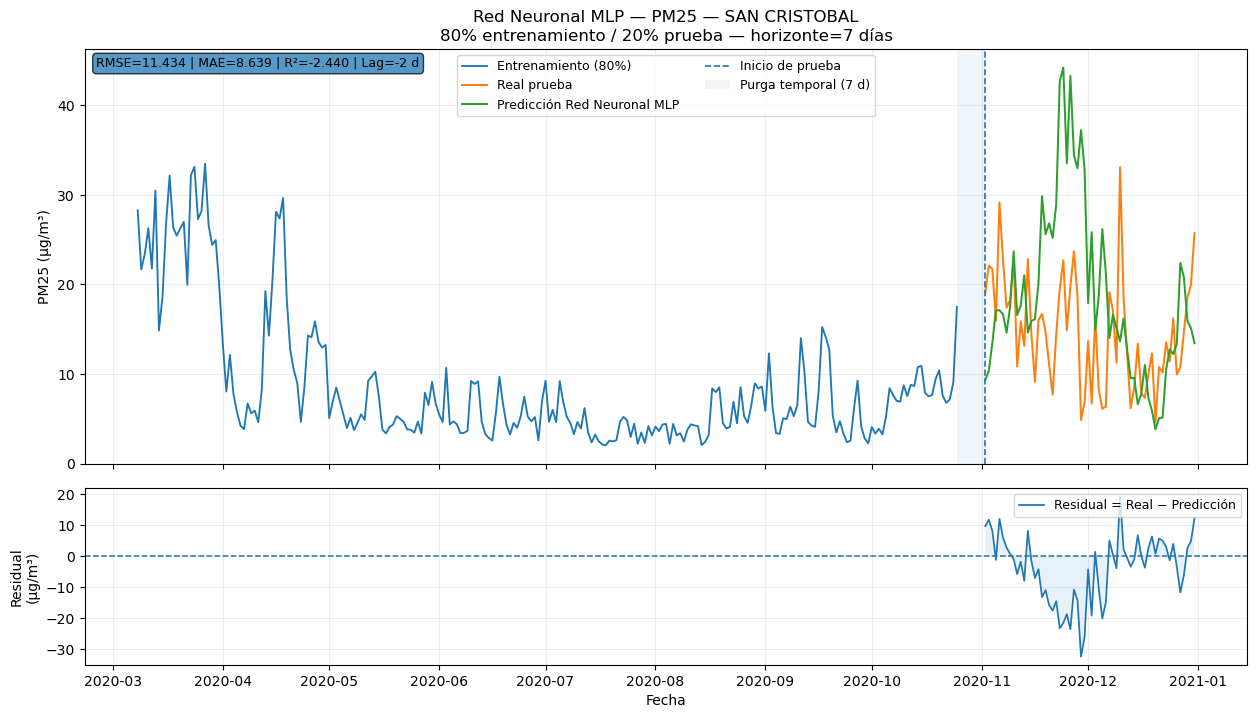

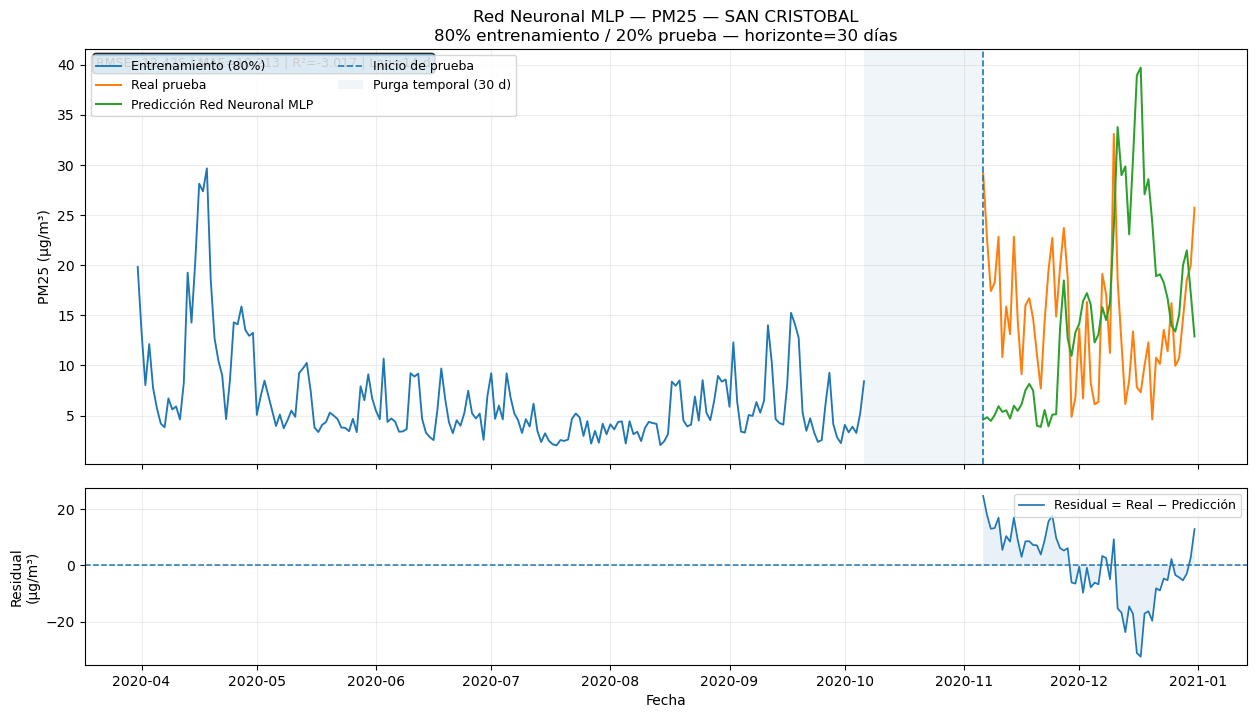

Figuras entrenamiento/prueba + residual generadas: 24


In [15]:
# V3_GRAFICAS_TRAIN_TEST_RESIDUAL
# ============================================================
# FIGURAS POR CADA INTERVALO: ENTRENAMIENTO + PRUEBA/PREDICCIÓN
# Y RESIDUAL (REAL - PREDICCIÓN) EN PANEL INFERIOR
# ============================================================

# Asegurar tipos temporales y residual.
predicciones_mlp_df = predicciones_mlp_df.copy()
predicciones_mlp_df["Fecha_objetivo"] = pd.to_datetime(predicciones_mlp_df["Fecha_objetivo"], errors="coerce")
predicciones_mlp_df["Residual"] = predicciones_mlp_df["Real"] - predicciones_mlp_df["Prediccion"]

_base_graf_mlp = base_mlp.copy()
_base_graf_mlp["Fecha inicial"] = pd.to_datetime(_base_graf_mlp["Fecha inicial"], errors="coerce")


def _etiqueta_intervalo_mlp(tipo, train_nominal, horizonte):
    train_nominal = float(train_nominal)
    test_nominal = 100.0 - train_nominal
    if str(tipo).lower().startswith("particion"):
        return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — H=1 día"
    return f"{train_nominal:.0f}% entrenamiento / {test_nominal:.0f}% prueba — horizonte={int(horizonte)} días"


def _graficar_intervalo_mlp(fila_cfg):
    variable = fila_cfg["Variable"]
    estacion = fila_cfg["Estacion"]
    escenario = fila_cfg["Escenario"]
    tipo_eval = fila_cfg["Tipo_evaluacion"]
    horizonte = int(fila_cfg["Horizonte_dias"])

    sub = predicciones_mlp_df[
        (predicciones_mlp_df["Variable"] == variable) &
        (predicciones_mlp_df["Estacion"] == estacion) &
        (predicciones_mlp_df["Escenario"] == escenario)
    ].sort_values("Fecha_objetivo").copy()
    if sub.empty:
        return

    # Configuración temporal registrada para este escenario.
    trow = tiempos_mlp_df[
        (tiempos_mlp_df["Variable"] == variable) &
        (tiempos_mlp_df["Estacion"] == estacion) &
        (tiempos_mlp_df["Escenario"] == escenario)
    ]
    if trow.empty:
        train_nominal = 80.0
        gap_dias = horizonte
    else:
        train_nominal = float(trow.iloc[0]["Train_nominal_%"])
        gap_dias = int(trow.iloc[0].get("Gap_purga_dias", horizonte))

    # Fechas exactas del tramo de entrenamiento utilizadas por el protocolo.
    train_info = metricas_mlp_df[
        (metricas_mlp_df["Variable"] == variable) &
        (metricas_mlp_df["Estacion"] == estacion) &
        (metricas_mlp_df["Escenario"] == escenario) &
        (metricas_mlp_df["Etapa"] == "Entrenamiento")
    ]

    fecha_test_inicio = pd.to_datetime(sub["Fecha_objetivo"].min())
    if not train_info.empty:
        fecha_train_inicio = pd.to_datetime(train_info.iloc[0]["Fecha_inicio"])
        fecha_train_fin = pd.to_datetime(train_info.iloc[0]["Fecha_fin"])
    else:
        fecha_train_inicio = pd.to_datetime(_base_graf_mlp["Fecha inicial"].min())
        fecha_train_fin = fecha_test_inicio - pd.Timedelta(days=max(1, gap_dias))

    serie = _base_graf_mlp[
        (_base_graf_mlp["Estacion"] == estacion)
    ][["Fecha inicial", variable]].copy()
    serie[variable] = pd.to_numeric(serie[variable], errors="coerce")
    serie = serie.dropna(subset=["Fecha inicial", variable]).sort_values("Fecha inicial")

    train_obs = serie[
        (serie["Fecha inicial"] >= fecha_train_inicio) &
        (serie["Fecha inicial"] <= fecha_train_fin)
    ].copy()

    residual = sub["Residual"].astype(float)
    rmse = float(np.sqrt(np.nanmean(np.square(residual)))) if residual.notna().any() else np.nan
    mae = float(np.nanmean(np.abs(residual))) if residual.notna().any() else np.nan
    r2_row = metricas_mlp_df[
        (metricas_mlp_df["Variable"] == variable) &
        (metricas_mlp_df["Estacion"] == estacion) &
        (metricas_mlp_df["Escenario"] == escenario) &
        (metricas_mlp_df["Etapa"] == "Prueba")
    ]
    r2 = float(r2_row.iloc[0]["R2"]) if (not r2_row.empty and "R2" in r2_row.columns) else np.nan
    lag = float(r2_row.iloc[0]["Lag_optimo_dias"]) if (not r2_row.empty and "Lag_optimo_dias" in r2_row.columns) else np.nan

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True,
        gridspec_kw={"height_ratios": [2.35, 1.0], "hspace": 0.08}
    )

    # Panel superior: mismo concepto visual de la figura solicitada.
    ax1.plot(train_obs["Fecha inicial"], train_obs[variable],
             label=f"Entrenamiento ({train_nominal:.0f}%)", linewidth=1.35)
    ax1.plot(sub["Fecha_objetivo"], sub["Real"],
             label="Real prueba", linewidth=1.45)
    ax1.plot(sub["Fecha_objetivo"], sub["Prediccion"],
             label="Predicción Red Neuronal MLP", linewidth=1.45)
    ax1.axvline(fecha_test_inicio, linestyle="--", linewidth=1.2, label="Inicio de prueba")

    # Mostrar la purga temporal sin confundirla con datos de prueba.
    if pd.notna(fecha_train_fin) and fecha_train_fin < fecha_test_inicio:
        ax1.axvspan(fecha_train_fin, fecha_test_inicio, alpha=0.07,
                    label=f"Purga temporal ({gap_dias} d)")

    etiqueta = _etiqueta_intervalo_mlp(tipo_eval, train_nominal, horizonte)
    ax1.set_title(f"Red Neuronal MLP — {variable} — {estacion}\n{etiqueta}")
    ax1.set_ylabel(f"{variable} (µg/m³)")
    ax1.grid(alpha=0.22)
    ax1.legend(ncol=2, fontsize=9)

    texto_metricas = f"RMSE={rmse:.3f} | MAE={mae:.3f} | R²={r2:.3f}"
    if np.isfinite(lag):
        texto_metricas += f" | Lag={lag:.0f} d"
    ax1.text(0.01, 0.98, texto_metricas, transform=ax1.transAxes,
             va="top", ha="left", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.3", alpha=0.75))

    # Panel inferior: resta Real - Predicción para las mismas fechas de prueba.
    ax2.plot(sub["Fecha_objetivo"], residual, linewidth=1.25, label="Residual = Real − Predicción")
    ax2.axhline(0, linestyle="--", linewidth=1.1)
    ax2.fill_between(sub["Fecha_objetivo"], residual, 0, alpha=0.10)
    ax2.set_ylabel("Residual\n(µg/m³)")
    ax2.set_xlabel("Fecha")
    ax2.grid(alpha=0.22)
    ax2.legend(loc="upper right", fontsize=9)

    fig.tight_layout()
    nombre = nombre_seguro_mlp(f"{variable}_{estacion}_{escenario}")
    ruta = GRAFICAS_MLP / f"MLP_train_test_residual_{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# Se muestran y guardan TODOS los escenarios: 60/40, 70/30, 80/20, 90/10, H7, H30 y H90.
_cfg_graficas_mlp = (
    predicciones_mlp_df[["Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]]
    .drop_duplicates()
    .merge(
        tiempos_mlp_df[["Variable", "Estacion", "Escenario", "Orden_escenario"]].drop_duplicates(),
        on=["Variable", "Estacion", "Escenario"], how="left"
    )
    .sort_values(["Variable", "Estacion", "Orden_escenario", "Horizonte_dias"])
)

for _, _fila_cfg in _cfg_graficas_mlp.iterrows():
    _graficar_intervalo_mlp(_fila_cfg)

print(f"Figuras entrenamiento/prueba + residual generadas: {len(_cfg_graficas_mlp)}")


## Tiempo de ejecución por intervalo de predicción

El tiempo total del notebook se conserva como referencia global, pero la tabla principal de costo computacional se desagrega por escenario. Para cada intervalo se acumulan los tiempos de validación temporal, entrenamiento final y predicción de todas las estaciones/contaminantes procesados en ese escenario. También se conserva el detalle por configuración con sus hiperparámetros seleccionados.


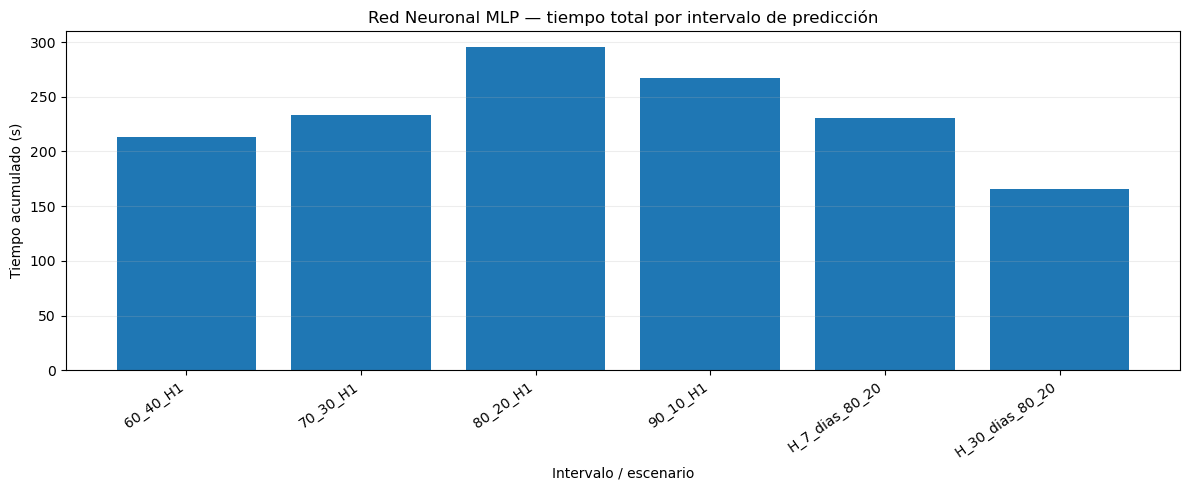

### Tiempo de código por partición porcentual

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,4,201.7539,10.2946,0.0415,213.1832,53.2958,3.5531
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,4,215.1940,16.8852,0.0431,233.2126,58.3031,3.8869
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,4,279.5881,14.3813,0.0414,295.1046,73.7761,4.9184
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,4,251.4510,14.9008,0.0572,267.5184,66.8796,4.4586


### Tiempo de código por horizonte fijo

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,4,213.9321,15.4092,0.0415,230.4574,57.6143,3.8410
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,4,155.3937,9.4277,0.0410,166.1536,41.5384,2.7692


### Configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado
0,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",54.005830,0.900097,13.990604,-6.386389,3.6,0.057143
1,PM10,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",62.409836,1.040164,9.807312,-4.482265,4.0,0.100000
2,PM25,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",47.473425,0.791224,10.862249,-10.204121,4.4,0.200000
3,PM25,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",49.294150,0.821569,5.329712,-9.486539,2.8,0.000000
4,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",60.620768,1.010346,14.236824,-6.446026,4.0,0.200000
5,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",67.434216,1.123904,9.751771,-2.458191,3.6,0.000000
6,PM25,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",51.893605,0.864893,14.170738,-17.954310,3.6,0.000000
7,PM25,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",53.263962,0.887733,5.593142,-7.267903,2.4,0.000000
8,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",76.945563,1.282426,14.016860,-5.023490,4.4,0.200000
9,PM10,SAN CRISTOBAL,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",85.497257,1.424954,11.060811,-3.242976,5.4,0.000000


In [16]:
# V3_TIEMPOS_POR_INTERVALO
# ============================================================
# TIEMPOS POR INTERVALO / ESCENARIO + CONFIGURACIÓN E HIPERPARÁMETROS
# ============================================================

_detalle_tiempos_mlp = tiempos_mlp_df.copy()
_detalle_tiempos_mlp["Test_nominal_%"] = 100.0 - _detalle_tiempos_mlp["Train_nominal_%"].astype(float)

columnas_detalle_mlp = [
    "Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Orden_escenario",
    "Horizonte_dias", "Train_nominal_%", "Test_nominal_%", "Train_efectivo_%", "Test_efectivo_%",
    "Gap_purga_dias", "N_train", "N_test", "N_features",
    "Tiempo_validacion_CV_s", "Tiempo_entrenamiento_final_s", "Tiempo_prediccion_s",
    "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
    "Hiperparametros_seleccionados"
]
# Algunas columnas específicas del modelo pueden agregarse si existen.
for _c in ["Tipo_modelo_RF", "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado"]:
    if _c in _detalle_tiempos_mlp.columns and _c not in columnas_detalle_mlp:
        columnas_detalle_mlp.append(_c)
columnas_detalle_mlp = [_c for _c in columnas_detalle_mlp if _c in _detalle_tiempos_mlp.columns]

detalle_tiempos_intervalos_mlp_df = (
    _detalle_tiempos_mlp[columnas_detalle_mlp]
    .sort_values(["Orden_escenario", "Variable", "Estacion"])
    .reset_index(drop=True)
)

resumen_tiempos_intervalos_mlp_df = (
    _detalle_tiempos_mlp
    .groupby([
        "Orden_escenario", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%"
    ], as_index=False)
    .agg(
        N_configuraciones=("Escenario", "size"),
        Tiempo_CV_acumulado_s=("Tiempo_validacion_CV_s", "sum"),
        Tiempo_entrenamiento_acumulado_s=("Tiempo_entrenamiento_final_s", "sum"),
        Tiempo_prediccion_acumulado_s=("Tiempo_prediccion_s", "sum"),
        Tiempo_total_intervalo_s=("Tiempo_total_escenario_s", "sum"),
        Tiempo_promedio_configuracion_s=("Tiempo_total_escenario_s", "mean"),
    )
    .sort_values("Orden_escenario")
    .reset_index(drop=True)
)
resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_min"] = resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_s"] / 60.0

# Tabla específica solicitada para 60/40, 70/30, 80/20 y 90/10.
tiempos_particiones_mlp_df = resumen_tiempos_intervalos_mlp_df[
    resumen_tiempos_intervalos_mlp_df["Tipo_evaluacion"] == "Particion porcentual"
].copy()

# Tabla específica para horizontes fijos de 7, 30 y 90 días.
tiempos_horizontes_mlp_df = resumen_tiempos_intervalos_mlp_df[
    resumen_tiempos_intervalos_mlp_df["Tipo_evaluacion"] == "Horizonte fijo"
].copy()

# Hiperparámetros efectivamente seleccionados en cada intervalo, por estación/variable.
configuracion_por_intervalo_mlp_df = detalle_tiempos_intervalos_mlp_df[[
    _c for _c in [
        "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
        "Train_nominal_%", "Test_nominal_%", "Hiperparametros_seleccionados",
        "Tiempo_total_escenario_s", "Tiempo_total_escenario_min",
        "RMSE_CV_mejor", "R2_CV_mejor", "Lag_abs_CV_mejor", "Score_CV_alineado",
        "Tipo_modelo_RF"
    ] if _c in detalle_tiempos_intervalos_mlp_df.columns
]].copy()

# Exportaciones CSV independientes, listas para compartir y auditar.
ruta_resumen_tiempos_mlp = TABLAS_MLP / "MLP_TIEMPOS_POR_INTERVALO.csv"
ruta_detalle_tiempos_mlp = TABLAS_MLP / "MLP_DETALLE_TIEMPOS_CONFIGURACION_POR_INTERVALO.csv"
ruta_config_intervalo_mlp = TABLAS_MLP / "MLP_CONFIGURACION_HIPERPARAMETROS_POR_INTERVALO.csv"

resumen_tiempos_intervalos_mlp_df.to_csv(ruta_resumen_tiempos_mlp, index=False, encoding="utf-8-sig")
detalle_tiempos_intervalos_mlp_df.to_csv(ruta_detalle_tiempos_mlp, index=False, encoding="utf-8-sig")
configuracion_por_intervalo_mlp_df.to_csv(ruta_config_intervalo_mlp, index=False, encoding="utf-8-sig")

# Figura concisa del costo computacional por intervalo.
plt.figure(figsize=(12, 5))
plt.bar(resumen_tiempos_intervalos_mlp_df["Escenario"], resumen_tiempos_intervalos_mlp_df["Tiempo_total_intervalo_s"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Tiempo acumulado (s)")
plt.xlabel("Intervalo / escenario")
plt.title("Red Neuronal MLP — tiempo total por intervalo de predicción")
plt.grid(axis="y", alpha=0.22)
plt.tight_layout()
plt.savefig(GRAFICAS_MLP / "MLP_tiempo_total_por_intervalo.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Estas son las tablas que deben aparecer al final del notebook.
display(Markdown("### Tiempo de código por partición porcentual"))
display(tiempos_particiones_mlp_df.round(4))
display(Markdown("### Tiempo de código por horizonte fijo"))
display(tiempos_horizontes_mlp_df.round(4))
display(Markdown("### Configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_mlp_df)


In [17]:

# ============================================================
# 13. EXPORTACIÓN, TRAZABILIDAD Y TIEMPO TOTAL
# ============================================================

hiperparametros_seleccionados_mlp = tiempos_mlp_df[[
    "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias",
    "Hiperparametros_seleccionados"
]].drop_duplicates().sort_values(["Variable", "Estacion", "Horizonte_dias"])

archivos_mlp = {
    "metricas_tesis": TABLAS_MLP / "MLP_metricas_prueba_tesis.csv",
    "metricas_maestro": TABLAS_MLP / "MLP_METRICAS_MAESTRO_COMPARACION.csv",
    "tiempos_tesis": TABLAS_MLP / "MLP_tiempos_configuracion_hiperparametros.csv",
    "predicciones": TABLAS_MLP / "MLP_predicciones_prueba.csv",
    "cv_resumen": TABLAS_MLP / "MLP_validacion_temporal_resumen.csv",
    "cv_folds": TABLAS_MLP / "MLP_validacion_temporal_folds.csv",
    "importancias": TABLAS_MLP / "MLP_importancia_permutacion_mejores.csv",
    "mejores": TABLAS_MLP / "MLP_mejor_escenario_por_estacion.csv",
    "escenarios": TABLAS_MLP / "MLP_escenarios.csv",
    "hiperparametros_candidatos": TABLAS_MLP / "MLP_hiperparametros_candidatos.csv",
    "hiperparametros_seleccionados": TABLAS_MLP / "MLP_hiperparametros_seleccionados.csv",
    "auditoria": TABLAS_MLP / "MLP_auditoria_supervisado.csv",
    "versiones": TABLAS_MLP / "MLP_versiones_entorno.csv",
    "residuales_resumen": TABLAS_MLP / "MLP_resumen_residuales.csv",
}

# CSV maestro: una fila por escenario con métricas + tiempos + configuración + alineación.
claves_maestro_mlp = ["Modelo", "Variable", "Estacion", "Tipo_evaluacion", "Escenario", "Horizonte_dias"]
metricas_maestro_mlp = metricas_prueba_mlp_df.merge(
    tiempos_mlp_df,
    on=claves_maestro_mlp,
    how="left",
    suffixes=("", "_tiempo")
)
metricas_maestro_mlp["Es_mejor_observado_por_horizonte"] = False
claves_mejor_mlp = set(zip(
    mejor_mlp["Variable"], mejor_mlp["Estacion"],
    mejor_mlp["Horizonte_dias"], mejor_mlp["Escenario"]
))
metricas_maestro_mlp["Es_mejor_observado_por_horizonte"] = [
    (v, e, h, esc) in claves_mejor_mlp
    for v, e, h, esc in zip(
        metricas_maestro_mlp["Variable"], metricas_maestro_mlp["Estacion"],
        metricas_maestro_mlp["Horizonte_dias"], metricas_maestro_mlp["Escenario"]
    )
]

tabla_metricas_tesis_mlp.to_csv(archivos_mlp["metricas_tesis"], index=False, encoding="utf-8-sig")
metricas_maestro_mlp.to_csv(archivos_mlp["metricas_maestro"], index=False, encoding="utf-8-sig")
tabla_tiempos_tesis_mlp.to_csv(archivos_mlp["tiempos_tesis"], index=False, encoding="utf-8-sig")
predicciones_mlp_df.to_csv(archivos_mlp["predicciones"], index=False, encoding="utf-8-sig")
cv_resumen_mlp_df.to_csv(archivos_mlp["cv_resumen"], index=False, encoding="utf-8-sig")
cv_folds_mlp_df.to_csv(archivos_mlp["cv_folds"], index=False, encoding="utf-8-sig")
importancias_mlp_df.to_csv(archivos_mlp["importancias"], index=False, encoding="utf-8-sig")
mejor_mlp.to_csv(archivos_mlp["mejores"], index=False, encoding="utf-8-sig")
escenarios_mlp_df.to_csv(archivos_mlp["escenarios"], index=False, encoding="utf-8-sig")
hiperparametros_mlp_df.to_csv(archivos_mlp["hiperparametros_candidatos"], index=False, encoding="utf-8-sig")
hiperparametros_seleccionados_mlp.to_csv(archivos_mlp["hiperparametros_seleccionados"], index=False, encoding="utf-8-sig")
auditoria_mlp_df.to_csv(archivos_mlp["auditoria"], index=False, encoding="utf-8-sig")
versiones_mlp_df.to_csv(archivos_mlp["versiones"], index=False, encoding="utf-8-sig")
resumen_residuales_mlp.to_csv(archivos_mlp["residuales_resumen"], index=False, encoding="utf-8-sig")

ruta_excel_mlp = SALIDAS_MLP / "MLP_RESUMEN_TESIS.xlsx"
with pd.ExcelWriter(ruta_excel_mlp, engine="openpyxl") as writer:
    metricas_maestro_mlp.to_excel(writer, sheet_name="metricas_maestro", index=False)
    tabla_metricas_tesis_mlp.to_excel(writer, sheet_name="metricas_prueba", index=False)
    tabla_tiempos_tesis_mlp.to_excel(writer, sheet_name="tiempos_config", index=False)
    mejor_mlp.to_excel(writer, sheet_name="mejores", index=False)
    resumen_escenarios_mlp.to_excel(writer, sheet_name="resumen_escenarios", index=False)
    hiperparametros_mlp_df.to_excel(writer, sheet_name="hp_candidatos", index=False)
    hiperparametros_seleccionados_mlp.to_excel(writer, sheet_name="hp_seleccionados", index=False)
    cv_resumen_mlp_df.to_excel(writer, sheet_name="cv_resumen", index=False)
    auditoria_mlp_df.to_excel(writer, sheet_name="auditoria", index=False)
    importancias_mlp_df.to_excel(writer, sheet_name="importancia_perm", index=False)
    versiones_mlp_df.to_excel(writer, sheet_name="versiones", index=False)
    resumen_residuales_mlp.to_excel(writer, sheet_name="residuales", index=False)
    tiempos_particiones_mlp_df.to_excel(writer, sheet_name="tiempos_particiones", index=False)
    tiempos_horizontes_mlp_df.to_excel(writer, sheet_name="tiempos_horizontes", index=False)
    configuracion_por_intervalo_mlp_df.to_excel(writer, sheet_name="config_por_intervalo", index=False)

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()
TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK

tiempo_notebook_mlp_df = pd.DataFrame([{
    "Notebook": "Red_Neuronal_MLP_TESIS",
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": TIEMPO_TOTAL_SEGUNDOS,
    "Tiempo_total_minutos": TIEMPO_TOTAL_SEGUNDOS / 60,
    "N_configuraciones_completadas": len(tiempos_mlp_df),
}])

display(Markdown("## Tiempo total del notebook"))
display(tiempo_notebook_mlp_df.round(4))

# RESUMEN FINAL SOLICITADO: TIEMPO POR CADA INTERVALO
display(Markdown("## Tiempo por cada intervalo de predicción"))
display(resumen_tiempos_intervalos_mlp_df.round(4))
display(Markdown("### Detalle de configuración e hiperparámetros por intervalo"))
display(configuracion_por_intervalo_mlp_df)
tiempo_notebook_mlp_df.to_csv(TABLAS_MLP / "MLP_tiempo_total_notebook.csv", index=False, encoding="utf-8-sig")

print("Exportación finalizada.")
print("Carpeta:", SALIDAS_MLP.resolve())
print("Excel:", ruta_excel_mlp.resolve())


## Tiempo total del notebook

,Notebook,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,N_configuraciones_completadas
0,Red_Neuronal_MLP_TESIS,2026-08-13 00:50:15.226552,2026-08-13 01:16:02.748638,1547.522,25.792,24


## Tiempo por cada intervalo de predicción

,Orden_escenario,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,N_configuraciones,Tiempo_CV_acumulado_s,Tiempo_entrenamiento_acumulado_s,Tiempo_prediccion_acumulado_s,Tiempo_total_intervalo_s,Tiempo_promedio_configuracion_s,Tiempo_total_intervalo_min
0,1,Particion porcentual,60_40_H1,1,60.0,40.0,4,201.7539,10.2946,0.0415,213.1832,53.2958,3.5531
1,2,Particion porcentual,70_30_H1,1,70.0,30.0,4,215.1940,16.8852,0.0431,233.2126,58.3031,3.8869
2,3,Particion porcentual,80_20_H1,1,80.0,20.0,4,279.5881,14.3813,0.0414,295.1046,73.7761,4.9184
3,4,Particion porcentual,90_10_H1,1,90.0,10.0,4,251.4510,14.9008,0.0572,267.5184,66.8796,4.4586
4,5,Horizonte fijo,H_7_dias_80_20,7,80.0,20.0,4,213.9321,15.4092,0.0415,230.4574,57.6143,3.8410
5,6,Horizonte fijo,H_30_dias_80_20,30,80.0,20.0,4,155.3937,9.4277,0.0410,166.1536,41.5384,2.7692


### Detalle de configuración e hiperparámetros por intervalo

,Variable,Estacion,Tipo_evaluacion,Escenario,Horizonte_dias,Train_nominal_%,Test_nominal_%,Hiperparametros_seleccionados,Tiempo_total_escenario_s,Tiempo_total_escenario_min,RMSE_CV_mejor,R2_CV_mejor,Lag_abs_CV_mejor,Score_CV_alineado
0,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",54.005830,0.900097,13.990604,-6.386389,3.6,0.057143
1,PM10,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",62.409836,1.040164,9.807312,-4.482265,4.0,0.100000
2,PM25,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",47.473425,0.791224,10.862249,-10.204121,4.4,0.200000
3,PM25,SAN CRISTOBAL,Particion porcentual,60_40_H1,1,60.0,40.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",49.294150,0.821569,5.329712,-9.486539,2.8,0.000000
4,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",60.620768,1.010346,14.236824,-6.446026,4.0,0.200000
5,PM10,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",67.434216,1.123904,9.751771,-2.458191,3.6,0.000000
6,PM25,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",51.893605,0.864893,14.170738,-17.954310,3.6,0.000000
7,PM25,SAN CRISTOBAL,Particion porcentual,70_30_H1,1,70.0,30.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",53.263962,0.887733,5.593142,-7.267903,2.4,0.000000
8,PM10,CENTRO DE ALTO RENDIMIENTO,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",76.945563,1.282426,14.016860,-5.023490,4.4,0.200000
9,PM10,SAN CRISTOBAL,Particion porcentual,80_20_H1,1,80.0,20.0,"{""activation"": ""relu"", ""alpha"": 0.0001, ""early...",85.497257,1.424954,11.060811,-3.242976,5.4,0.000000


Exportación finalizada.
Carpeta: C:\Users\santi\Prediccion_Bogota_un_anio_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL_NUEVOS_DATOS
Excel: C:\Users\santi\Prediccion_Bogota_un_anio_3_Version\salidas_MLP_TESIS_PROTOCOLO_TEMPORAL_NUEVOS_DATOS\MLP_RESUMEN_TESIS.xlsx



## Mejoras incorporadas respecto de la versión anterior

- Los escenarios porcentuales quedaron estandarizados en 60/40, 70/30, 80/20 y 90/10.
- Los horizontes de 7, 30 y 90 días son ahora pronósticos directos \(t+h\), no solamente tamaños de la muestra de prueba.
- Se añadió purga temporal igual al horizonte en holdout y validación cruzada.
- El escalamiento con `StandardScaler` se ajusta dentro del `Pipeline` de cada fold, evitando fuga de información.
- La selección de arquitectura, regularización y tasa de aprendizaje se realiza con validación temporal.
- Se desactivó el `early_stopping` interno para no mezclar una validación automática con el protocolo temporal explícito.
- Se añadió persistencia como baseline, WAPE, sesgo medio y mejora porcentual de RMSE frente al baseline.
- Se registran tiempos de validación, entrenamiento final, predicción y ejecución total por escenario.
- Se añadió importancia por permutación únicamente para el mejor escenario, reduciendo costo computacional sin perder interpretabilidad.
- Se redujo el número de gráficas a figuras comparativas de alto valor para la tesis.
- Se exportan versiones del entorno, configuraciones e hiperparámetros para reproducibilidad.

- Se añadieron figuras de entrenamiento, prueba real y predicción para **cada intervalo**, con el residual `Real - Predicción` inmediatamente debajo.
- El tiempo de ejecución se resume ahora por 60/40, 70/30, 80/20, 90/10, H=7, H=30 y H=90, además del total global.
